version: 0.1.8

### imports

In [3]:
from __future__ import print_function
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import yaml
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
from matplotlib.ticker import FuncFormatter
from PIL import Image, ImageDraw, ImageFont, ImageSequence
from pathlib import Path
from dataclasses import dataclass, asdict, field
from typing import Literal, Optional
import os
import re
import math
from enum import Enum, auto
from dataclasses import dataclass
from fractions import Fraction
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FixedLocator, FixedFormatter
import pandas as pd
import matplotlib.patheffects as pe
import glob

In [4]:
from project import *

### Config

#### Create config

In [4]:
cfg = SimulationConfig(
    version="0.1.8",

    hamiltonian=Hamiltonian(
        kind="qwz",
        params=QWZConfig(M = 0,
        )
    ),

    interaction=InteractionConfig(
        kind="constant",
        params=ConstantInteraction(
            vx=0,
            vd=1
        )
    ),

    Grid = GridConfig(SeamTest = False), #SeamTest has been repurposed for caclculate geometry bool

    U=1,
    NQ=28,
    n_Fs=1,
    RunType = "Cluster"
)

In [207]:
parent_path = "configs/0.1.7"
os.makedirs(parent_path, exist_ok=True)
hkind = cfg.hamiltonian.kind
cfg.save(f"{parent_path}/{hkind}_representative_M0.6.yml")
#cfg.save(f"{parent_path}/graphene_vx0.yml")

In [5]:
Us = [0.085,0.132,0.186,0.244,0.399,0.622,0.953,1.447]
#x = np.linspace(0, np.arcsinh(2 / 0.2), 16)
#phis = np.linspace(0,2*np.pi,16)
#Ms = np.linspace(-0.65,0.65,16)
Ms = np.linspace(0,3,16)
ts = np.linspace(0.5,2.5,16)
kind = "qwz"
for U in Us:
    parent_path = f"configs/QWZ_M_t_U/U_{U}"
    lines = []
    os.makedirs(parent_path, exist_ok=True)
    for t in ts:
        cfg.hamiltonian.params.t = float(t)
        for M in Ms:
            cfg.hamiltonian.params.M = float(M)
            txt = (f"t{np.round(t,3)}_M{np.round(M,3)}")
            lines.append(f"{kind}_{txt}")
            cfg.save(f"{parent_path}/{kind}_{txt}.yml")
            #print(f"{parent_path}/{hkind}_{txt}.yml")
    with open(f"{parent_path}/config_paths.txt", mode = 'w') as f1, open(f"{parent_path}/folders.txt", mode = 'w') as f2:
        f1.writelines(f"{parent_path}/{line}.yml\n" for line in lines)
        f1.writelines("##")
        f2.writelines(f"{line}\n" for line in lines)

In [253]:
import copy
n_calculations = 18
parent_path = f"configs/{hkind}_r_U0.5"
os.makedirs(parent_path, exist_ok=True)
lines = []

for i, theta in enumerate(np.linspace(0, np.pi / 2, n_calculations)):
    new_cfg = copy.deepcopy(cfg)

    if i == 0:
        vx, vd = 1.0, 0.0
        ratio_label = "0"
    elif i == n_calculations - 1:
        vx, vd = 0.0, 1.0
        ratio_label = "inf"
    else:
        vx = np.cos(theta)
        vd = np.sin(theta)
        ratio_label = f"{vd / vx:.6g}"

    params = new_cfg.interaction.params
    params.vx = float(vx)
    params.vd = float(vd)
    filename = f"config_ratio_{i:02d}_{ratio_label}"
    output_path = f"{parent_path}/{filename}.yml"
    lines.append(filename)

    new_cfg.save(output_path)
with open(f"{parent_path}/config_paths.txt", mode = 'w') as f1, open(f"{parent_path}/folders.txt", mode = 'w') as f2:
    f1.writelines(f"{parent_path}/{line}.yml\n" for line in lines)
    f1.writelines("##")
    f2.writelines(f"{line}\n" for line in lines)

In [5]:
def GetConfig(filename):
    with open(filename, 'r') as stream:
        try:
            cfg = yaml.load(stream, Loader=yaml.UnsafeLoader)
        except TypeError:
            cfg = yaml.load(stream)
    hc = cfg["hamiltonian"]
    hkind = hc["kind"]
    if hkind in{"haldane","mos2"}:
        ltype =  "hexagonal"
    elif hkind in {"qwz", "qwz analytic"}:
        ltype = "square"
    else:
        raise ValueError(f"Lattice type not configured: \"{hkind}\"")
    hc["lattice"] = ltype
    terms: List[str] = [t for t in hc.get("terms", [])]
    if hkind in {'qwz', "haldane", "qwz analytic"}:
        cfg["Bands"] = 2
    elif hkind == 'mos2':
        cfg["Bands"] = 6 if any(t in {"zeeman", "soc"} for t in terms) else 3
    HandleGridConfig(cfg)
    return cfg

def HandleGridConfig(cfg):
    NQ = cfg["NQ"]
    grid_cfg = cfg.get("Grid")
    grid_handle = grid_cfg.get("Handle","extend")
    range_handle = grid_cfg.get("Range","center")
    ltype = cfg["hamiltonian"]["lattice"]
    bands = cfg["Bands"]
    if grid_handle == "extend":
        Nk = NQ
        Q_range_mult = 2
    elif grid_handle == "sew":
        Nk = 2*NQ
        Q_range_mult = 1
    if range_handle == "forward":
        k_frac = np.linspace(0,1,Nk,endpoint=False)
        Q_frac = np.linspace(0,1*Q_range_mult,NQ,endpoint=False)
    elif range_handle == "center":
        k_frac = np.linspace(-0.5,0.5,Nk,endpoint=False)
        Q_frac = np.linspace(-0.5*Q_range_mult,0.5*Q_range_mult,NQ,endpoint=False)
    else:
        raise Exception("wrong range handle")
    if ltype == "square":
        b1 = (2*np.pi,0)
        b2 = (0,2*np.pi)
        if bands == 2:
            tau = np.array([[0,0],[0,0]])
        else:
            raise Exception("multiband square lattice orbital positions not configured")
    elif ltype == "hexagonal":        
        b1 = (2*np.pi/3,2*np.pi/np.sqrt(3))
        b2 = (-2*np.pi/3,2*np.pi/np.sqrt(3))
        if bands ==2:
            tau = np.array([[0,0],[-1,0]])
        else:
            raise Exception("multiband hexagonal lattice orbital positions not configured")
    b = [np.array(b1), np.array(b2)]
    cfg["tau"] = tau
    cfg["Nk"] = Nk
    cfg["rec_vec"] = b
    cfg["k_frac"] = k_frac
    cfg["Q_frac"] = Q_frac
    return

#for the py file
def SaveConfig(config_file,cfg):
    keys_to_save = ["version", "hamiltonian", "NQ", "Grid", "U", "epsilon","interaction","c_band","v_band","eps1","eps2","n_Fs","RunType"]
    config = {key: cfg.get(key) for key in keys_to_save if key in cfg}
    with open(config_file, 'w') as outfile:
        yaml.dump(config, outfile, default_flow_style=False)

note the convention for the vectors above, NN distance = 1, matters for hexagonal reciprocal vector length

### PBC
PBC for a Hexagonal BZ Parametrized to a rectangle, see geometry in notebook.
adds indices with PBC considering rectangular parametrization, k1 and k2 are the indices of the two vectors in klist (or Qlist if it is only Q1+Q2) otherwise (k+Q) convert to k indices in accordance with $m=\frac{\Delta k}{\Delta Q}$ $k_{ind} = m\cdot Q_{ind}$ before calling the function

I will use a cylindrical gauge (parralel transport on kx) so tha phase seam is at the edge, this way the phase jump for momentum addition is calculable according to https://www.overleaf.com/read/nnygbhsqhrmz#d4fd04

In [8]:
def PBCAddInd(k_wrap,delta,N):
    """
    k_wrap: (i,j,nx,ny) representing the coord in the first BZ and how many wraps on each
    delta: just id,jd
    works in all lattice types since using the parallelogram BZ (acts like square when using i*b1+j*b2)
    """
    i,j,nx,ny = k_wrap
    di, dj = delta
    sx = i + di
    sy = j + dj
    dnx = sx // N
    dny = sy // N
    ix = sx % N
    jy = sy % N
    return ix, jy, nx+dnx, ny+dny

In [9]:
def UnitPhase(z, eps=1e-14):
    a = np.abs(z)
    return z / (a + eps)

In [10]:
def ParallelTransportCylindrical(
    u,
    enforce_ky_periodic=True,
    swap_k_coordinates=False,
):
    """
    u: shape (Nx, Ny, Norb, Nband), normalized.

    If swap_k_coordinates=False:
      - parallel transport coordinate: k1 / x
      - periodic coordinate: k2 / y

    If swap_k_coordinates=True:
      - parallel transport coordinate: k2 / y
      - periodic coordinate: k1 / x

    note: for hexagonal the coordinates of u are u[b1,b2,orb,band]
    """

    if swap_k_coordinates:
        # Work in swapped coordinates internally:
        # u_work[a,b] = u[b,a]
        u_work = np.swapaxes(u, 0, 1)
    else:
        u_work = u

    u_g_work = np.zeros_like(u_work, dtype=np.complex128)
    Nx, Ny, Norb, Nband = u_work.shape

    for band in range(Nband):
        # 1) Seed at (0,0)
        u_g_work[0, 0, :, band] = u_work[0, 0, :, band]

        # 2) Parallel transport along periodic coordinate on first column
        for j in range(Ny - 1):
            z = np.vdot(
                u_g_work[0, j, :, band],
                u_work[0, j + 1, :, band],
            )
            u_g_work[0, j + 1, :, band] = (
                np.conj(UnitPhase(z)) * u_work[0, j + 1, :, band]
            )

        # 3) Enforce trivial sewing on first column
        if enforce_ky_periodic:
            z_end = np.vdot(
                u_g_work[0, Ny - 1, :, band],
                u_g_work[0, 0, :, band],
            )
            theta = np.angle(z_end)

            for j in range(Ny):
                u_g_work[0, j, :, band] *= np.exp(-1j * j * theta / Ny)

        # 4) Parallel transport along transport coordinate
        for j in range(Ny):
            for i in range(Nx - 1):
                z = np.vdot(
                    u_g_work[i, j, :, band],
                    u_work[i + 1, j, :, band],
                )
                u_g_work[i + 1, j, :, band] = (
                    np.conj(UnitPhase(z)) * u_work[i + 1, j, :, band]
                )

    if swap_k_coordinates:
        return np.swapaxes(u_g_work, 0, 1)

    return u_g_work

In [11]:
def SeamPhaseG(u_g, seam_across_kx=False):
    """
    u_g: (Nx, Ny, Norb, Nband)

    If seam_across_kx=False:
      returns g1[j, band], shape (Ny, Nband)
      seam compares k1 end to k1 start at fixed k2:
          <u_g[Nx-1, j] | u_g[0, j]>

    If seam_across_kx=True:
      returns gy[i, band], shape (Nx, Nband)
      seam compares k2 end to k2 start at fixed k1:
          <u_g[i, Ny-1] | u_g[i, 0]>
    """

    Nx, Ny, _, Nband = u_g.shape

    if not seam_across_kx:
        g1 = np.empty((Ny, Nband), dtype=complex)

        for band in range(Nband):
            for j in range(Ny):
                z = np.vdot(
                    u_g[Nx - 1, j, :, band],
                    u_g[0, j, :, band],
                )
                g1[j, band] = z / (np.abs(z) + 1e-14)

        return g1

    else:
        g2 = np.empty((Nx, Nband), dtype=complex)

        for band in range(Nband):
            for i in range(Nx):
                z = np.vdot(
                    u_g[i, Ny - 1, :, band],
                    u_g[i, 0, :, band],
                )
                g2[i, band] = z / (np.abs(z) + 1e-14)

        return g2

In [12]:
#Take note of the shortcut here, instead of calculating U_G matrix for each b_i reciprocal lattice vector 
#I only calculate the diagonal part as a vector and use indices (n1,n2) to apply the power (number of times wrapped)
#e^i\tau(n_1*G_1+n_2*G_2)
def PrecomputeUg(rec_vec, tau, max_n1=4, max_n2=4):
    """
    Precompute the combined orbital phase for every (n1, n2).
    Ug[n1 + max_n1, n2 + max_n2, orbital]
    """
    n_orb = tau.shape[0]

    Ug = np.empty(
        (2*max_n1 + 1, 2*max_n2 + 1, n_orb),
        dtype=complex
    )

    for n1 in range(-max_n1, max_n1 + 1):
        for n2 in range(-max_n2, max_n2 + 1):
            G = n1 * rec_vec[0] + n2 * rec_vec[1]
            Ug[n1 + max_n1, n2 + max_n2, :] = np.exp(-1j * tau @ G)

    return Ug

In [13]:
pairs = set()
def u_ext(u, phase_data, K, band, seam_across_kx=False):
    i, j, nx, ny = K
    pairs.add((nx, ny))
    gauge_seam = phase_data["g1"]
    Ug = phase_data["Ug"]

    max_n1 = (Ug.shape[0] - 1) // 2 #should be 4 in code, physically it should be 2 but better safe than sorry
    max_n2 = (Ug.shape[1] - 1) // 2

    if seam_across_kx:
        g_phase = gauge_seam[i, band] ** ny
    else:
        g_phase = gauge_seam[j, band] ** nx

    orbital_phase = Ug[nx + max_n1, ny + max_n2, :]

    return orbital_phase * g_phase * u[i, j, :, band]

In [14]:
def SeamHandle(ni_wf,cfg):
    b= cfg["rec_vec"]
    tau = cfg["tau"]
    g1 = SeamPhaseG(ni_wf)
    Ug = PrecomputeUg(b,tau)
    phase_data = {
        "g1": g1,
        "Ug": Ug
    }
    return phase_data

# Non interacting picture

## Solve non-interacting BZ

### Hamiltonians

In [58]:
def QWZHamiltonian(kx,ky,M,t,tt):
    pauli_mat =[np.array([[0,1],[1,0]]), np.array([[0,-1j],[1j,0]]), np.array([[1,0],[0,-1]])]
    I = np.array([[1,0],[0,1]])
    return -tt*(np.cos(kx)+np.cos(ky))*I+np.sin(kx)*pauli_mat[0] + np.sin(ky)*pauli_mat[1] + (M-t*(np.cos(kx)+np.cos(ky)))*pauli_mat[2]

def HaldaneH(kx, ky, t1=1.0, t2=0.1, phi=0, M=0, a=1.0):
    d = np.array([
        [-a, 0.0],
        [ a/2.0, -np.sqrt(3)*a/2.0],
        [ a/2.0,  np.sqrt(3)*a/2.0],
    ])
    b = np.vstack([d[1] - d[2] , d[2] - d[0],d[0] - d[1]])
    k = np.array([kx, ky])
    f = np.exp(1j * (k @ d.T)).sum()
    cb = np.cos(k @ b.T).sum()
    sb = np.sin(k @ b.T).sum()
    d0 = 2.0 * t2 * np.cos(phi) * cb
    dz = M - 2.0 * t2 * np.sin(phi) * sb
    H = np.array([[d0 + dz, -t1 * f],
                  [-t1 * np.conj(f), d0 - dz]], dtype=complex)
    return H
# 10.1103/PhysRevB.88.085433
def TNNMoS_2Hamiltonian(kx,ky,terms,params):
    params = hcfg.get("params", {})
    has_soc    = "soc" in terms
    has_zeeman = "zeeman" in terms
    alpha =0.5*kx
    beta = (np.sqrt(3)/2)*ky
    epsilon1 =0.683
    epsilon2 =1.707
    t0 = -0.146
    t1 = -0.114
    t2 = 0.506
    t11 = 0.085
    t12 = 0.162
    t22 = 0.073
    r0 = 0.060
    r1 = -0.236
    r2 = 0.067
    r11 = 0.016
    r12 = 0.087
    u0 = -0.038
    u1 = 0.046
    u2 = 0.001
    u11 = 0.266
    u12 = -0.176
    u22 = -0.150
    if "modified" in terms:
        delta = params.get("modified").get("delta",0.0)
    else:
        delta = 0.0
    h0 = (epsilon1 +
          2 * t0 * (2 * np.cos(alpha) * np.cos(beta) + np.cos(2 * alpha)) +
          2 * r0 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
          2 * u0 * (2 * np.cos(2 * alpha) * np.cos(2 * beta) + np.cos(4 * alpha)))

    h1_real = (-2 * np.sqrt(3) * t2 * np.sin(alpha) * np.sin(beta) +
               2 * (r1 + r2) * np.sin(3 * alpha) * np.sin(beta) -
               2 * np.sqrt(3) * u2 * np.sin(2 * alpha) * np.sin(2 * beta))

    h1_imag = (2 * t1 * np.sin(alpha) * (2 * np.cos(alpha) + np.cos(beta)) +
               2 * (r1 - r2) * np.sin(3 * alpha) * np.cos(beta) +
               2 * u1 * np.sin(2 * alpha) * (2 * np.cos(2 * alpha) + np.cos(2 * beta)))

    h1 = h1_real + 1j * h1_imag

    h2_real = (2 * t2 * (np.cos(2 * alpha) - np.cos(alpha) * np.cos(beta)) -
               (2 / np.sqrt(3)) * (r1 + r2) * (np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
               2 * u2 * (np.cos(4 * alpha) - np.cos(2 * alpha) * np.cos(2 * beta)))

    h2_imag = (2 * np.sqrt(3) * t1 * np.cos(alpha) * np.sin(beta) +
               (2 / np.sqrt(3)) * np.sin(beta) * (r1 - r2) * (np.cos(3 * alpha) + 2 * np.cos(beta)) +
               2 * np.sqrt(3) * u1 * np.cos(2 * alpha) * np.sin(2 * beta))

    h2 = h2_real + 1j * h2_imag

    h11 = (epsilon2 +
           (t11 + 3 * t22) * np.cos(alpha) * np.cos(beta) +
           2 * t11 * np.cos(2 * alpha) +
           4 * r11 * np.cos(3 * alpha) * np.cos(beta) +
           2 * (r11 + np.sqrt(3) * r12) * np.cos(2 * beta) +
           (u11 + 3 * u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u11 * np.cos(4 * alpha)+delta)

    h12_real = (np.sqrt(3) * (t22 - t11) * np.sin(alpha) * np.sin(beta) +
                4 * r12 * np.sin(3 * alpha) * np.sin(beta) +
                np.sqrt(3) * (u22 - u11) * np.sin(2 * alpha) * np.sin(2 * beta))

    h12_imag = (4 * t12 * np.sin(alpha) * (np.cos(alpha) - np.cos(beta)) +
                4 * u12 * np.sin(2 * alpha) * (np.cos(2 * alpha) - np.cos(2 * beta)))

    h12 = h12_real + 1j * h12_imag

    h22 = (epsilon2 + 
           (3 * t11 + t22) * np.cos(alpha) * np.cos(beta) +
           2 * t22 * np.cos(2 * alpha) +
           2 * r11 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
           (2 / np.sqrt(3)) * r12 * (4 * np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
           (3 * u11 + u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u22 * np.cos(4 * alpha)-delta)

    # Construct the Hamiltonian matrix
    H_0 = np.array([
        [h0, h1, h2],
        [np.conj(h1), h11, h12],
        [np.conj(h2), np.conj(h12), h22]
    ])
    if not has_soc and not has_zeeman:
        return H_0
    sx = np.array([[0., 1.],
                   [1., 0. ]], dtype=complex)
    sy = np.array([[0., -1j],
                   [1j,  0. ]], dtype=complex)
    sz = np.array([[1., 0. ],
                   [0., -1.]], dtype=complex)

    # Base in spinful space: diag(H0, H0)  (6x6)
    H_spinful = np.block([
        [H_0,               np.zeros_like(H_0)],
        [np.zeros_like(H_0), H_0             ]
    ])
    if has_zeeman:
        B = np.array(params.get("zeeman", {}).get("B", [0.0, 0.0, 0.0]), dtype=float)
        if B.shape != (3,):
            raise ValueError("Zeeman.B must be a length-3 array/list [Bx, By, Bz].")
        H_spin = B[0]*sx + B[1]*sy + B[2]*sz           # 2x2
        H_zeeman = np.kron(np.eye(3, dtype=complex), H_spin)  # 6x6
        H_spinful = H_spinful + H_zeeman
    if has_soc:
        # lambda_soc from config if present; fallback to 0.073
        lambda_soc = params.get("soc", {}).get("strength", 0.073)
        Lz = np.array([[0,  0,   0 ],
                       [0,  0,  2j ],
                       [0, -2j,  0 ]], dtype=complex)

        SOC_block = (lambda_soc / 2.0) * Lz  # 3x3
        # Expand to spin basis: +SOC on ↑, -SOC on ↓
        SOC_full = np.block([
            [ SOC_block,               np.zeros_like(SOC_block)],
            [ np.zeros_like(SOC_block), -SOC_block            ]
        ])
        H_spinful = H_spinful + SOC_full
    return H_spinful

### Analytic Solutions
we can also use the analytic solutions for the non interacting picture in our toy models

In [59]:
def GetAnalyticQWZ(kx,ky,M):
    dx = np.sin(kx)
    dy = np.sin(ky)
    dz = M + np.cos(kx) + np.cos(ky)
    d  = np.sqrt(dx*dx + dy*dy + dz*dz)

    uvA = np.array([dz - d, dx + 1j*dy], dtype=complex)        # bad near d≈dz (north pole)
    uvB = np.array([dx - 1j*dy, -(dz + d)], dtype=complex)     # bad near d≈-dz (south pole)
    
    if abs(d + dz) > abs(dx - 1j*dy):
        uc = np.array([d + dz, dx + 1j*dy], dtype=complex)
    else:
        uc = np.array([dx - 1j*dy, d - dz], dtype=complex)

    # --- Valence band (E = -d) ---
    if abs(d - dz) > abs(dx - 1j*dy):
        uv = np.array([dz - d, dx + 1j*dy], dtype=complex)
    else:
        uv = np.array([dx - 1j*dy, -(d + dz)], dtype=complex)

    # Normalize
    uc /= np.linalg.norm(uc)
    uv /= np.linalg.norm(uv)

    evals = np.array([-d, d])
    evecs = np.column_stack((uv, uc))
    
    return evals, evecs

### Solve Hamiltonians

In [60]:
def SolveH(kx,ky,hcfg):
    kind = hcfg.get("kind",None)
    params = hcfg.get("params")
    if kind == "mos2":
        terms = set(map(str.lower, hcfg.get("terms", [])))
        H = TNNMoS_2Hamiltonian(kx,ky,terms,params)
    elif kind == "qwz":
        M = params.get("M")
        t = params.get("t",-1)
        tt = params.get("tt",0)
        H = QWZHamiltonian(kx,ky,M,t,tt)
    elif kind =="haldane":
        M_=params.get("M")
        phi_ = params.get("phi")
        t1_ = params.get("t1",1.0)
        t2_ = params.get("t2",0.1)
        H = HaldaneH(kx,ky,t1 = t1_, t2 = t2_ ,phi=phi_,M=M_)
    elif kind =="qwz analytic":
        M = params.get("M")
        return GetAnalyticQWZ(kx,ky,M)
    else:
        raise ValueError("Could not parse acceptable Hamiltonian")
    #if we are here we are solving numerically
    val,evec = np.linalg.eigh(H)
    sorted_indices = np.argsort(val)
    sorted_val = val[sorted_indices]
    sorted_evec = evec[:, sorted_indices]
    return sorted_val,sorted_evec

def SolveBzNoninteracting(cfg):
    hcfg = cfg.get("hamiltonian")
    ltype = hcfg["lattice"]
    b = cfg["rec_vec"]
    k_frac = cfg["k_frac"]
    n_points = cfg["Nk"]
    n_bands = cfg["Bands"]
    dk_frac = 1/n_points
    eps1_factor = dk_frac*cfg.get("eps1",0)
    eps2_factor = dk_frac*cfg.get("eps2",0)
    (epsx,epsy) = b[0]*eps1_factor+b[1]*eps2_factor
    wf_BZ = np.zeros((n_points,n_points,n_bands,n_bands), dtype=complex) #k1,k2,orbital weight, band
    eval_BZ = np.zeros((n_points,n_points,n_bands))
    for i in range(n_points):
        for j in range(n_points):
            (kx,ky) = k_frac[i]*b[0] + k_frac[j]*b[1]
            (val,vec)=SolveH(kx+epsx,ky+epsy,hcfg)
            eval_BZ[i,j] = val
            wf_BZ[i,j] = vec
    wf_BZ[:,:,:,:] = ParallelTransportCylindrical(wf_BZ[:,:,:,:])
    return eval_BZ, wf_BZ

## Berry Curvature

In [61]:
#recieves ni_wf[:,:,:,n] where n is the desired band
def GetBerryCurvature1band(u):
    N = u.shape[0] #assumes u.shape[N,N,:]
    link_x=np.zeros([N,N], dtype="complex")
    link_y=np.zeros([N,N], dtype="complex")
    BC=np.zeros([N,N], dtype="float")
    for i in range(N):
        for j in range(N):
            iL,jL,nxL,nyL = PBCAddInd((i,j,0,0),(-1,0),N) #all the n's are unused because everything here is in the first BZ
            iD,jD,nxD,nyD = PBCAddInd((i,j,0,0),(0,-1),N)
            num = np.vdot(u[iL, jL], u[i, j])
            link_x[i, j] = num / np.abs(num)
            num = np.vdot(u[iD, jD], u[i, j])
            link_y[i, j] = num / np.abs(num)
    for i in range(N):
        for j in range(N):
            iL,jL,nxL,nyL = PBCAddInd((i,j,0,0),(-1,0),N)
            iD,jD,nxD,nyD = PBCAddInd((i,j,0,0),(0,-1),N)
            val = np.imag(np.log(link_x[i,j]*link_y[iL,jL]/(link_x[iD,jD]*link_y[i,j])))
            BC[i,j] = val
    C=np.sum(BC)/(2*np.pi)
    return BC,C

## Check Band Structure

In [62]:
def InterpEquidistant(points , n):
    x = points[:, 0]
    y = points[:, 1]
    
    # Linear length on the line
    distance = np.cumsum(np.sqrt( np.ediff1d(x, to_begin=0)**2 + np.ediff1d(y, to_begin=0)**2 ))
    distance = distance/distance[-1]
    
    fx, fy = interp1d( distance, x ), interp1d( distance, y )
    
    alpha = np.linspace(0, 1, n)
    x_regular, y_regular = fx(alpha), fy(alpha)
    path = np.column_stack((x_regular, y_regular))
    return path

In [63]:
def GraphBands(output_folder,hcfg,title=None,filename=None):
    ltype = hcfg["lattice"]
    #define high symmetry points
    if ltype =="hexagonal":
        Gamma = np.array([0.0, 0.0])  # Gamma point
        K = np.array([2*np.pi/3, 2*np.pi/(3*np.sqrt(3))])  # K point
        M = np.array([2*np.pi/3, 0])  # M point
    elif ltype == "square":
        Gamma = np.array([0.0, 0.0])  # Gamma point
        K = np.array([np.pi, 0.0])  # K point
        M = np.array([np.pi, np.pi])  # M point
    else:
        raise ValueError("Could not parse acceptable Lattice type")
    points = np.array([Gamma, K, M, Gamma])
    k_path = InterpEquidistant(points, 300)
    evals = []
    for k in k_path:
        val,vec = SolveH(k[0],k[1],hcfg)
        evals.append(val)
    # Convert evals to NumPy array for easy plotting
    evals = np.array(evals)  # Shape: (300, num_bands)
    
    # Compute cumulative distances along k-path
    distances = [0.0]  # First point is at distance 0
    for i in range(1, len(k_path)):
        dist = np.linalg.norm(k_path[i] - k_path[i - 1])  # Euclidean distance
        distances.append(distances[-1] + dist)
    
    distances = np.array(distances)  # Convert to NumPy array
    
    # Find tick positions for Γ, K, and M in the distance array
    tick_positions = [0]  # Start with first point (Gamma)
    tick_labels = ["Γ"]  # Gamma point label
    
    cumulative_length = 0
    for i in range(len(points) - 1):
        segment_length = np.linalg.norm(points[i+1] - points[i])
        cumulative_length += segment_length
        tick_positions.append(cumulative_length)
    
    tick_labels.extend(["K", "M", "Γ"])  # Labels for symmetry points
    
    fig, ax = plt.subplots(figsize=(6, 5))

    # Loop over all bands
    for band in range(evals.shape[1]):
        ax.plot(distances, evals[:, band], color="black")

    # Add vertical lines at symmetry points
    for pos in tick_positions:
        ax.axvline(x=pos, color="gray", linestyle="--", linewidth=0.5)

    # Set x-axis ticks and labels
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels)

    # Labels and title
    ax.set_xlabel("Wavevector k")
    ax.set_ylabel("Energy (eV)")  # Adjust units if needed
    ax.set_title(f"{title}")

    # Save and show
    output_path = os.path.join(
    output_folder,
    sanitize_filename(f"{filename}.png"))  
    fig.savefig(output_path)

# Interacting picture

## The Plan
following 10.1103/PhysRevB.91.075310
1) Solve the Hamiltonian for the entire $(k_x,k_y)$ grid in the non interacting picture (above)
2) Function create the Hamiltonian with interaction (direct and exchange terms) using the non interacting eigenvectors eq (6)

$D_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{k}-\vec{k'}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k'}+\vec{Q}}\right)_{cc'}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k}}\right)_{v'v}$

$X_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{Q}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k}}\right)_{cv}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k'}+\vec{Q}}\right)_{v'c'}$

Use the non interacting eigenvalues as well as D and X in the following equation (5)

$
\begin{equation}
\langle v, c, \vec{k} | H | v', c', \vec{k'} \rangle \left(Q\right) = \delta_{vv'} \delta_{cc'} \delta_{kk'} \left( \epsilon_{(\vec{k} + \vec{Q}) c} - \epsilon_{\vec{k} v}\right) - (D - X)^{c c'}_{v v'} (\vec{k}, \vec{k'}, \vec{Q}) 
\end{equation}
$

3) loop over every Q leading to eigenvalues $\epsilon_Q$ and eigenvectors $F(Q,P)$
4) graph e_q and integrated F

### Step 1 Single particle
use the previous functions to get 2D eigenfunc matrix of the entire BZ, run non pythTB block for entire BZ.<br>
eigenvalues [k_x][k_y][n]. conduction: n = 0, valance: n = 1.<br>
eigenvectors [kx][ky][j][n] x: j=0, y: j=1

In [270]:
cfg = GetConfig(r"configs\Geometry\qwz_NQ48.yml")
#hcfg = cfg["hamiltonian"];
#GraphBands("Images/Tests",hcfg,f"Band Structure Graphene",f"band_structure_graphene")
ni_eval, ni_wf = SolveBzNoninteracting(cfg)
#phase_data = SeamHandle(ni_wf,cfg)
for i in range(48):
    for j in range(48):
        overlap = np.vdot(ni_wf[i,j,:,0],ni_wf[i,j,:,1])
        if not np.isclose(overlap,0):
            print(f"{overlap}_{i}_{j}")
#BC,C = GetBerryCurvature1band(ni_wf[:,:,:,0])
#print(C)

In [ ]:
cfg = GetConfig("Data/2026-06-16_15-16-13/config.yml")
cfg["hamiltonian"]["params"]["M"] = -0.3
ni_eval, ni_wf = SolveBzNoninteracting(cfg)
BC,C = GetBerryCurvature1band(ni_wf[:,:,:,0])
print(C)
#b = cfg["rec_vec"]
#Nk = cfg["Nk"]
#k_frac = cfg["k_frac"]
#q1i = 1
#q2i = 2
#for p1 in range(Nk):
#    plt.close('all')
#    for p2 in range(Nk):
#        Kp = (p1,p2,0,0)
#        Kv = PBCAddInd(Kp,(-q1i,-q2i),Nk)
#        k_vec = np.array(k_frac[Kv[0]]*b[0] + k_frac[Kv[1]]*b[1])
#        marker_spec = MarkerSpec(mode = MarkerMode.MANUAL, points = np.array([k_vec]), marker = "o")
#        GraphFromConfig(ni_eval[:,:,0],cfg,GraphProtocol.Test,"Images/Tests/PBC_test",0,p_ind = (p1-q1i,p2-q2i), marker_spec= marker_spec)
#ref = np.array([1, 0], dtype=complex)
#phase = np.angle(np.einsum('xyi,i->xy', ni_wf[:, :, :, 0], np.conj(ref)))
#GraphFromConfig(ni_eval[:,:,1],cfg,GraphProtocol.NiE2D,"Images/Tests",0)
#n_bands = cfg.get("Bands")
#for n in range(n_bands):
#    BC, C = GetBerryCurvature1band(ni_wf[:,:,:,n])
#    GraphFromConfig(BC,cfg,GraphProtocol.NiBC,"Images/Tests",n,C=C)
#    print(f"band {n} C={C}")

### Step 2 build Bethe-Salpeter kernal
$
\begin{equation}
\langle v, c, \vec{k}| H | v', c', \vec{k'} \rangle \left(Q\right) = \delta_{vv'} \delta_{cc'} \delta_{kk'} \left( \epsilon_{(\vec{k} + \vec{Q}) c} - \epsilon_{\vec{k} v}\right) - (D - X)^{c c'}_{v v'} (\vec{k}, \vec{k'}, \vec{Q}) 
\end{equation}
$

$D_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{k}-\vec{k'}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k'}+\vec{Q}}\right)_{cc'}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k}}\right)_{v'v}$

$X_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{Q}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k}}\right)_{cv}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k'}+\vec{Q}}\right)_{v'c'}$

$
\begin{equation}
k_v = p-Q/2
\end{equation}
$

$
\begin{equation}
k_c = p+Q/2
\end{equation}
$

Define func get_H(Q,wf_array) which returns the 6D H tensor for each Q depending on the wavefunctions of the non interacting problem. The indices of the tensor are kx,ky,d,kx',ky',d' where d are the original orbital basis.
notes: currently assumes a 2 band system, therfore no consideration for difference between different bands c=c' v=v'.

#### GetH2Band
in 2band $H_{cc'}^{vv'} == H_c^v$ currently calculates for v=v'=0 c=c'=1
in multiple bands we define ahead of time which bands are valence and which ar conduction and loop over those bands.
4 dimensions c,c',v,v': say vband =[0,1] cband=[2,3] are the indices of the valance and conduction bands then we have two options for each v,v' (either 0 or 1 each) and two options for c,c' (either 2,3 each). This means its H[(kx,ky),(kx_tag,ky_tag),c,c',v,v'], after that we need to squish this H to H_squish1[(kx,ky),(kx_tag,ky_tag),cc',vv'] -> H_squish2[[(kx,ky),(kx_tag,ky_tag),cc'vv']-> H_squish3[(kx,ky)(kx_tag,ky_tag),cc'vv']-> squish4 [(kx,ky)(kx',ky')cc'vv']-> squish5 [(kx,ky)kx'ky'cc'vv'] (where squish 5 is just like the first squish from 4d to 2d. basically we go from 8D to 2D in a manner that is bijective.

anyways the band is just another index, literally the same way it is in the code with eig_vec[kx,ky,n]

In [38]:
def GetH2Band(Q1,Q2,ni_wf,ni_evals,cfg,phase_data): 
    U = cfg["U"]
    epsilon = cfg["epsilon"]
    [b1,b2] = cfg["rec_vec"]
    k_frac = cfg["k_frac"]
    Nk = cfg["Nk"]
    range_handle = cfg["Grid"]["Range"]
    interaction = cfg["interaction"]
    params = interaction["params"]
    c_band = cfg["c_band"]
    v_band = cfg["v_band"]
    #weight for integral from Jacobian and dk1 dk2
    Jacobian = np.abs(b1[0]*b2[1] - b1[1]*b2[0])
    wk = Jacobian/pow(Nk,2)
    if range_handle == "forward":
        q1i = Q1
        q2i = Q2
    elif range_handle == "center":
        NQ = cfg["NQ"]
        q1i = Q1 - NQ//2
        q2i = Q2 - NQ//2        
    H = np.zeros((Nk,Nk,Nk,Nk), dtype = complex) #p1,p2,p1',p2'
    for p1 in range(Nk):
        for p2 in range(Nk):
            Kp = (p1,p2,0,0)
            Kv = PBCAddInd(Kp,(-q1i,-q2i),Nk)
            Kc = PBCAddInd(Kp,(q1i,q2i),Nk)
            for p1p in range(Nk):
                for p2p in range(Nk):
                    Kpp = (p1p,p2p,0,0)
                    Kvp = PBCAddInd(Kpp,(-q1i,-q2i),Nk)
                    Kcp = PBCAddInd(Kpp,(q1i,q2i),Nk)
                    if p1==p1p and p2==p2p:
                        e = ni_evals[Kc[0]][Kc[1]][c_band]- ni_evals[Kv[0]][Kv[1]][v_band]
                    else:
                        e = 0
                    if interaction.get("kind") == "coulomb":
                        #Q stuff can be calculated out of loop but it doesnt really matter
                        Q_frac = cfg["Q_frac"]
                        V_d_weight = params.get('vd',1)
                        V_x_weight = params.get('vx',1)
                        k_vec = np.array(k_frac[Kv[0]]*b1 + k_frac[Kv[1]]*b2)
                        k_vecp = np.array(k_frac[Kvp[0]]*b1 + k_frac[Kvp[1]]*b2)
                        deltak_vec = k_vec-k_vecp
                        deltak_norm  = np.linalg.norm(deltak_vec)
                        V_d = V_d_weight/(deltak_norm+epsilon)
                        if p1==p1p and p2==p2p:
                            V_d = 0
                        Q_vec = np.array(Q_frac[Q1]*b1 + Q_frac[Q2]*b2)
                        Q_norm  = np.linalg.norm(Q_vec)
                        V_x = V_x_weight/(Q_norm+epsilon)
                    elif interaction.get("kind") == "constant":
                        V_d = params.get('vd')
                        V_x = params.get('vx')
                    elif interaction.get("kind") == "separable":
                        V = params.get('vx')
                        #<u_c(p+Q/2)|u_c(p-Q/2)><u_v(p'-Q/2)|u_v(p'+Q/2)>
                        # <u_c(Kc)|u_c(Kv)><u_v(Kv)|u_v(Kc)>
                        uc_c = u_ext(ni_wf,phase_data,Kc,c_band)
                        uc_v = u_ext(ni_wf,phase_data,Kv,c_band)
                        uv_vp = u_ext(ni_wf,phase_data,Kvp,v_band)
                        uv_cp = u_ext(ni_wf,phase_data,Kcp,v_band)
                        I = U*V*np.vdot(uc_c,uc_v)*np.vdot(uv_vp,uv_cp)
                        H[p1,p2,p1p,p2p] = e - wk*I
                        continue
                    else:
                        raise ValueError("Could not parse acceptable interaction kind")
                    uc = u_ext(ni_wf,phase_data,Kc,c_band)
                    uv = u_ext(ni_wf,phase_data,Kv,v_band)
                    ucp = u_ext(ni_wf,phase_data,Kcp,c_band)
                    uvp = u_ext(ni_wf,phase_data,Kvp,v_band)
                    D = U*V_d*np.vdot(uc, ucp) * np.vdot(uvp, uv)
                    X = U*V_x*np.vdot(uc, uv) * np.vdot(uvp, ucp)
                    H[p1,p2,p1p,p2p] = e - wk*(D-X)
    return H

### Step 3 Solve interaction
Loop over every Q in the 2BZ using a 2x difference between k's (so if k is 20x20 Q is 40x40). Flatten H to a 2D matrix. Solve the eigensystem of the 2D matrix, save the eigenvalues of Q.

In [ ]:
def SolveInteracting(ni_evals,ni_wf,cfg,phase_data):
    Nk = cfg["Nk"]
    NQ = cfg["NQ"]
    eQ_matrix = np.zeros((NQ,NQ,Nk*Nk))
    f_matrix = np.zeros((NQ, NQ, Nk, Nk, Nk*Nk), dtype=np.complex128)
    for i in range(NQ):#Qx
        for j in range(NQ):#Qy
            H_Q = GetH2Band(i,j,ni_wf,ni_evals,cfg,phase_data)
            s = H_Q.shape
            H_Q2D = H_Q.reshape(s[0]*s[1], s[2]*s[3]) #p_ij,p'_ij
            e_Q, f_Q = np.linalg.eigh(H_Q2D)
            sorted_indices = np.argsort(e_Q)
            sorted_e_Q = e_Q[sorted_indices]
            sorted_f_Q = f_Q[:, sorted_indices]
            sorted_f_Q_pxpy = sorted_f_Q.reshape(Nk, Nk, Nk*Nk)
            sorted_e_Q = np.real(sorted_e_Q)
            eQ_matrix[i,j]= sorted_e_Q
            f_matrix[i,j] = sorted_f_Q_pxpy
    return(eQ_matrix,f_matrix)

#### Parallel code
save ni_wf and ni_evals to disc, then send workers for each Q.

In [ ]:
from concurrent.futures import ProcessPoolExecutor, as_completed
import multiprocessing
def _SavePerQ(path, i, j, e_all, f_keep, meta=None):
    """Save per-Q results atomically."""
    path = Path(path)
    tmp = path / f"Q_{i:03d}_{j:03d}.tmp.npz"
    out = path / f"Q_{i:03d}_{j:03d}.npz"

    np.savez_compressed(tmp, e_all=e_all, f_keep=f_keep, meta=meta or {})
    os.replace(tmp, out)
    return out

def SolveOneQTask(Qx, Qy, cfg, ni_wf_path, ni_evals_path, phase_data_path, outdir):    
    """
    Worker function executed in each process.
    Qx, Qy, cfg_path, ni_wf_path, ni_evals_path, phase_data, outdir
    """
    n_Fs = cfg["n_Fs"]
    # Large arrays: mmap_mode="r" avoids copying; workers open read-only
    ni_wf = np.load(ni_wf_path, mmap_mode="r")
    ni_evals = np.load(ni_evals_path, mmap_mode="r")
    phase_data = np.load(phase_data_path, mmap_mode="r")

    # The function GetH2Band must accept these mmap arrays
    try:
        H_Q = GetH2Band(Qx, Qy, ni_wf, ni_evals, cfg, phase_data)
    except Exception as e:
        # propagate error in a readable way for the driver
        raise RuntimeError(f"GetH2Band failed for Q=({Qx},{Qy}): {e}")

    s = H_Q.shape
    Nk = cfg["Nk"]
    Nk2 = s[0] * s[1]  # should equal Nk*Nk
    H_Q2D = H_Q.reshape(Nk2, Nk2)

    # dense diagonalization; can be swapped later for eigsh/LinearOperator
    e_Q, f_Q = eigh(H_Q2D)
    sorted_indices = np.argsort(e_Q)
    sorted_e_Q = np.real(e_Q[sorted_indices])

    # Keep only n_Fs eigenvectors if requested
    if n_Fs is None or n_Fs <= 0:
        n_keep = Nk2
    else:
        n_keep = min(n_Fs, Nk2)

    sorted_f_Q = f_Q[:, sorted_indices[:n_keep]]   # shape (Nk2, n_keep)
    # reshape to (Nk, Nk, Nk2) if you want original px/py layout
    # But for compact storage we store flattened vectors: (Nk2, n_keep)
    f_keep = sorted_f_Q  # (Nk2, n_keep)
    #gauge fix the F's
    f_keep = GaugeFixFPerQ(f_keep)

    # Meta
    meta = {
        "Qx": int(Qx), "Qy": int(Qy),
        "Nk": int(Nk),
        "Nk2": int(Nk2),
        "NQ": int(cfg["NQ"]),
        "n_keep": int(n_keep)
    }

    # Save per-Q to outdir
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    out = _SavePerQ(outdir, Qx, Qy, sorted_e_Q, f_keep, meta=meta)
    # Return path for logging
    return str(out)

def RunAllQParallel(cfg, ni_evals_path, ni_wf_path, phase_data_path, outdir,n_workers = None, resume=True):
    """
    Parallel driver. Saves per-Q `.npz` files in outdir.
    cfg: config dict (small enough to pickle/pass)
    """
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)

    NQ = int(cfg["NQ"])

    # build list of Q points to run
    tasks = []
    for i in range(NQ):
        for j in range(NQ):
            perQ_file = outdir / f"Q_{i:03d}_{j:03d}.npz"
            if resume and perQ_file.exists():
                continue
            tasks.append((i, j))

    if not tasks:
        print("All Q tasks already exist; nothing to run.")
        return

    if n_workers is None:
        runtype = cfg.get("RunType", "Local")

        if runtype == "Local":
            # Use almost all local cores
            n_workers = max(1, multiprocessing.cpu_count() - 1)
    
        elif runtype == "Cluster":
            # Prefer scheduler-provided core count
            # SLURM example:
            n_workers = os.environ.get("SLURM_CPUS_PER_TASK")
    
            if n_workers is None:
                # fallback if not running under SLURM
                print("Warning: SLURM_CPUS_PER_TASK not set, falling back to cpu_count()")
                n_workers = multiprocessing.cpu_count()
            else:
                n_workers = int(n_workers)
    
        else:
            raise ValueError(f"Unknown RunType: {runtype}")

    print(f"Running {len(tasks)} Q-points with {n_workers} workers...")

    with ProcessPoolExecutor(max_workers=n_workers) as ex:
        futures = [
            ex.submit(
                SolveOneQTask,
                i, j, cfg,
                str(ni_wf_path), str(ni_evals_path), str(phase_data_path), 
                str(outdir),
            )
            for (i, j) in tasks
        ]

        for fut in as_completed(futures):
            out = fut.result()   # will raise if worker raised
            print("done:", out)

##### data managment helpers

In [ ]:
def StitchEvals(perq_dir, out_path, NQ):
    """
    Reads per-Q files and writes a memmap numpy array of shape (NQ, NQ, Nk2)
    out_path: path to output .npy (memmap) file
    """
    perq_dir = Path(perq_dir)

    # read Nk2 from any file
    sample = np.load(next(perq_dir.glob("Q_*_*.npz")), allow_pickle=True)
    Nk2 = int(sample["e_all"].shape[0])

    out_path = Path(out_path)
    # create memmap
    shape = (NQ, NQ, Nk2)
    dtype = np.float64
    print(f"Allocating memmap for evals_all: shape={shape}, dtype={dtype}")
    E = np.memmap(out_path, mode="w+", dtype=dtype, shape=shape)

    # fill
    for i in range(NQ):
        for j in range(NQ):
            pfile = perq_dir / f"Q_{i:03d}_{j:03d}.npz"
            if not pfile.exists():
                raise FileNotFoundError(f"Missing per-Q file: {pfile}")
            arr = np.load(pfile)
            E[i, j, :] = arr["e_all"]

    # flush to disk
    E.flush()
    print(f"Saved full eigenvalues to {out_path}")

# -------------------------
# Stitcher B: eigenvectors up to n_Fs (and their eigenvalues)
# -------------------------
def StitchEvecs(perq_dir, out_evec_path, NQ, n_Fs):
    """
    Writes:
      - out_evec_path memmap complex128 shape (NQ, NQ, Nk2, n_Fs)
    """
    perq_dir = Path(perq_dir)
    sample = np.load(next(perq_dir.glob("Q_*_*.npz")), allow_pickle=True)
    Nk2 = int(sample["e_all"].shape[0])
    # create memmaps
    shape_vecs = (NQ, NQ, Nk2, n_Fs)
    print(f"Allocating memmap for evecs_keep: shape={shape_vecs}")
    F = np.memmap(out_evec_path, mode="w+", dtype=np.complex128, shape=shape_vecs)

    for i in range(NQ):
        for j in range(NQ):
            pfile = perq_dir / f"Q_{i:03d}_{j:03d}.npz"
            if not pfile.exists():
                raise FileNotFoundError(f"Missing per-Q file: {pfile}")
            arr = np.load(pfile)
            f_keep = arr["f_keep"]  # (Nk2, n_keep) where n_keep may be >= n_Fs
            n_keep = f_keep.shape[1]
            if n_keep < n_Fs:
                raise ValueError(f"per-Q file {pfile} has only {n_keep} vectors but n_Fs={n_Fs}")
            # store only requested n_Fs
            F[i, j, :, :] = f_keep[:, :n_Fs].reshape(Nk2, n_Fs)

    F.flush()
    print(f"Saved eigenvectors (first {n_Fs}) to {out_evec_path} and eigenvalues to {out_eval_path}")


#### gauge fix Fs
TODO if this works well add it to the solution pipline instead of a post calculation fix

In [179]:
def FirstRealGauge(v):
    first = 0
    if np.isclose(v[0], 0):
        first = 1

    phase = np.angle(v[first])
    v_fixed = v * np.exp(-1j * phase)

    return v_fixed

def GaugeFixFPerQ(FQ):
    """
    accepts F[P,n_keep] -> gauge fixes for each n level -> returns
    """
    Np_flat, n_keep  = FQ.shape
    FQ_gauged = np.zeros_like(FQ)
    for n in n_keep:
        Fn_guaged = FirstRealGauge(FQ[:,n])
        FQ_gauged[:,n] = Fn_gauged
    return FQ_guaged

def GaugeFixAllFs(F_mat):
    """
    accepts F[Q1,Q2,P] from F_keep.npy -> for each Q point fixes gauge via first real convention -> reshapes to F[Q1,Q2,p1,p2]
    """
    F_fixed = np.zeros_like(F_mat)
    Q1len, Q2len, Nflat = F_mat.shape
    for Q1 in range(Q1len):
        for Q2 in range(Q2len):
            F_fixed[Q1,Q2] = FirstRealGauge(F_mat[Q1,Q2])
    Np = int(np.sqrt(Nflat))
    F_fixed_reshaped = F_fixed.reshape(Q1len,Q2len,Np,Np)
    return F_fixed_reshaped

### Step 4 Exciton wf
Exciton wave functions:
$u_{exc}(Q) = \sum_{p_x,p_y}F(p,Q)|u^c(p+\frac{Q}{2})>(|u^v(p-\frac{Q}{2})>)^*$

meaning for any vector product:
$\langle u_{exc}(Q')'|u_{exc}(Q)\rangle = \sum_{p,p'}F^*(p',Q')F(p,Q)\langle u^c(p'+Q'/2)|u^c(p+Q/2)\rangle(\langle u^v(p'-Q'/2)|u^v(p-Q/2)\rangle)^* = \sum_{k,k'}F^*(p',Q')F(p,Q)\langle u^c(p'+Q'/2)|u^c(p+Q/2)\rangle\langle u^v(p-Q/2)|u^v(p'-Q'/2)\rangle$

#### F(Q,k) basis
May be incorrect because we cant necessarily wrap the p coordinate simply

Needs to be updated to accept F[Qx,Qy,kx,ky,Qband] and new coordinate system

In [ ]:
def ExcitonVProd(Q,Qp,F_ij,ni_wf,v,c,ltype,range_handle):
    #for 4BZ to work we must have Q>=Qp otherwise we will PBC in ni_wf
    Nflat = F_ij.shape[2]
    Nk = int(np.sqrt(Nflat))
    assert Nk * Nk == Nflat, "shape[2] is not a perfect square!"
    NQ = F_ij.shape[0]
    F = F_ij.reshape(NQ,NQ,Nk,Nk) #F[Qx,Qy,kx,ky]
    val=0
    #indices for Q range -pi to pi
    if range_handle == "forward":
        qxi = Q[0]
        qyi = Q[1]
        qxip = Qp[0]
        qyip = Qp[1]          
    elif range_handle == "center":
        qxi = Q[0] - NQ//2
        qyi = Q[1] - NQ//2
        qxip = Qp[0] - NQ//2
        qyip = Qp[1] - NQ//2        
    for kx in range(Nk):
        for ky in range(Nk):
            px,py = TE.PBCAddInd((kx,ky),(qxi,qyi),Nk,ltype) #p=k+Q/2
            kx_c,ky_c = TE.PBCAddInd((kx,ky),(2*qxi,2*qyi),Nk,ltype) #k_c = k+Q
            kxp_c,kyp_c = TE.PBCAddInd((px,py),(qxip,qyip),Nk,ltype) #k_c' = p+Q'/2
            kxp_v,kyp_v = TE.PBCAddInd((px,py),(-qxip,-qyip),Nk,ltype) #k_v' = p-Q'/2
            Fp = F[Q[0],Q[1],px,py]
            Fpp = F[Qp[0],Qp[1],px,py]
            u_v = ni_wf[kx,ky,:,v]
            u_c = ni_wf[kx_c,ky_c,:,c]
            u_vp = ni_wf[kxp_v,kyp_v,:,v]
            u_cp = ni_wf[kxp_c,kxp_c,:,c]
            val+= np.vdot(Fpp,Fp)*np.vdot(u_cp,u_c)*np.vdot(u_v,u_vp)
    return val

#### F(Q,p) basis
here we do the same functions in the F(Q,p)

note that sewing at BC edge probably wrong

In [ ]:
def ExcitonVProd_PBasis(Q,Qp,Fn,ni_wf,v,c,phase_data,range_handle,seam_across_k1=False):
    """
    accepts Q and Qp integer touples, Fn[Qx,Qy,px,py] ni_wf[kx,ky,orb,band]
    v,c band indices, phase_data[g1[ky,band] sewing phase, U_g_arr [orb,orb] orbital sewing phase],
    seam_across_k1 for single particle phase seam direction
    """
    nk = ni_wf.shape[0]
    nQ = Fn.shape[0]
    val =0
    if range_handle == "forward":
        qxi = Q[0]
        qyi = Q[1]
        qxip = Qp[0]
        qyip = Qp[1]          
    elif range_handle == "center":
        qxi = Q[0] - nQ//2
        qyi = Q[1] - nQ//2
        qxip = Qp[0] - nQ//2
        qyip = Qp[1] - nQ//2
    
    else:
        raise ValueError(
            f"range_handle must be 'forward' or 'center', got {range_handle}"
        )
    for px in range(nk):
        for py in range(nk):
            Kp = (px,py,0,0)
            Kc = PBCAddInd(Kp,(qxi,qyi),nk)
            Kv = PBCAddInd(Kp,(-qxi,-qyi),nk)
            Kcp = PBCAddInd(Kp,(qxip,qyip),nk)
            Kvp = PBCAddInd(Kp,(-qxip,-qyip),nk)
            FQ = Fn[Q[0],Q[1],Kp[0],Kp[1]]
            FQp = Fn[Qp[0],Qp[1],Kp[0],Kp[1]]
            uc = u_ext(ni_wf,phase_data,Kc,c,seam_across_k1)
            uv = u_ext(ni_wf,phase_data,Kv,v,seam_across_k1)
            ucp = u_ext(ni_wf,phase_data,Kcp,c,seam_across_k1)
            uvp = u_ext(ni_wf,phase_data,Kvp,v,seam_across_k1)
            val+= np.vdot(FQp,FQ)*np.vdot(ucp,uc)*np.vdot(uv,uvp)
    return val


#### BC and probability

In [ ]:
def GetExcitonBC(Fn, ni_wf,v,c,ltype,phase_data,range_handle):
    """
    accepts Fn[Qx,Qy,px,py] (Qband is selected already)
    """
    NQ = Fn.shape[0]
    link_x=np.zeros([NQ,NQ], dtype="complex")
    link_y=np.zeros([NQ,NQ], dtype="complex")
    BC=np.zeros([NQ,NQ], dtype="float")
    for i in range(NQ):
        for j in range(NQ):
            KQ=(i,j,0,0)
            KQL = TE.PBCAddInd(KQ,(-1,0),NQ,ltype)
            KQD = TE.PBCAddInd(KQ,(0,-1),NQ,ltype)
            num = ExcitonVProd_PBasis((KQ[0],KQ[1]),(KQL[0],KQL[1]),Fn,ni_wf,v,c,ltype,phase_data,range_handle)
            link_x[i, j] = num / np.abs(num)
            num = ExcitonVProd_PBasis((KQ[0],KQ[1]),(KQD[0],KQD[1]),Fn,ni_wf,v,c,ltype,phase_data,range_handle)
            link_y[i, j] = num / np.abs(num)
    for i in range(NQ):
        for j in range(NQ):
            KQ=(i,j,0,0)
            KQL = TE.PBCAddInd(KQ,(-1,0),NQ,ltype)
            KQD = TE.PBCAddInd(KQ,(0,-1),NQ,ltype)
            val = np.imag(np.log(link_x[KQ[0],KQ[1]]*link_y[KQL[0],KQL[1]]/(link_x[KQD[0],KQD[1]]*link_y[KQ[0],KQ[1]])))
            BC[i,j] = val
    C=np.sum(BC)/(2*np.pi)
    return BC,C

def GetExcitonProbability(Fn,ni_wf,v,c,ltype,phase_data,range_handle):
    """
    accepts Fn[Qx,Qy,px,py] (Qband is selected already)
    """
    NQ = Fn.shape[0]
    P = np.zeros([NQ,NQ],dtype = 'f')
    for i in range(NQ):
        for j in range(NQ):
            P[i,j] = ExcitonVProd_PBasis((i,j),(i,j),Fn,ni_wf,v,c,ltype,phase_data,range_handle)
    return P

#### Quantum metric

In [ ]:
def CentralDiffPeriodic(arr, axis, step):
    """
    Periodic central difference on a discrete grid.
    arr: array with Q-grid axes leading.
    """
    return (np.roll(arr, -1, axis=axis) - np.roll(arr, 1, axis=axis)) / (2.0 * step)


def BuildExcitonStateOneQ(
    Fn_Q,                 # shape (Np1, Np2)
    ni_wf,            # full Bloch arrays, used by u_ext
    phase_data,
    band_c,
    band_v,
    Q1,
    Q2,
    range_handle="forward"
):
    """
    Build |X(Q)> for one Q-point from the discrete p-grid.

    Returns
    -------
    X : complex array, shape (Np*Np*D,)
        Exciton state in the tensor-product-momentum basis.
        D = Norb * Norb.
    """
    Np1, Np2 = Fn_Q.shape

    Norb = ni_wf.shape[2]
    D = Norb * Norb
    X = np.zeros((Np1, Np2, D), dtype=complex)

    for p1 in range(Np1):
        for p2 in range(Np2):
            if range_handle == "forward":
                q1i = Q1
                q2i = Q2
            elif range_handle == "center":
                NQ = cfg["NQ"]
                q1i = Q1 - NQ//2
                q2i = Q2 - NQ//2        
            Kp = (p1,p2,0,0)
            Kv = PBCAddInd(Kp,(-q1i,-q2i),Nk)
            Kc = PBCAddInd(Kp,(q1i,q2i),Nk)

            uc = u_ext(ni_wf, phase_data, Kc, band_c)
            uv = u_ext(ni_wf, phase_data, Kv, band_v)

            # Tensor product basis vector:
            # (uc ⊗ uv*)_{ab} = uc[a] * conj(uv[b])
            phi = np.kron(uc, np.conj(uv))  # shape (D,)

            X[p1,p2,:] = Fn_Q[p1, p2] * phi
    X = X.reshape(Np1 * Np2 * D)
    return X


def ExcitonProjectorGeometry(
    Fn,                   # shape (nQ1, nQ2, Np1, Np2)
    ni_wf,
    phase_data,
    band_c,
    band_v,
    dQ1=1.0, #b1/NQ
    dQ2=1.0, #b2/NQ
    normalize=True,
    range_handle="forward"
):
    """
    Build the exciton projector P(Q)=|X(Q)><X(Q)| and return the 2x2
    quantum metric g(Q) and BC omega(Q) on the Q-grid.

    Returns
    -------
    g : array, shape (nQ1, nQ2, 2, 2)
    omega : array, shape (nQ1, nQ2, 2, 2)
    X : array, shape (nQ1, nQ2, D)
    P : array, shape (nQ1, nQ2, D, D)
    """
    Fn = np.asarray(Fn, dtype=complex)
    if Fn.ndim != 4:
        raise ValueError("Fn must have shape (nQ1, nQ2, Np1, Np2)")

    nQ1, nQ2, Np1, Np2 = Fn.shape

    # Build all exciton states X(Q1,Q2)
    X_list = []
    for q1 in range(nQ1):
        row = []
        for q2 in range(nQ2):
            X_q = BuildExcitonStateOneQ(
                Fn[q1, q2],
                ni_wf,
                phase_data,
                band_c, band_v,
                q1, q2,
                range_handle=range_handle
            )
            row.append(X_q)
        X_list.append(row)

    X = np.array(X_list, dtype=complex)  # # (nQ1, nQ2, Np1*Np2*D)

    if normalize:
        norm = np.linalg.norm(X, axis=-1, keepdims=True)
        X = np.divide(X, norm, out=np.zeros_like(X), where=(norm > 0))

    # Projector P = |X><X|
    P = X[..., :, None] * np.conj(X[..., None, :])  # (nQ1, nQ2, Np1*Np2*D, Np1*Np2*D)

    def trace_matmul(A, B):
        return np.trace(A @ B, axis1=-2, axis2=-1)

    # Finite-difference derivatives of the projector on the Q-grid
    dP_dQ1 = CentralDiffPeriodic(P, axis=0, step=dQ1)
    dP_dQ2 = CentralDiffPeriodic(P, axis=1, step=dQ2)

    dP = [dP_dQ1, dP_dQ2]
    omega = np.zeros((nQ1, nQ2, 2, 2), dtype=float)
    g = np.zeros((nQ1, nQ2, 2, 2), dtype=float)

    for i in range(2):
        for j in range(2):
            g[..., i, j] = 0.5 * np.real(trace_matmul(dP[i], dP[j]))
            omega[..., i, j] = np.real(
                1j * (
                    trace_matmul(P, dP[i] @ dP[j]) -
                    trace_matmul(P, dP[j] @ dP[i])
                )
            )
    # Symmetrize to suppress numerical noise
    g = 0.5 * (g + np.swapaxes(g, -1, -2))
    omega = 0.5 * (omega - np.swapaxes(omega, -1, -2))
    omega_xy = omega[...,0,1]
    return g, omega_xy, X, P

##### Parallel code

In [ ]:
STATE_FORMAT_VERSION = 1
GEOMETRY_FORMAT_VERSION = 1


def _GridShape(cfg):
    """Return (NQ1, NQ2); current square-grid configs use cfg['NQ']."""
    return (
        int(cfg.get("NQ1", cfg["NQ"])),
        int(cfg.get("NQ2", cfg["NQ"])),
    )


def _BSEQPath(folder, q1, q2):
    return Path(folder) / "Q_{0:03d}_{1:03d}.npz".format(q1, q2)


def _StateQPath(folder, q1, q2):
    return Path(folder) / "X_Q_{0:03d}_{1:03d}.npz".format(q1, q2)


def _GeometryQPath(folder, q1, q2):
    return Path(folder) / "geometry_Q_{0:03d}_{1:03d}.npz".format(q1, q2)


def _FileStamp(path):
    """Cheap source fingerprint used to invalidate stale cached results."""
    path = Path(path).resolve()
    if not path.is_file():
        raise IOError("Required input file does not exist: {0}".format(path))
    stat = path.stat()
    return "{0}|{1}|{2}".format(path, stat.st_size, stat.st_mtime_ns)


def _StateCacheSignature(
    cfg,
    bse_dir,
    ni_wf_path,
    phase_data_path,
    band_c,
    band_v,
    exciton_state_index,
    normalize,
    range_handle,
):
    """Hash all settings and source-file timestamps relevant to X(Q)."""
    nq1, nq2 = _GridShape(cfg)
    payload = {
        "format_version": STATE_FORMAT_VERSION,
        "NQ1": nq1,
        "NQ2": nq2,
        "Nk": int(cfg["Nk"]),
        "band_c": int(band_c),
        "band_v": int(band_v),
        "exciton_state_index": int(exciton_state_index),
        "normalize": bool(normalize),
        "range_handle": str(range_handle),
        "ni_wf": _FileStamp(ni_wf_path),
        "phase_data": _FileStamp(phase_data_path),
    }

    digest = hashlib.sha256(
        json.dumps(payload, sort_keys=True).encode("utf-8")
    )
    for q1 in range(nq1):
        for q2 in range(nq2):
            digest.update(_FileStamp(_BSEQPath(bse_dir, q1, q2)).encode("utf-8"))
    return digest.hexdigest(), payload


def _GeometrySignature(state_signature, dQ1, dQ2, overlap_tolerance):
    payload = {
        "format_version": GEOMETRY_FORMAT_VERSION,
        "state_signature": str(state_signature),
        "dQ1": float(dQ1),
        "dQ2": float(dQ2),
        "overlap_tolerance": float(overlap_tolerance),
    }
    signature = hashlib.sha256(
        json.dumps(payload, sort_keys=True).encode("utf-8")
    ).hexdigest()
    return signature, payload


def _WriteManifest(path, signature, settings):
    """Write a small human-readable cache manifest atomically."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    content = dict(settings)
    content["signature"] = str(signature)
    with tmp.open("w") as handle:
        json.dump(content, handle, indent=2, sort_keys=True)
    os.replace(str(tmp), str(path))


def _ReadManifest(path):
    path = Path(path)
    if not path.is_file():
        raise IOError("Missing cache manifest: {0}".format(path))
    with path.open("r") as handle:
        return json.load(handle)


def _ResolveWorkerCount(cfg, n_workers):
    if n_workers is not None:
        return max(1, int(n_workers))

    runtype = cfg.get("RunType", "Local")
    if runtype == "Local":
        return max(1, multiprocessing.cpu_count() - 1)
    if runtype == "Cluster":
        return max(
            1,
            int(os.environ.get("SLURM_CPUS_PER_TASK", multiprocessing.cpu_count())),
        )
    raise ValueError("Unknown RunType: {0}".format(runtype))


def _PrintProgress(stage, completed, total):
    """Print at most about twenty progress messages per stage."""
    stride = max(1, total // 20)
    if completed == total or completed % stride == 0:
        print("{0}: {1}/{2} complete".format(stage, completed, total))


def _LoadBSEState(bse_dir, q1, q2, nk, exciton_state_index):
    """Load F_n(p,Q) from one BSE per-Q file and reshape it to (Nk, Nk)."""
    path = _BSEQPath(bse_dir, q1, q2)
    with np.load(str(path), allow_pickle=False) as data:
        if "f_keep" not in data:
            raise KeyError("{0} does not contain 'f_keep'".format(path))
        f_keep = data["f_keep"]

    nk2 = nk * nk
    if f_keep.ndim == 2 and f_keep.shape[0] == nk2:
        n_keep = f_keep.shape[1]
        if not -n_keep <= exciton_state_index < n_keep:
            raise IndexError(
                "Exciton band {0} is outside the {1} states in {2}".format(
                    exciton_state_index, n_keep, path
                )
            )
        return np.asarray(
            f_keep[:, exciton_state_index], dtype=np.complex128
        ).reshape(nk, nk)

    if f_keep.ndim == 3 and f_keep.shape[:2] == (nk, nk):
        n_keep = f_keep.shape[2]
        if not -n_keep <= exciton_state_index < n_keep:
            raise IndexError(
                "Exciton band {0} is outside the {1} states in {2}".format(
                    exciton_state_index, n_keep, path
                )
            )
        return np.asarray(
            f_keep[:, :, exciton_state_index], dtype=np.complex128
        )

    raise ValueError(
        "Unsupported f_keep shape {0} in {1}; expected "
        "(Nk*Nk,n_keep) or (Nk,Nk,n_keep)".format(f_keep.shape, path)
    )


def BuildExcitonStateOneQDisk(
    Fn_Q,
    ni_wf,
    phase_data,
    cfg,
    band_c,
    band_v,
    Q1,
    Q2,
    range_handle="forward",
):
    """Construct one flattened exciton state X(Q) from F_n(p,Q).

    The returned vector uses the composite basis (p1, p2, orbital_c,
    orbital_v).  No projector and no other Q point are constructed here.
    """
    Fn_Q = np.asarray(Fn_Q)
    if Fn_Q.ndim != 2:
        raise ValueError("Fn_Q must have shape (Np1, Np2)")

    np1, np2 = Fn_Q.shape
    nk = int(cfg["Nk"])
    if (np1, np2) != (nk, nk):
        raise ValueError(
            "Fn_Q has shape {0}, but cfg['Nk'] implies ({1},{1})".format(
                Fn_Q.shape, nk
            )
        )

    if range_handle == "forward":
        q1i, q2i = Q1, Q2
    elif range_handle == "center":
        nq1, nq2 = _GridShape(cfg)
        q1i = Q1 - nq1 // 2
        q2i = Q2 - nq2 // 2
    else:
        raise ValueError(
            "range_handle must be 'forward' or 'center', got {0}".format(
                range_handle
            )
        )

    norb = ni_wf.shape[2]
    state = np.empty((np1, np2, norb * norb), dtype=np.complex128)

    for p1 in range(np1):
        for p2 in range(np2):
            kp = (p1, p2, 0, 0)
            kv = TE.PBCAddInd(kp, (-q1i, -q2i), nk)
            kc = TE.PBCAddInd(kp, (q1i, q2i), nk)

            uc = TE.u_ext(ni_wf, phase_data, kc, band_c)
            uv = TE.u_ext(ni_wf, phase_data, kv, band_v)

            # Component (a,b) is F_n(p,Q) u_c,a(p+Q/2) u_v,b*(p-Q/2).
            state[p1, p2, :] = (
                Fn_Q[p1, p2] * np.kron(uc, np.conj(uv))
            )

    return state.reshape(-1)


def _SaveExcitonState(path, state, signature, q1, q2):
    """Save one state and its cache signature atomically."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem + ".tmp.npz")
    np.savez(
        str(tmp),
        X=np.asarray(state, dtype=np.complex128),
        signature=np.asarray(str(signature)),
        Q1=np.int64(q1),
        Q2=np.int64(q2),
    )
    os.replace(str(tmp), str(path))


def _StateFileMatches(path, signature):
    path = Path(path)
    if not path.is_file():
        return False
    try:
        with np.load(str(path), allow_pickle=False) as data:
            return (
                "X" in data
                and "signature" in data
                and str(data["signature"]) == str(signature)
            )
    except (IOError, OSError, ValueError, KeyError):
        return False


def _LoadCachedExcitonState(state_dir, q1, q2, expected_signature):
    path = _StateQPath(state_dir, q1, q2)
    with np.load(str(path), allow_pickle=False) as data:
        if str(data["signature"]) != str(expected_signature):
            raise ValueError("Incompatible cached exciton state: {0}".format(path))
        state = np.asarray(data["X"], dtype=np.complex128)
    if state.ndim != 1:
        raise ValueError("Cached state must be one-dimensional: {0}".format(path))
    return state


def BuildExcitonStateOneQTask(
    Q1,
    Q2,
    cfg,
    bse_dir,
    ni_wf_path,
    phase_data_path,
    state_dir,
    band_c,
    band_v,
    exciton_state_index,
    normalize,
    range_handle,
    state_signature,
):
    """Parallel worker that owns and saves exactly one X(Q)."""
    nk = int(cfg["Nk"])
    Fn_Q = _LoadBSEState(bse_dir, Q1, Q2, nk, exciton_state_index)
    ni_wf = np.load(str(ni_wf_path), mmap_mode="r")
    phase_data = np.load(str(phase_data_path), allow_pickle=False)
    try:
        state = BuildExcitonStateOneQDisk(
            Fn_Q,
            ni_wf,
            phase_data,
            cfg,
            band_c,
            band_v,
            Q1,
            Q2,
            range_handle=range_handle,
        )
    finally:
        close = getattr(phase_data, "close", None)
        if close is not None:
            close()

    if normalize:
        norm = np.linalg.norm(state)
        if not np.isfinite(norm) or norm == 0.0:
            raise ValueError(
                "Cannot normalize exciton state at Q=({0},{1}); norm={2}".format(
                    Q1, Q2, norm
                )
            )
        state = state / norm

    out = _StateQPath(state_dir, Q1, Q2)
    _SaveExcitonState(out, state, state_signature, Q1, Q2)
    return str(out)


def RunExcitonStateCacheParallel(
    cfg,
    bse_dir,
    ni_wf_path,
    phase_data_path,
    state_dir,
    band_c,
    band_v,
    exciton_state_index=0,
    normalize=True,
    range_handle="forward",
    n_workers=None,
    resume=True,
):
    """Build or resume one cached exciton state for every Q point."""
    state_dir = Path(state_dir)
    state_dir.mkdir(parents=True, exist_ok=True)
    nq1, nq2 = _GridShape(cfg)

    signature, settings = _StateCacheSignature(
        cfg,
        bse_dir,
        ni_wf_path,
        phase_data_path,
        band_c,
        band_v,
        exciton_state_index,
        normalize,
        range_handle,
    )
    _WriteManifest(state_dir / "state_cache_manifest.json", signature, settings)

    tasks = []
    for q1 in range(nq1):
        for q2 in range(nq2):
            path = _StateQPath(state_dir, q1, q2)
            if resume and _StateFileMatches(path, signature):
                continue
            tasks.append((q1, q2))

    workers = _ResolveWorkerCount(cfg, n_workers)
    if tasks:
        print(
            "Building {0} exciton states with {1} workers...".format(
                len(tasks), workers
            )
        )
        with ProcessPoolExecutor(max_workers=workers) as executor:
            futures = [
                executor.submit(
                    BuildExcitonStateOneQTask,
                    q1,
                    q2,
                    cfg,
                    str(bse_dir),
                    str(ni_wf_path),
                    str(phase_data_path),
                    str(state_dir),
                    int(band_c),
                    int(band_v),
                    int(exciton_state_index),
                    bool(normalize),
                    str(range_handle),
                    signature,
                )
                for q1, q2 in tasks
            ]
            for completed, future in enumerate(as_completed(futures), 1):
                future.result()
                _PrintProgress("State cache", completed, len(tasks))
    else:
        print("All compatible exciton-state files already exist.")

    return str(state_dir), signature


def GeometryFromFiveStates(x0, x1p, x1m, x2p, x2m, dQ1, dQ2):
    """Calculate projector BC and metric using state overlaps only."""
    dQ1 = float(dQ1)
    dQ2 = float(dQ2)
    if dQ1 == 0.0 or dQ2 == 0.0:
        raise ValueError("dQ1 and dQ2 must be nonzero")

    def trace2(x, y):
        overlap = np.vdot(x, y)
        return float(np.real(overlap * np.conj(overlap)))

    def trace3(x, y, z):
        return np.vdot(x, y) * np.vdot(y, z) * np.vdot(z, x)

    d1 = ((x1p, 1.0), (x1m, -1.0))
    d2 = ((x2p, 1.0), (x2m, -1.0))

    tr_d1_d1 = sum(
        sa * sb * trace2(xa, xb)
        for xa, sa in d1
        for xb, sb in d1
    ) / (4.0 * dQ1 * dQ1)

    tr_d2_d2 = sum(
        sa * sb * trace2(xa, xb)
        for xa, sa in d2
        for xb, sb in d2
    ) / (4.0 * dQ2 * dQ2)

    tr_d1_d2 = 0.0
    tr_p_d1_d2 = 0.0j
    tr_p_d2_d1 = 0.0j
    for x1, s1 in d1:
        for x2, s2 in d2:
            sign = s1 * s2
            tr_d1_d2 += sign * trace2(x1, x2)
            tr_p_d1_d2 += sign * trace3(x0, x1, x2)
            tr_p_d2_d1 += sign * trace3(x0, x2, x1)

    tr_d1_d2 /= 4.0 * dQ1 * dQ2
    tr_p_d1_d2 /= 4.0 * dQ1 * dQ2
    tr_p_d2_d1 /= 4.0 * dQ1 * dQ2

    BC_projector = np.real(1j * (tr_p_d1_d2 - tr_p_d2_d1))
    g_11 = 0.5 * np.real(tr_d1_d1)
    g_12 = 0.5 * np.real(tr_d1_d2)
    g_22 = 0.5 * np.real(tr_d2_d2)
    return (
        float(BC_projector),
        float(g_11),
        float(g_12),
        float(g_22),
    )


def _UnitLink(left_state, center_state, tolerance, label):
    overlap = np.vdot(left_state, center_state)
    magnitude = np.abs(overlap)
    if not np.isfinite(magnitude) or magnitude <= tolerance:
        raise ValueError(
            "Cannot define {0}; overlap magnitude is {1}".format(label, magnitude)
        )
    return overlap / magnitude


def _SaveGeometryPoint(
    path,
    BC_projector,
    g_11,
    g_12,
    g_22,
    link_1,
    link_2,
    signature,
):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem + ".tmp.npz")
    np.savez_compressed(
        str(tmp),
        BC_projector=np.float64(BC_projector),
        g_11=np.float64(g_11),
        g_12=np.float64(g_12),
        g_22=np.float64(g_22),
        link_1=np.complex128(link_1),
        link_2=np.complex128(link_2),
        signature=np.asarray(str(signature)),
    )
    os.replace(str(tmp), str(path))


def _GeometryFileMatches(path, signature):
    path = Path(path)
    if not path.is_file():
        return False
    required = (
        "BC_projector",
        "g_11",
        "g_12",
        "g_22",
        "link_1",
        "link_2",
        "signature",
    )
    try:
        with np.load(str(path), allow_pickle=False) as data:
            return (
                all(key in data for key in required)
                and str(data["signature"]) == str(signature)
            )
    except (IOError, OSError, ValueError, KeyError):
        return False


def ExcitonGeometryOneQTask(
    Q1,
    Q2,
    cfg,
    state_dir,
    geometry_dir,
    state_signature,
    geometry_signature,
    dQ1,
    dQ2,
    overlap_tolerance,
):
    """Load five cached states; save projector geometry and two links."""
    nq1, nq2 = _GridShape(cfg)
    coords = {
        "0": (Q1, Q2),
        "1p": ((Q1 + 1) % nq1, Q2),
        "1m": ((Q1 - 1) % nq1, Q2),
        "2p": (Q1, (Q2 + 1) % nq2),
        "2m": (Q1, (Q2 - 1) % nq2),
    }
    states = {
        label: _LoadCachedExcitonState(state_dir, q1, q2, state_signature)
        for label, (q1, q2) in coords.items()
    }

    BC_projector, g_11, g_12, g_22 = GeometryFromFiveStates(
        states["0"],
        states["1p"],
        states["1m"],
        states["2p"],
        states["2m"],
        dQ1,
        dQ2,
    )

    # Same orientation used in GetBerryCurvature1band:
    # link_1(Q) = <X(Q-e1)|X(Q)> / |...|, and similarly for link_2.
    link_1 = _UnitLink(
        states["1m"],
        states["0"],
        overlap_tolerance,
        "Q1 link at Q=({0},{1})".format(Q1, Q2),
    )
    link_2 = _UnitLink(
        states["2m"],
        states["0"],
        overlap_tolerance,
        "Q2 link at Q=({0},{1})".format(Q1, Q2),
    )

    out = _GeometryQPath(geometry_dir, Q1, Q2)
    _SaveGeometryPoint(
        out,
        BC_projector,
        g_11,
        g_12,
        g_22,
        link_1,
        link_2,
        geometry_signature,
    )
    return str(out)


def AssembleExcitonGeometry(
    cfg,
    geometry_dir,
    output_path,
    geometry_signature,
    dQ1,
    dQ2,
):
    """Assemble full-grid projector geometry and link-method curvature."""
    nq1, nq2 = _GridShape(cfg)
    shape = (nq1, nq2)
    BC_projector = np.empty(shape, dtype=float)
    g_11 = np.empty(shape, dtype=float)
    g_12 = np.empty(shape, dtype=float)
    g_22 = np.empty(shape, dtype=float)
    link_1 = np.empty(shape, dtype=np.complex128)
    link_2 = np.empty(shape, dtype=np.complex128)

    for q1 in range(nq1):
        for q2 in range(nq2):
            path = _GeometryQPath(geometry_dir, q1, q2)
            if not _GeometryFileMatches(path, geometry_signature):
                raise IOError(
                    "Missing or incompatible geometry result: {0}".format(path)
                )
            with np.load(str(path), allow_pickle=False) as data:
                BC_projector[q1, q2] = data["BC_projector"]
                g_11[q1, q2] = data["g_11"]
                g_12[q1, q2] = data["g_12"]
                g_22[q1, q2] = data["g_22"]
                link_1[q1, q2] = data["link_1"]
                link_2[q1, q2] = data["link_2"]

    # Exact plaquette orientation from the previous GetBerryCurvature1band.
    plaquette = (
        link_1
        * np.roll(link_2, 1, axis=0)
        * np.conj(np.roll(link_1, 1, axis=1))
        * np.conj(link_2)
    )
    BC_links = np.angle(plaquette)

    b1 = np.asarray(cfg["rec_vec"][0], dtype=float)
    b2 = np.asarray(cfg["rec_vec"][1], dtype=float)
    cell_area = abs(b1[0] * b2[1] - b1[1] * b2[0])
    dA = cell_area / float(nq1 * nq2)
    BC_projector_flux = BC_projector * dA
    C_projector = np.sum(BC_projector_flux) / (2.0 * np.pi)
    C_links = np.sum(BC_links) / (2.0 * np.pi)

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    if output_path.suffix != ".npz":
        output_path = output_path.with_suffix(".npz")
    tmp = output_path.with_name(output_path.stem + ".tmp.npz")
    np.savez_compressed(
        str(tmp),
        BC_projector=BC_projector,
        BC_projector_flux=BC_projector_flux,
        BC_links=BC_links,
        g_11=g_11,
        g_12=g_12,
        g_22=g_22,
        link_1=link_1,
        link_2=link_2,
        C_projector=np.float64(C_projector),
        C_links=np.float64(C_links),
        dQ1=np.float64(dQ1),
        dQ2=np.float64(dQ2),
        dA=np.float64(dA),
    )
    os.replace(str(tmp), str(output_path))
    return str(output_path)


def RunExcitonGeometryFromCacheParallel(
    cfg,
    state_dir,
    geometry_dir,
    output_path,
    dQ1,
    dQ2,
    n_workers=None,
    resume=True,
    overlap_tolerance=1.0e-14,
):
    """Calculate/resume geometry and links from a completed state cache."""
    state_dir = Path(state_dir)
    geometry_dir = Path(geometry_dir)
    geometry_dir.mkdir(parents=True, exist_ok=True)
    nq1, nq2 = _GridShape(cfg)

    state_manifest = _ReadManifest(state_dir / "state_cache_manifest.json")
    state_signature = state_manifest["signature"]
    for q1 in range(nq1):
        for q2 in range(nq2):
            path = _StateQPath(state_dir, q1, q2)
            if not _StateFileMatches(path, state_signature):
                raise IOError(
                    "State cache is incomplete or incompatible at Q=({0},{1}): {2}".format(
                        q1, q2, path
                    )
                )

    geometry_signature, settings = _GeometrySignature(
        state_signature, dQ1, dQ2, overlap_tolerance
    )
    _WriteManifest(
        geometry_dir / "geometry_manifest.json", geometry_signature, settings
    )

    tasks = []
    for q1 in range(nq1):
        for q2 in range(nq2):
            path = _GeometryQPath(geometry_dir, q1, q2)
            if resume and _GeometryFileMatches(path, geometry_signature):
                continue
            tasks.append((q1, q2))

    workers = _ResolveWorkerCount(cfg, n_workers)
    if tasks:
        print(
            "Calculating {0} geometry points with {1} workers...".format(
                len(tasks), workers
            )
        )
        with ProcessPoolExecutor(max_workers=workers) as executor:
            futures = [
                executor.submit(
                    ExcitonGeometryOneQTask,
                    q1,
                    q2,
                    cfg,
                    str(state_dir),
                    str(geometry_dir),
                    state_signature,
                    geometry_signature,
                    float(dQ1),
                    float(dQ2),
                    float(overlap_tolerance),
                )
                for q1, q2 in tasks
            ]
            for completed, future in enumerate(as_completed(futures), 1):
                future.result()
                _PrintProgress("Geometry", completed, len(tasks))
    else:
        print("All compatible geometry-point files already exist.")

    return AssembleExcitonGeometry(
        cfg,
        geometry_dir,
        output_path,
        geometry_signature,
        dQ1,
        dQ2,
    )


def RunExcitonGeometryPipeline(
    cfg,
    bse_dir,
    ni_wf_path,
    phase_data_path,
    state_dir,
    geometry_dir,
    output_path,
    band_c,
    band_v,
    exciton_state_index=0,
    dQ1=1.0,
    dQ2=1.0,
    normalize=True,
    range_handle="forward",
    n_workers=None,
    resume=True,
    overlap_tolerance=1.0e-14,
):
    """Run the full state-cache, geometry, link, and assembly pipeline."""
    state_dir, _ = RunExcitonStateCacheParallel(
        cfg=cfg,
        bse_dir=bse_dir,
        ni_wf_path=ni_wf_path,
        phase_data_path=phase_data_path,
        state_dir=state_dir,
        band_c=band_c,
        band_v=band_v,
        exciton_state_index=exciton_state_index,
        normalize=normalize,
        range_handle=range_handle,
        n_workers=n_workers,
        resume=resume,
    )
    return RunExcitonGeometryFromCacheParallel(
        cfg=cfg,
        state_dir=state_dir,
        geometry_dir=geometry_dir,
        output_path=output_path,
        dQ1=dQ1,
        dQ2=dQ2,
        n_workers=n_workers,
        resume=resume,
        overlap_tolerance=overlap_tolerance,
    )

### Step 5 graphs

In [6]:
%matplotlib widget

#### Graph classes

In [21]:
@dataclass()
class PlotSpec:
    domain: str          # "Q" or "k"
    quantity: str        # "absF", "E", "BC", "phase"
    plot_type: str       # "imshow" | "quiver" | "surface"
    dim: int
    cmap: str = "viridis"
    # LaTeX title (mathtext) and filename templates
    title_tmpl: str = ""
    fname_tmpl: str = ""

@dataclass
class BandZoomSpec:
    q_ind: tuple
    direction: tuple = (1, 0)
    half_steps: int = 4
    n_interp: int = 400
    interpolation_method: str = "linear"
    marker_size: int = 35
@dataclass(frozen=True)

class AxesDisplaySpec:
    show_title: bool = True
    show_axis_labels: bool = True
    show_tick_labels: bool = True
    show_ticks: bool = True
    show_legend: bool = True
    show_spines: bool = True
    show_colorbar: bool = True
    axis_label_size: Optional[float] = None
    tick_label_size: Optional[float] = None

    @classmethod
    def bare(cls, **overrides):
        settings = dict(
            show_title=False,
            show_axis_labels=False,
            show_tick_labels=False,
            show_ticks=False,
            show_legend=False,
            show_spines=True,
            show_colorbar=False,
        )
        settings.update(overrides)
        return cls(**settings)

    @classmethod
    def minimal(cls, **overrides):
        settings = dict(
            show_title=False,
            show_axis_labels=True,
            show_tick_labels=True,
            show_ticks=True,
            show_legend=False,
            show_spines=True,
            show_colorbar=False,
        )
        settings.update(overrides)
        return cls(**settings)

In [8]:
#adding a new protocol: add one PlotSpecs entry

class GraphProtocol(Enum):
    #probability/abs
    AbsF2D = auto() 
    ExcProb2D = auto()
    #Energy
    ExcE2D = auto() 
    NiE2D = auto() 
    #Berry curvature
    FBC= auto() 
    ExcBC=auto() 
    NiBC= auto()
    #Metric
    ExcMetric = auto()
    #Quiver
    FQuiver = auto()
    KQuiver = auto()
    #3D test also multi
    EQ3D = auto() 
    AbsF3D = auto()
    ExcProb3D = auto()
    #1D
    ExcBandQx = auto()
    EQHighSym = auto()
    EQZoom = auto()
    #for tests
    Test = auto()

class ProtocolVariant(Enum):
    Vprod = "Vprod"
    WF = "links"
    Proj = "projector"

    G11 = "g_11"
    G12 = "g_12"
    G22 = "g_22"

PLOT_SPECS = {
    GraphProtocol.AbsF2D: PlotSpec(
        domain="Q", quantity="absF", plot_type="imshow", dim = 2,
        title_tmpl=r"F_{{{band}}}\left(p={px},{py}\right)",
        fname_tmpl="F_{band}_p{p0}_{p1}",
    ),
    GraphProtocol.ExcProb2D: PlotSpec(
        domain="Q", quantity="ExcProb", plot_type="imshow", dim = 2,
        title_tmpl=r"|U_{{{band}}}\left(Q\right)|",
        fname_tmpl="U_{band}_prob2D",
    ),
    GraphProtocol.ExcE2D: PlotSpec(
        domain="Q", quantity="E", plot_type="imshow", dim =2,
        title_tmpl=r"E_{{{band}}}(Q)",
        fname_tmpl="E_{band}_Q",
    ),
    GraphProtocol.NiE2D: PlotSpec(
        domain="k", quantity="E", plot_type="imshow", dim = 2,
        title_tmpl=r"E_{{{band}}}(k)",
        fname_tmpl="E_{band}_k",
    ),
    GraphProtocol.FBC: PlotSpec(
        domain="Q", quantity="BC", plot_type="imshow", dim = 2,
        title_tmpl=r"F_{{{band}}}\ \mathrm{{Berry\ Curvature}}\ \left(p={px},{py}\right)\ C={C}",
        fname_tmpl="F_BC_{band}_p{p0}_{p1}_C{C}",
    ),
    GraphProtocol.ExcBC: PlotSpec(
        domain="Q", quantity="BC", plot_type="imshow", dim = 2,
        title_tmpl=r"Exciton_{{{band}}}\ \mathrm{{Berry\ Curvature}}\ C={C}\ method ={var}",
        fname_tmpl="Exc_BC_{var}_{band}_C{C}",
    ),
    GraphProtocol.NiBC: PlotSpec(
        domain="k", quantity="BC", plot_type="imshow", dim = 2,
        title_tmpl=r"ni\ n ={band}\ \mathrm{{Berry\ Curvature}}\ C={C}",
        fname_tmpl="ni_BC{band}_C{C}",
    ),
    GraphProtocol.ExcMetric: PlotSpec(
        domain="Q", quantity="metric", plot_type="imshow", dim = 2,
        title_tmpl=r"Exciton_{{{band}}}\ metric\ {{var}}",
        fname_tmpl="Exc_{var}_{band}",
    ),
    GraphProtocol.FQuiver: PlotSpec(
        domain="Q", quantity="phase", plot_type="quiver", cmap="hsv", dim = 2,
        title_tmpl=r"F_{{{band}}}\ \left(p={px},{py}\right) \mathrm{{phase}}",
        fname_tmpl="F_{band}_phase_Q_quiver_p{p0}_{p1}",
    ),
    GraphProtocol.KQuiver: PlotSpec(
        domain="k", quantity="phase", plot_type="quiver", cmap="hsv", dim = 2,
        title_tmpl=r"u_{{{band}}}\ \mathrm{{phase}}",
        fname_tmpl="u_{band}_phase_k_quiver",
    ),
    GraphProtocol.EQ3D: PlotSpec(
        domain="Q", quantity="E", plot_type="imshow", dim = 3,
        title_tmpl=r"E_{{{band}}}(Q)",
        fname_tmpl="E_[{band}]_Q_3D",
    ),
    GraphProtocol.AbsF3D: PlotSpec(
        domain="Q", quantity="absF", plot_type="imshow", dim = 3,
        title_tmpl=r"F_{{{band}}}\left(p={px},{py}\right)",
        fname_tmpl="F_{band}_p{p0}_{p1}",
    ),
    GraphProtocol.ExcProb3D: PlotSpec(
        domain="Q", quantity="Probability", plot_type="imshow", dim = 3,
        title_tmpl=r"U_{{{band}}}\ Probability",
        fname_tmpl="U_{band}_prob_3D",
    ),
    GraphProtocol.EQHighSym: PlotSpec(
        domain="Q", quantity="Energy", plot_type="imshow", dim = 1,
        title_tmpl=r"E(Q)",
        fname_tmpl="E_HighSym{var}",
    ),
    GraphProtocol.ExcBandQx: PlotSpec(
        domain="Q", quantity="Energy", plot_type="imshow", dim = 1,
        title_tmpl=r"E(Q)",
        fname_tmpl="E_Q1Const",
    ),
    GraphProtocol.EQZoom: PlotSpec(
        domain="Q",
        quantity="Energy",
        plot_type="line",
        dim=1,
        title_tmpl=r"E(Q)",
        fname_tmpl="E_zoom",
    ),
    #--Test--#
    GraphProtocol.Test: PlotSpec(
        domain="Q", quantity="|F|", plot_type="imshow", dim = 2,
        title_tmpl=r"F\left(Q\right)_{{{px},{py}}}",
        fname_tmpl="SeparableF_p{p0}_{p1}",
    ),
}


#### Markers

In [9]:
#classes
class MarkerMode(Enum):
    ZEROS = auto()
    MANUAL = auto()
    HIGHSYM = auto()
    EMAX = auto()

@dataclass
class MarkerSpec:
    mode: MarkerMode
    points: np.ndarray = None # shape (N_points,2)
    marker: Optional[str] = "x"
    color: str = "red"
    size: int = 80

    n: Optional[int] = 2
    
    labels: Optional[list[str]] = None
    label_offset: tuple[float, float] = (0.0, 0.0)

    def plot(self, ax):
        if self.marker is not None:
            ax.scatter(
                self.points[:,0],
                self.points[:,1],
                marker=self.marker,
                c=self.color,
                s=self.size,
            )
        if self.labels is not None:
            for point, label in zip(self.points, self.labels):
                ax.text(
                    point[0] + self.label_offset[0],
                    point[1] + self.label_offset[1],
                    label,
                    ha="center",
                    va="center",
                )

In [10]:
from scipy.ndimage import minimum_filter
#logic/helpers
def HandleMarkers(marker_spec, val_mat, X, Y,cfg=None, domain = None):
    if marker_spec is None:
        return None
    if marker_spec.mode is MarkerMode.ZEROS:
        marker_spec.points = FindLowestMinima(
            val_mat, X, Y, n=marker_spec.n
        )
    elif marker_spec.mode is MarkerMode.MANUAL:
        if marker_spec.points is None:
            raise ValueError(
                "Manual marker mode requires points."
            )
    elif marker_spec.mode is MarkerMode.HIGHSYM:
        if (cfg is None) or (domain is None):
            raise ValueError("High symmetry mode requires config and domain")
        marker_specs = GetHighSymMarkerSpec(cfg,domain)
        return marker_specs
    elif marker_spec.mode is MarkerMode.EMAX:
        pass
    else:
        raise ValueError(
            f"Unknown marker mode {marker_spec.mode}"
        )
    return [marker_spec]

def FindLowestMinima(val_mat, X, Y, n=2):
    local_min = (
        val_mat ==
        minimum_filter(val_mat, size=3, mode="wrap")
    )

    iy, ix = np.where(local_min)

    order = np.argsort(val_mat[iy, ix])

    iy = iy[order[:n]]
    ix = ix[order[:n]]

    return np.column_stack([
        X[iy, ix],
        Y[iy, ix],
    ])

##### Helpers

In [11]:
def GetHighSymMarkerSpec(cfg,domain):
    lattice_type = cfg["hamiltonian"]["lattice"]
    b1 = cfg["rec_vec"][0]
    b2 = cfg["rec_vec"][1]
    grid_handle = cfg["Grid"]["Handle"]
    #this code is ass
    if grid_handle != "extend":
        raise ValueError("High Symmetry marker mode only available in extended handling")
    if lattice_type == "square":
        # Reciprocal coordinates:
        # Γ = (0,0)
        # X = (1/2,0)
        # M = (1/2,1/2)
        gamma_points = [
            [0,0], [0,1],
            [1,0], [1,1]
        ]
        
        X_points = [
            [0.5,0],
            [0.5,1]
        ]
        
        Xt_points = [
            [0,0.5],
            [1,0.5]
        ]
        
        M_points = [
            [0.5,0.5]
        ]
        if domain == "Q":
            gamma_points.extend([
                [2,0], [0,2],
                [1,2], [2,1], [2,2]
            ])
        
            X_points.extend([
                [0.5,2],
                [1.5,0], [1.5,1], [1.5,2]
            ])
        
            Xt_points.extend([
                [2,0.5]
            ])
        
            M_points.extend([
                [1.5,0.5],
                [0.5,1.5],
                [1.5,1.5]
            ])
        points0 = np.array([u*b1 + v*b2 for u, v in gamma_points])
        label0 = r"$\Gamma$"
        points1 = np.array([u*b1 + v*b2 for u, v in X_points])
        label1 = "X"
        points2 = np.array([u*b1 + v*b2 for u, v in Xt_points])
        label2 = "X'"
        points3 = np.array([u*b1 + v*b2 for u, v in M_points])
        label3 = "M" 
            
    elif lattice_type == "hexagonal":
        # Reciprocal coordinates in b1,b2 basis:
        # Γ = (0,0)
        # K = (1/3,1/3)
        # K' = (2/3,2/3)
        # M = (1/2,1/2)
        gamma_points = [
            [0, 0],[1, 0],
            [0, 1],[1, 1]]
        K_points = [[1/3, 1/3]]
        Kp_points = [[2/3, 2/3]]
        M_points = [[1/2, 1/2]]
        if domain =="Q":
            gamma_points.extend([
            [2, 0],
            [0, 2],
            [1, 2],
            [2, 1],
            [2, 2]
        ])
    
        K_points.extend([
            [4/3, 1/3],
            [1/3, 4/3],
            [4/3, 4/3]
        ])
    
        Kp_points.extend([
            [5/3, 2/3],
            [2/3, 5/3],
            [5/3, 5/3]
        ])
    
        M_points.extend([
            [3/2, 1/2],
            [1/2, 3/2],
            [3/2, 3/2]
        ])
        points0 = np.array([u*b1 + v*b2 for u, v in gamma_points])
        label0 = r"$\Gamma$"
        points1 = np.array([u*b1 + v*b2 for u, v in K_points])
        label1 = "K"
        points2 = np.array([u*b1 + v*b2 for u, v in Kp_points])
        label2 = "K'"
        points3 = np.array([u*b1 + v*b2 for u, v in M_points])
        label3 = "M" 
    spec0 = MarkerSpec(mode = MarkerMode.MANUAL, points= points0, marker = None, 
                           color="black", labels = [label0] * len(points0))
    spec1 = MarkerSpec(mode = MarkerMode.MANUAL, points= points1, marker = None, 
                           color="black", labels = [label1] * len(points1))
    spec2 = MarkerSpec(mode = MarkerMode.MANUAL, points= points2, marker = None, 
                           color="black", labels = [label2] * len(points2))
    spec3 = MarkerSpec(mode = MarkerMode.MANUAL, points= points3, marker = None, 
                           color="black", labels = [label3] * len(points3))
    return [spec0,spec1,spec2,spec3]

#### Graph handler

In [12]:
def GraphFromConfig(val_mat, config, case, output_folder, band=None, p_ind=None, C=None, 
                    marker_spec = None, var = None, zoom_spec=None, axes_spec=None,):
    try:
        spec = PLOT_SPECS[case]
    except KeyError:
        raise ValueError(f"Unhandled GraphProtocol: {case}")

    ltype = config["hamiltonian"]["lattice"]
    Nk = config["Nk"]
    output_dir = Path(output_folder)
    output_dir.mkdir(parents=True, exist_ok=True)

    domain_key = spec.domain
    frac, b1, b2 = GetFracGridAndRecVec(config, domain_key)
    frac_u, frac_v, X, Y = BuildReciprocalMesh(frac, b1, b2)
    
    if axes_spec is None:
        axes_spec = AxesDisplaySpec()
    
    axes_handler = GetAxesHandler(config,domain_key,spec.dim)

    px = py = None
    if p_ind is not None:
        px, py = MakePLabels(p_ind,Nk,ltype)

    var_value = GetVariantValue(var)
    title = MakeTitle(spec, band, px, py, C, var_value)
    filename = MakeFilename(spec, band, p_ind, C, var_value)


    if isinstance(marker_spec,MarkerSpec):
        marker_spec = HandleMarkers(marker_spec, val_mat,X,Y, cfg = config, domain = domain_key)
    elif isinstance(marker_spec,list):
        tmp = []
        for m_spec in marker_spec:
            tmp.extend(HandleMarkers(m_spec, val_mat,X,Y, cfg = config, domain = domain_key))
        marker_spec = tmp

    if spec.dim == 1:
        if case == GraphProtocol.EQHighSym:
            Q_frac = config["Q_frac"]
            if marker_spec is None:
                marker_spec = []
            return plot_bandstructure(output_folder,filename,val_mat,Q_frac,ltype,marker_spec,axes_spec = axes_spec)
        elif case == GraphProtocol.ExcBandQx:
            return GraphQxConst(val_mat,output_folder,config, axes_spec)
        elif case == GraphProtocol.EQZoom:
            if not isinstance(zoom_spec, BandZoomSpec):
                raise ValueError("EQZoom requires a BandZoomSpec")

            return plot_zoomed_band(
                output_path=output_folder,
                filename=filename,
                energies=val_mat,
                cfg=config,
                band=band,
                zoom_spec=zoom_spec,
                axes_spec = axes_spec)
            
    elif spec.dim == 2:
        return Graph2D(
            val_mat=val_mat,
            X=X,
            Y=Y,
            output_folder=output_folder,
            filename=filename,
            #title=title,
            #x_label=domain_key + "_x",
            #y_label=domain_key + "_y",
            #z_label=spec.quantity,
            title = None,
            x_label=None,
            y_label=None,
            z_label=None,
            cmap=spec.cmap,
            is_quiver=(spec.plot_type == "quiver"),
            marker_spec = marker_spec,
            axes_handler = axes_handler,
            axes_spec = axes_spec
        )

    elif spec.dim == 3:
        return Graph3D(
            val_mat=val_mat,
            X=X,
            Y=Y,
            output_folder=output_folder,
            filename=filename,
            title=title,
            x_label=domain_key + "_x",
            y_label=domain_key + "_y",
            z_label=spec.quantity,
            cmap=spec.cmap,
            n_sheets=band,
            axes_spec = axes_spec,
            axes_handler = axes_handler
        )

    else:
        raise ValueError(f"Unsupported plot dim {spec.dim}")

##### Helpers

In [13]:
#helpers
def MakeTitle(spec: PlotSpec, band=None, px=None, py=None, C=None, var = None):
    # If a template needs px/py but they’re not available, fail loudly.
    try:
        return spec.title_tmpl.format(band=band, px=px, py=py, C=C, var=var)
    except KeyError as e:
        raise ValueError(f"Title template missing key {e} for spec={spec}")

def MakeFilename(spec: PlotSpec, band=None, p_ind=None,C=None, var=None):
    p0 = p1 = None
    if p_ind is not None:
        p0, p1 = int(p_ind[0]), int(p_ind[1])

    name = spec.fname_tmpl.format(band=band, p0=p0, p1=p1, C=C, var=var)

    # filenames should NOT contain LaTeX
    return sanitize_filename(name)

def MakePLabels(p_ind,n_grid,ltype):
    if ltype == "hexagonal":
        b1_y = FracString(r'-2\pi', r'\sqrt{3}')
        p1_str = FracString({p_ind[0]},n_grid)
        #p1 = rf"{p1_str}*(2\pi,{b1_y})"
        p1 = rf"{p1_str}*b_1"
        b2_y = FracString(r'4\pi',r'\sqrt{{3}}')
        p2_str = FracString({p_ind[1]},n_grid)
        #p2 = rf"{p2_str}*(0,{b2_y})"
        p2 = rf"{p2_str}*b_2"
        return p1,p2
    elif ltype == "square":
        px = rf'{FracString(p_ind[0],n_grid)} \, 2\pi'
        py = rf'{FracString(p_ind[1],n_grid)} \, 2\pi'
        return px,py
    raise ValueError(f"bad lattice type {ltype}")

def FracPairToCart(frac_i, frac_j, rec_vec):
    rec_vec = np.asarray(rec_vec, dtype=float)
    b1, b2 = rec_vec
    return frac_i * b1 + frac_j * b2

def GetFracGridAndRecVec(config, domain):
    """
    Returns:
        frac : 1D fractional grid
        b1, b2 : reciprocal lattice basis vectors, each shape (2,)
    """
    if domain == "Q":
        frac = np.asarray(config["Q_frac"])
    elif domain == "k":
        frac = np.asarray(config["k_frac"])
    else:
        raise ValueError(f"bad domain {domain}")

    rec_vec = np.asarray(config["rec_vec"], dtype=float)
    if rec_vec.shape != (2, 2):
        raise ValueError(f'config["rec_vec"] must have shape (2,2), got {rec_vec.shape}')

    b1 = rec_vec[0]
    b2 = rec_vec[1]
    return frac, b1, b2


def BuildReciprocalMesh(frac, b1, b2):
    """
    frac: 1D array of coefficients along both reciprocal basis vectors

    Returns:
        U, V : fractional mesh
        X, Y : Cartesian mesh where
               k(u,v) = u*b1 + v*b2
    """
    U, V = np.meshgrid(frac, frac, indexing="ij")
    X = U * b1[0] + V * b2[0]
    Y = U * b1[1] + V * b2[1]
    return U, V, X, Y

def FracString(num,denom):
    return rf"\frac{{{num}}}{{{denom}}}"
def MomentumString(ind,nk,k_max_num,k_max_denom):
    return rf"{FracString(ind,nk)}\,{FracString(k_max_num,k_max_denom)}"
def PiFormatter(value, tick_number):#legacy
    return f"{np.round(value/np.pi,3)}π"
def sanitize_filename(s: str) -> str:
    # Replace invalid characters with underscore
    return re.sub(r'[<>:"/\\|?*]', '_', s)

def GetVariantValue(var):
    if var is None:
        return ""
    if isinstance(var, Enum):
        return var.value
    return str(var)

In [52]:
def ApplyAxesDisplaySpec(ax, spec):
    
    if spec.tick_label_size is not None:
        ax.tick_params(axis="both", labelsize=spec.tick_label_size)

    if spec.axis_label_size is not None:
        ax.xaxis.label.set_fontsize(spec.axis_label_size)
        ax.yaxis.label.set_fontsize(spec.axis_label_size)
        if hasattr(ax, "zaxis"):
            ax.zaxis.label.set_fontsize(spec.axis_label_size)
    
    if not spec.show_title:
        ax.set_title(None)

    if not spec.show_axis_labels:
        ax.set_xlabel(None)
        ax.set_ylabel(None)

    if not spec.show_tick_labels:
        ax.tick_params(
            labelbottom=False,
            labeltop=False,
            labelleft=False,
            labelright=False,
        )

    if not spec.show_ticks:
        ax.tick_params(
            bottom=False,
            top=False,
            left=False,
            right=False,
        )

    if not spec.show_spines:
        for spine in ax.spines.values():
            spine.set_visible(False)

    if not spec.show_legend:
        legend = ax.get_legend()

        if legend is not None:
            legend.remove()

def ApplyPlotlyAxesDisplaySpec(fig, spec):
    if spec is None:
        return

    if not spec.show_title:
        fig.layout.title.text = None

    fig.update_layout(
        showlegend=spec.show_legend,
    )

    axis_updates = {
        "showticklabels": spec.show_tick_labels,
        "ticks": "outside" if spec.show_ticks else "",
        "showline": spec.show_spines,
    }
    if spec.axis_label_size is not None:
        axis_updates["title_font_size"] = spec.axis_label_size

    if spec.tick_label_size is not None:
        axis_updates["tickfont_size"] = spec.tick_label_size
    
    if not spec.show_axis_labels:
        axis_updates["title"] = ""

    fig.update_layout(
        scene=dict(
            xaxis=axis_updates.copy(),
            yaxis=axis_updates.copy(),
            zaxis=axis_updates.copy(),
        )
    )

    if not spec.show_colorbar:
        fig.update_traces(
            showscale=False,
            selector=dict(type="surface"),
        )

In [15]:
#axes handler
def GetAxesHandler(cfg, domain, dim = 2):
    ltype = cfg["hamiltonian"]["lattice"]

    if dim == 2:
        if ltype == "square":
            return lambda ax: SquareAxesHandler(ax, domain, cfg)

        elif ltype == "hexagonal":
            return lambda ax: HexagonalAxesHandler(ax, domain, cfg)

    elif dim == 3:
        if ltype == "square":
            return lambda fig: SquarePlotlyAxesHandler(
                fig, domain, cfg
            )

        elif ltype == "hexagonal":
            return lambda fig: HexagonalPlotlyAxesHandler(
                fig, domain, cfg
            )

def SquareAxesHandler(ax, domain, cfg):
    grid_cfg = cfg["Grid"]

    ticks, labels = GetSquareTicks(
        domain,
        grid_cfg["Range"],
        grid_cfg["Handle"]
    )

    ax.set_xticks(ticks)
    ax.set_xticklabels(labels)

    ax.set_yticks(ticks)
    ax.set_yticklabels(labels)

def GetSquareTicks(domain, range_handle, grid_handle):

    if domain == "k":
        mult = 1
    elif domain == "Q":
        mult = 1 if grid_handle == "sew" else 2

    if range_handle == "forward":
        xmin = 0
        xmax = 2*np.pi*mult
    else:
        xmin = -np.pi*mult
        xmax = np.pi*mult

    ticks = np.arange(xmin, xmax, np.pi/2)

    labels = [PiLabel(t) for t in ticks]

    return ticks, labels

def PiLabel(x):
    n = round(2*x/np.pi)
    if n == 0:
        return r"$0$"
    elif n == 1:
        return r"$\frac{\pi}{2}$"
    elif n == 2:
        return r"$\pi$"
    elif n == 4:
        return r"$2\pi$"
    elif n == 6:
        return r"$3\pi$"
    elif n == 8:
        return r"$4\pi$"
    elif n == -1:
        return r"$-\frac{\pi}{2}$"
    elif n == -2:
        return r"$-\pi$"
    elif n == -4:
        return r"$-2\pi$"
    else:
        return rf"$\frac{{{n}\pi}}{{2}}$"

def PiLabelPlotly(x):
    n = int(round(2 * x / np.pi))

    if n == 0:
        return "0"

    sign = "−" if n < 0 else ""
    n = abs(n)

    # Even n means an integer multiple of pi.
    if n % 2 == 0:
        coefficient = n // 2

        if coefficient == 1:
            return "{}π".format(sign)

        return "{}{}π".format(sign, coefficient)

    # Odd n means a half-integer multiple of pi.
    if n == 1:
        return "{}π/2".format(sign)

    return "{}{}π/2".format(sign, n)

def HexagonalAxesHandler(ax, domain, cfg):
    ax.axis("off")

def SquarePlotlyAxesHandler(fig, domain, cfg):
    grid_cfg = cfg["Grid"]

    ticks, labels = GetSquareTicks(
        domain,
        grid_cfg["Range"],
        grid_cfg["Handle"],
    )

    # Plotly works better with ordinary lists than NumPy arrays.
    labels = [
        PiLabelPlotly(tick)
        for tick in ticks
    ]

    fig.update_layout(
        scene=dict(
            xaxis=dict(
                tickmode="array",
                tickvals=ticks,
                ticktext=labels,
            ),
            yaxis=dict(
                tickmode="array",
                tickvals=ticks,
                ticktext=labels,
            ),
        )
    )

#### Plot

In [40]:
def Graph2D(
    val_mat, X, Y, output_folder, filename,
    title=None, x_label=None, y_label=None, z_label=None,
    cmap='viridis', is_quiver=False, marker_spec = None,
    axes_handler=None, axes_spec = None
):
    fig, ax = plt.subplots(figsize=(7, 6), dpi=100)

    im = ax.pcolormesh(
        X, Y, val_mat,
        shading="auto",
        cmap=cmap
    )
    ax.set_xlim(np.min(X), np.max(X))
    ax.set_ylim(np.min(Y), np.max(Y))

    ax.tick_params(axis='both', labelsize=18)

    ax.set_aspect("equal")
    if is_quiver:
        # val_mat is interpreted as phase
        Uq = np.cos(val_mat)
        Vq = np.sin(val_mat)

        ax.quiver(
            X, Y, Uq, Vq,
            color="black",
            pivot="middle",
            scale=55,
            width=0.004,
            headwidth=3,
            headlength=4,
            zorder=3
        )

    if isinstance(marker_spec, list):
        for spec in marker_spec:
            spec.plot(ax)
    elif marker_spec is not None: #isinstance(marker_spec, MarkerSpec):
        raise ValueError(f"marker_spec should always be a list not {type(marker_spec)}")
        #marker_spec.plot(ax)
    if axes_spec.show_colorbar:
        divider = make_axes_locatable(ax)
        cax = divider.append_axes(
            "right",
            size="5%",
            pad=0.15,
        )
    
        cbar = fig.colorbar(im, cax=cax)
        cbar.ax.tick_params(labelsize=18)
    
        if z_label is not None:
            cbar.set_label(rf"${z_label}$")


    ##### Temp #####
    #im.set_clim(0.015, 0.05) #for Carolina and Roni
    ##### End Temp #####
    if x_label is not None:
        ax.set_xlabel(rf'${x_label}$')
    if y_label is not None:
        ax.set_ylabel(rf'${y_label}$')
    if title is not None:
        ax.set_title(rf'${title}$')
    
    ax.set_aspect("equal")
    if axes_handler is not None:
        axes_handler(ax)
    #else:
        #print(f"axes_handler is {axes_handler}")
    ApplyAxesDisplaySpec(ax, axes_spec)

    output_path = os.path.join(output_folder, f'{filename}.png')
    fig.savefig(output_path, dpi=100)
    return fig

def Graph3D(
    val_mat, X, Y, output_folder, filename,
    title=None, x_label=None, y_label=None, z_label=None,
    cmap='viridis', n_sheets=0, axes_spec = None, axes_handler=None
):
    fig = go.Figure()

    if isinstance(n_sheets, int):
        fig.add_surface(
            x=X, y=Y, z=val_mat,
            opacity=0.7,
            name=z_label,
            colorscale=cmap,
            showscale=True,
            colorbar=dict(title=z_label)
        )

    elif isinstance(n_sheets, (list, tuple)):
        for i in range(len(n_sheets)):
            sheet = val_mat[:, :, i]
            fig.add_surface(
                x=X, y=Y, z=sheet,
                opacity=0.7,
                name=f"{z_label} {i}",
                colorscale=cmap,
                showscale=(i == 0),
                colorbar=dict(title=z_label) if i == 0 else None
            )

    camera = dict(
    eye=dict(x=1.6, y=-1.6, z=1.0),
    up=dict(x=0, y=0, z=1),
    center=dict(x=0, y=0, z=0),
    )
    
    fig.update_layout(
        title=f"${title}$" if title is not None else None,
        scene=dict(
            xaxis=dict(title=x_label),
            yaxis=dict(title=y_label),
            zaxis=dict(title=z_label),
        ),
        scene_camera=camera,
        margin=dict(l=0, r=0, t=40, b=0)
    )
    if axes_handler is not None:
        axes_handler(fig)
    ApplyPlotlyAxesDisplaySpec(fig, axes_spec)

    html_path = os.path.join(output_folder, f"{filename}.html")
    fig.write_html(html_path)
    png_path = os.path.join(output_folder, f"{filename}.png")
    fig.write_image(png_path)
    return fig

#unused currently
def Graph1D(y, x, output_folder, filename, title=None, x_label=None, y_label=None, tickx=None, tickx_labels=None, linestyle='-', marker=None,):
    fig, ax = plt.subplots(figsize=(6, 4), axes_spec = None)

    ax.plot(x, y, linestyle=linestyle, marker=marker)

    # --- ticks ---
    if tickx is not None:
        ax.xaxis.set_major_locator(FixedLocator(tickx))
        if tickx_labels is not None:
            ax.xaxis.set_major_formatter(
                FixedFormatter([rf"${lab}$" for lab in tickx_labels])
            )

    # --- labels ---
    if x_label is not None:
        ax.set_xlabel(x_label)
    if y_label is not None:
        ax.set_ylabel(y_label)
    if title is not None:
        ax.set_title(rf"${title}$")

    output_path = os.path.join(output_folder, f"{filename}.png")
    fig.savefig(output_path, bbox_inches="tight")
    return fig


def index_ticks_for_axis(axis_vals, nticks=9):
    n = len(axis_vals)
    inds = np.linspace(0, n - 1, nticks)
    inds = np.round(inds).astype(int)
    inds = np.unique(inds)

    tick_positions = axis_vals[inds]      # data-space positions
    tick_labels = [str(i) for i in inds]  # index labels

    return tick_positions, tick_labels

##### Plot helpers

In [17]:
def plot_bandstructure(
    output_path,
    filename,
    energies,
    Q_frac,
    lattice_type,
    marker_specs = [],
    n_per_segment=200,
    interpolation_method="cubic",
    axes_spec = None
):

    kdist, bands, labels, ticks = interpolate_bandstructure(
        energies,
        Q_frac,
        lattice_type=lattice_type,
        n_per_segment=n_per_segment,
        interpolation_method=interpolation_method
    )

    fig, ax = plt.subplots(figsize=(8,6), dpi=100)

    for n in range(bands.shape[1]):
        ax.plot(kdist, bands[:, n], c="Gray")

    for marker_spec in marker_specs:
        if marker_spec.mode is MarkerMode.EMAX:
            if marker_spec.n is None:
                # Horizontal dotted line at E = 0
                ax.axhline(0, color=marker_spec.color, linestyle=marker_spec.marker, linewidth=marker_spec.size)
            else:
                band_max = np.max(bands[:, marker_spec.n])
                ax.axhline(band_max, color=marker_spec.color, linestyle=marker_spec.marker, linewidth=marker_spec.size)
    
    for t in ticks:
        ax.axvline(t, color='k', linewidth=0.5)
    
    ax.set_xticks(ticks)
    ax.set_xticklabels(labels)
    
    #ax.set_ylabel("Energy")
    ax.set_xlim(kdist[0], kdist[-1])
    
    ax.tick_params(axis='both', labelsize=18)

    ApplyAxesDisplaySpec(ax, axes_spec)
    
    fig.tight_layout()
    
    fig.savefig(f"{output_path}/{filename}", dpi=100)

def GraphQxConst(eQ_matrix,output_folder,cfg, axes_spec = None):
    fig, ax = plt.subplots(figsize=(6, 6))
    Q_frac = cfg["Q_frac"]
    epsilon = cfg["epsilon"]
    U= cfg["U"]
    rows, cols, n = eQ_matrix.shape
    center_row = rows // 2
    center_plus1 = rows - center_row
    #count = 3
    for i in range(n):
        band = [eQ_matrix[center_row,j,i] for j in range(cols)]
        ax.plot(Q_frac,band)
    ax.set_xlabel("Q2/b2")
    #ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.set_ylabel("energy") #good dealer
    output_path = os.path.join(output_folder, f'Energys Q1=center.png')
    fig.savefig(output_path)

In [54]:
def plot_zoomed_band(
    output_path,
    filename,
    energies,
    cfg,
    band,
    zoom_spec,
    axes_spec
):
    """
    Plot a local, grid-aligned cut through an exciton band structure.

    Parameters
    ----------
    energies : ndarray
        Shape (NQ1, NQ2, Nbands).

    band : int, sequence of int, or None
        Bands to plot. None plots every band.

    zoom_spec.q_ind : tuple
        Exact calculated grid index (Q1, Q2).

    zoom_spec.direction : tuple
        Integer grid direction. Examples:
            (1, 0) : Q1 direction
            (0, 1) : Q2 direction
            (1, 1) : diagonal direction
    """
    energies = np.asarray(energies)

    if energies.ndim != 3:
        raise ValueError(
            "energies must have shape (NQ1, NQ2, Nbands)"
        )

    nq1, nq2, n_bands = energies.shape

    # ---------------------------------------------------------
    # Validate the central calculated point
    # ---------------------------------------------------------
    q1, q2 = zoom_spec.q_ind

    if not all(
        isinstance(q, (int, np.integer))
        for q in (q1, q2)
    ):
        raise TypeError(
            "zoom_spec.q_ind must contain integer grid indices"
        )

    if not (0 <= q1 < nq1 and 0 <= q2 < nq2):
        raise IndexError(
            "q_ind {} is outside the energy grid {}".format(
                zoom_spec.q_ind,
                energies.shape[:2],
            )
        )

    # ---------------------------------------------------------
    # Validate and reduce the cut direction
    # ---------------------------------------------------------
    d1, d2 = zoom_spec.direction

    if not all(
        isinstance(d, (int, np.integer))
        for d in (d1, d2)
    ):
        raise TypeError(
            "zoom_spec.direction must contain integer grid steps"
        )

    if d1 == 0 and d2 == 0:
        raise ValueError(
            "zoom_spec.direction cannot be (0, 0)"
        )

    divisor = math.gcd(abs(int(d1)), abs(int(d2)))
    d1 = int(d1) // divisor
    d2 = int(d2) // divisor

    half_steps = int(zoom_spec.half_steps)

    if half_steps < 1:
        raise ValueError("half_steps must be at least 1")

    if 2 * half_steps + 1 > min(nq1, nq2):
        raise ValueError(
            "Zoom window is too large and would repeat "
            "periodic grid points"
        )

    # ---------------------------------------------------------
    # Select bands
    # ---------------------------------------------------------
    if band is None:
        band_indices = list(range(n_bands))

    elif isinstance(band, (int, np.integer)):
        band_indices = [int(band)]

    elif isinstance(band, (list, tuple, np.ndarray)):
        band_indices = [int(n) for n in band]

    else:
        raise TypeError(
            "band must be an int, a sequence of ints, or None"
        )

    if any(n < 0 or n >= n_bands for n in band_indices):
        raise IndexError(
            "Requested bands {} for {} available bands".format(
                band_indices,
                n_bands,
            )
        )

    # ---------------------------------------------------------
    # Extract the actual calculated points
    # ---------------------------------------------------------
    offsets = np.arange(
        -half_steps,
        half_steps + 1,
        dtype=int,
    )

    # Periodic wrapping is intentional.
    q1_indices = (q1 + offsets * d1) % nq1
    q2_indices = (q2 + offsets * d2) % nq2

    calculated_energies = energies[
        q1_indices,
        q2_indices,
        :,
    ]

    # Signed Cartesian distance from Q0, shown in units of pi.
    Q_frac = np.asarray(cfg["Q_frac"], dtype=float)
    rec_vec = np.asarray(cfg["rec_vec"], dtype=float)

    dQ_frac = abs(Q_frac[1] - Q_frac[0])

    step_vector = dQ_frac * (
        d1 * rec_vec[0] +
        d2 * rec_vec[1]
    )

    x_points = (
        offsets *
        np.linalg.norm(step_vector) /
        np.pi
    )

    x_dense = np.linspace(
        x_points[0],
        x_points[-1],
        zoom_spec.n_interp,
    )

    # ---------------------------------------------------------
    # Plot
    # ---------------------------------------------------------
    fig, ax = plt.subplots(figsize=(7, 5), dpi=100)

    for n in band_indices:
        y_points = calculated_energies[:, n]

        interpolation_kind = (
            zoom_spec.interpolation_method
        )

        if (
            interpolation_kind == "cubic"
            and len(x_points) < 4
        ):
            interpolation_kind = "linear"

        interpolator = interp1d(
            x_points,
            y_points,
            kind=interpolation_kind,
        )

        line, = ax.plot(
            x_dense,
            interpolator(x_dense),
            linewidth=1.5,
            label="band {}".format(n),
        )

        # These are the actual calculated values.
        ax.scatter(
            x_points,
            y_points,
            s=zoom_spec.marker_size,
            facecolors="white",
            edgecolors=line.get_color(),
            linewidths=1.2,
            zorder=3,
        )

    ax.axvline(
        0,
        color="black",
        linestyle=":",
        linewidth=0.8,
    )

    ax.set_xlabel(r"$Q-Q_0$")
    ax.set_ylabel("Energy")

    ax.set_title(
        r"$Q_0={:.4g}\,\mathbf{{b}}_1"
        r"+{:.4g}\,\mathbf{{b}}_2$".format(
            Q_frac[q1],
            Q_frac[q2],
        )
    )

    if len(band_indices) > 1:
        ax.legend(frameon=False)

    ax.margins(x=0, y=0.1)
    fig.tight_layout()

    output_file = os.path.join(
        output_path,
        "{}_Q{}_{}_d{}_{}.png".format(
            filename,
            q1,
            q2,
            d1,
            d2,
        ),
    )
    
    ApplyAxesDisplaySpec(ax, axes_spec)
    
    fig.savefig(
        output_file,
        dpi=100,
        bbox_inches="tight",
    )

    return fig

In [19]:
from scipy.interpolate import RegularGridInterpolator


def generate_high_symmetry_path(lattice_type, n_per_segment=200):
    """
    Returns:
        path_uv : (N,2) array
            Coordinates in reduced reciprocal coordinates (u,v)
            where:
                Q = u*b1 + v*b2

        labels : list
            High symmetry point labels

        tick_positions : list
            Positions along the cumulative path for plotting
    """

    if lattice_type == "square":

        # Reciprocal coordinates:
        # Γ = (0,0)
        # X = (1/2,0)
        # M = (1/2,1/2)

        points = [
            ("Γ", np.array([0.0, 0.0])),
            ("X", np.array([0.5, 0.0])),
            ("M", np.array([0.5, 0.5])),
            ("Γ", np.array([0.0, 0.0]))
        ]

    elif lattice_type == "hexagonal":

        # Reciprocal coordinates in b1,b2 basis:
        #
        # Γ = (0,0)
        # K = (1/2,0)
        #K = (1/3,1/3?)
        # M = (1/2,1/2)

        points = [
            ("Γ", np.array([0.0, 0.0])),
            ("K", np.array([1/3, 1/3])),
            ("M", np.array([0.5, 0.5])),
            ("K'", np.array([2/3, 2/3])),
            (r"$\tilde{Γ}$", np.array([1.0, 1.0])),
            (r"$\tilde{M}$", np.array([1.5, 0.5])),
            ("Γ", np.array([2.0, 0.0]))
        ]

    else:
        raise ValueError("lattice_type must be 'square' or 'hexagonal'")

    path = []
    tick_positions = [0]
    cumulative_distance = 0

    for i in range(len(points) - 1):

        p0 = points[i][1]
        p1 = points[i + 1][1]

        segment = np.linspace(p0, p1, n_per_segment, endpoint=False)

        if i > 0:
            cumulative_distance += np.linalg.norm(
                points[i][1] - points[i - 1][1]
            )
            tick_positions.append(cumulative_distance)

        path.append(segment)

    path.append(points[-1][1][None, :])

    cumulative_distance += np.linalg.norm(
        points[-1][1] - points[-2][1]
    )
    tick_positions.append(cumulative_distance)

    path_uv = np.vstack(path)

    labels = [p[0] for p in points]

    return path_uv, labels, tick_positions


def interpolate_bandstructure(
    energies,
    Q_frac,
    lattice_type="hexagonal",
    n_per_segment=200,
    interpolation_method="cubic"
):
    """
    Parameters
    ----------
    energies : ndarray
        Shape:
            energies[NQ, NQ, Nbands]

    Q_frac : ndarray
        Shape: (NQ,)

    lattice_type : str
        'square' or 'hexagonal'

    Returns
    -------
    kdist : ndarray
        cumulative path distance

    interpolated_bands : ndarray
        Shape:
            [Npath, Nbands]

    labels : list

    tick_positions : list
    """

    Nu, Nv, Nbands = energies.shape

    # ------------------------------------------------------------------
    # Create periodic tiled grid
    # ------------------------------------------------------------------

    energies_tiled = np.tile(energies, (3, 3, 1))
    du = Q_frac[1] - Q_frac[0]

    Q_tiled = np.concatenate([
        Q_frac - 2,
        Q_frac,
        Q_frac + 2
    ])

    # ------------------------------------------------------------------
    # Generate path
    # ------------------------------------------------------------------

    path_uv, labels, tick_positions = generate_high_symmetry_path(
        lattice_type,
        n_per_segment=n_per_segment
    )

    #Test path
    #debug_plot_path_cartesian(Q_frac, path_uv, lattice_type)
    # ------------------------------------------------------------------
    # Interpolate each band
    # ------------------------------------------------------------------

    interpolated_bands = []

    for band in range(Nbands):

        interp = RegularGridInterpolator(
            (Q_tiled, Q_tiled),
            energies_tiled[:, :, band],
            method=interpolation_method,
            bounds_error=False
        )

        E_path = interp(path_uv)

        interpolated_bands.append(E_path)

    interpolated_bands = np.array(interpolated_bands).T

    # ------------------------------------------------------------------
    # Compute cumulative distance
    # ------------------------------------------------------------------

    diffs = np.diff(path_uv, axis=0)
    distances = np.linalg.norm(diffs, axis=1)

    kdist = np.concatenate([[0], np.cumsum(distances)])

    return kdist, interpolated_bands, labels, tick_positions

# Processing after solving BS

In [30]:
def LoadAndProcess(parent_folder, folder_name,p_ind=(0,0)):
    load_folder = f"{parent_folder}/{folder_name}"
    configfile = os.path.join(load_folder, "config.yml")
    cfg = GetConfig(configfile)
    n_bands = cfg["n_Fs"]
    eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
    eQ = np.load(eQfile, mmap_mode='r')
    for band in range(n_bands):
        Fnfile = os.path.join(load_folder, f"F[{band}].npy")
        Fn = np.load(Fnfile, mmap_mode='r')
        Fn_p = Fn[:,:,p_ind[0],p_ind[1]]
        #Fn_p= FpFromFk(Fn,p_ind,ltype)
        #FnBC,FC = GetBerryCurvature1band(Fn_p)
        #FC_3 = round(FC.real, 3)
        
        
        prefix = os.path.join(load_folder, f"U[{band}]BC_C_")
        pattern = glob.escape(prefix) + "*.npy"   # <-- key fix
        UBCfiles = glob.glob(pattern)
        if not UBCfiles:
            raise FileNotFoundError(f"No matching file {pattern}")
        UBCfilename = UBCfiles[0]
        # extract C from filename
        m = re.search(r"BC_C_(.+)\.npy$", os.path.basename(UBCfilename))
        if not m:
            raise ValueError(f"Couldn't parse C from: {UBCfilename}")
        UnC = complex(m.group(1))   # works for real or complex strings
        UnC_3 = round(UnC.real, 3)
        Un_BC = np.load(UBCfilename)
        
        #Uprobfilename = os.path.join(load_folder,f"U[{band}]_Prob.npy")
        #Un_prob=np.load(Uprobfilename)
        
        GraphFromConfig(np.abs(Fn_p),cfg,GraphProtocol.AbsF2D,load_folder,band,p_ind)
        GraphFromConfig(np.abs(Fn_p),cfg,GraphProtocol.AbsF3D,load_folder,band,p_ind)
        
        GraphFromConfig(np.angle(Fn_p),cfg,GraphProtocol.FQuiver,load_folder,band,p_ind)
        
        #GraphFromConfig(FnBC,cfg,GraphProtocol.FBC,load_folder,band,p_ind,FC_3)
        
        GraphFromConfig(eQ[:,:,band],cfg,GraphProtocol.EQ3D,load_folder,band)
        GraphFromConfig(eQ[:,:,band],cfg,GraphProtocol.ExcE2D,load_folder,band)
    
        GraphFromConfig(Un_BC,cfg,GraphProtocol.ExcBC,load_folder,band,C=UnC_3)
        
        #GraphFromConfig(np.abs(Un_prob),cfg,GraphProtocol.ExcProb3D,load_folder,band)
        #GraphFromConfig(np.abs(Un_prob),cfg,GraphProtocol.ExcProb2D,load_folder,band)


        #print(f"F{band} Chern {FC}")
        print(f"Exc{band} Chern {UnC}")
    GraphFromConfig(eQ,cfg,GraphProtocol.EQHighSym,load_folder)

In [370]:
def IsBandTouching(eQs, band1, band2, tol = 1e-3):
    eQ1 = eQs[:,:,band1]
    eQ2 = eQs[:,:,band2]
    min_diff = np.min(np.abs(eQ1-eQ2))
    #print(min_diff)
    return min_diff < tol

def CheckTouching(load_folder, band1, band2, tol = 1e-3):
    eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
    eQ = np.load(eQfile, mmap_mode='r')
    return IsBandTouching(eQ,band1,band2,tol)

## Process Single

### Single Folder

In [338]:
#Local_Tests\Data\2026-03-13_11-35-05-\2026-03-13_11-35-05
folder_name = r"Data\Haldane_vd_M_Subset\haldane_vd0.399_M0.477"
print(CheckTouching(folder_name,0,1))
#LoadAndProcess("Data",folder_name,p_ind=(6,7))

0.016925675597359024
False


### Single Graph

In [24]:
def LoadGraphSingle(parent_folder,folder_name,case,band = None, p_ind=(0,0),out_folder=None, 
                    marker_spec = None, var = None, zoom_spec=None, axes_spec = None):
    #from case get the naming convention for the desired data, from case we can also do the relevant manipulations to data.
    load_folder = f"{parent_folder}/{folder_name}"
    if out_folder == None:
        out_folder=load_folder
    configfile = os.path.join(load_folder, "config.yml")
    cfg = GetConfig(configfile)
    nk = cfg["Nk"]
    ltype = cfg["hamiltonian"]["lattice"]
    C=None
    if case in (GraphProtocol.AbsF2D,GraphProtocol.AbsF3D,GraphProtocol.FBC,GraphProtocol.FQuiver):
        Fnfile = os.path.join(load_folder, f"F[{band}].npy")
        Fn = np.load(Fnfile, mmap_mode='r')
        Fn_p = Fn[:,:,p_ind[0],p_ind[1]]
        #Fn_p= FpFromFk(Fn,p_ind,ltype)
        if case in (GraphProtocol.AbsF2D,GraphProtocol.AbsF3D):
            data = np.abs(Fn_p)
        elif case is GraphProtocol.FQuiver:
            data = np.angle(Fn_p)
        elif case is GraphProtocol.FBC:
            data,FC = GetBerryCurvature1band(Fn_p,ltype)
            C = np.round(FC,3)
        else:
            raise ValueError(f"how did I get here? {case}")
    elif case in (GraphProtocol.ExcE2D, GraphProtocol.EQ3D):
        eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
        eQ = np.load(eQfile, mmap_mode='r')
        if isinstance(band, int):
            data = eQ[:,:,band]
        elif isinstance(band, (list, tuple)):
            data = eQ
    elif case in (GraphProtocol.ExcProb2D,GraphProtocol.ExcProb3D):
        Uprobfilename = os.path.join(load_folder,f"U[{band}]_Prob.npy")
        data=np.load(Uprobfilename)
    elif case is GraphProtocol.ExcBC:
        if var is None or var is ProtocolVariant.Vprod:
            tag = "" if var is None else "Vprod_"
            prefix = os.path.join(load_folder,f"{tag}U[{band}]BC_C_",)
            pattern = glob.escape(prefix) + "*.npy"
            UBCfiles = glob.glob(pattern)
            if not UBCfiles:
                raise FileNotFoundError(f"No matching file {pattern}")
            UBCfilename = UBCfiles[0]
            match = re.search(
                r"BC_C_(.+)\.npy$",
                os.path.basename(UBCfilename),
            )
            if not match:
                raise ValueError(f"Couldn't parse C from: {UBCfilename}")
            UnC = complex(match.group(1))
            C = round(UnC.real, 3)
            data = np.load(UBCfilename)
        elif var is ProtocolVariant.Proj or var is ProtocolVariant.WF:
            with np.load(Path(load_folder) / f"ExcitonGeometry_U[{band}].npz") as geometry_data:
                data = geometry_data[f"BC_{var.value}"]
                C = round(float(np.real(geometry_data[f"C_{var.value}"])), 3)
    elif case is GraphProtocol.ExcMetric:
        if var is not None:
            with np.load(Path(load_folder) / f"ExcitonGeometry_U[{band}].npz") as geometry_data:
                data = geometry_data[f"{var.value}"]
        else:
            raise ValueError(f"var cant be type {var} for metric protocol")
    elif case in (GraphProtocol.ExcBandQx, GraphProtocol.EQHighSym, GraphProtocol.EQZoom):
        eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
        data = np.load(eQfile, mmap_mode='r')
    else:
        raise ValueError(f"{case} case not configured")
    GraphFromConfig(data,cfg,case,out_folder,band,p_ind,C=C, marker_spec = marker_spec, var = var, zoom_spec=zoom_spec, axes_spec=axes_spec)

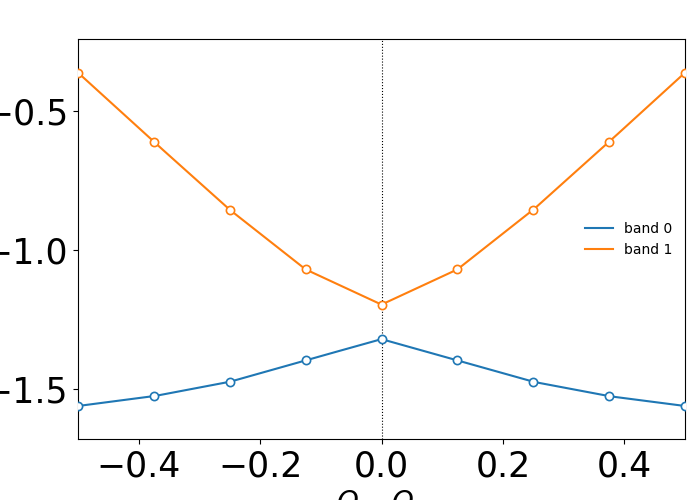

In [57]:
folder_name = r"qwz_representative_M0.6"
#marker_spec = MarkerSpec(mode = MarkerMode.HIGHSYM)
#marker_spec = MarkerSpec(mode = MarkerMode.ZEROS, n=2 , marker="x")# , size=20)
#marker_spec = [MarkerSpec(mode = MarkerMode.MANUAL, points=np.array([[25*4*np.pi/32,7*4*np.pi/32],[7*4*np.pi/32,25*4*np.pi/32]]), marker = "x"),
#              MarkerSpec(mode = MarkerMode.MANUAL, points=np.array([[25*4*np.pi/32,26*4*np.pi/32],[7*4*np.pi/32,6*4*np.pi/32]]), marker = "o", size=20)]
#marker_spec = [MarkerSpec(mode = MarkerMode.HIGHSYM),MarkerSpec(mode = MarkerMode.ZEROS, n=4), MarkerSpec(mode = MarkerMode.MANUAL, points=np.array([[1,2]]), marker = "o")]
#marker_spec = [MarkerSpec(mode = MarkerMode.EMAX, n=None, color="black", marker=":",size=1),MarkerSpec(mode = MarkerMode.EMAX, n=0, color="red", marker=":",size=1)]#,
              #MarkerSpec(mode = MarkerMode.EMAX, n=1, color="green", marker=":",size=1)]
marker_spec = None
zoom_spec = BandZoomSpec((8,8), direction=(1,0))
#zoom_spec=None
ax_spec = AxesDisplaySpec(
    show_title= False,
    axis_label_size = 20,
    tick_label_size=25,
)
LoadGraphSingle("Data", folder_name,GraphProtocol.EQZoom,band = [0,1] , 
                            p_ind = (9,10),out_folder = None, marker_spec = marker_spec, 
                            var = None, zoom_spec=zoom_spec, axes_spec = ax_spec)

In [443]:
load_folder = r"Data\haldane_phi0.838_M0.303"
Fnfile = os.path.join(load_folder, f"F[{band}].npy")
Fn = np.load(Fnfile, mmap_mode='r')
Fn_p = Fn[:,:,1,18]
#print(Fn.shape)
eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
eQ = np.load(eQfile, mmap_mode='r')
print(eQ.shape)
#configfile = os.path.join(load_folder, "config.yml")
#cfg = GetConfig(configfile)
#GraphFromConfig(np.abs(Fn_p),cfg,GraphProtocol.Test,load_folder)

(28, 28, 28, 28)
(28, 28, 784)


In [155]:
##BC TEST
case = GraphProtocol.ExcBC
load_folder = r"Data\Geometry\qwz_NQ48"
out_folder = load_folder
band = 0
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(configfile)
#Proj, Vprod, WF
prefix = os.path.join(load_folder, f"Proj_U[{band}]BC_C_")
pattern = glob.escape(prefix) + "*.npy"   # <-- key fix
UBCfiles = glob.glob(pattern)
if not UBCfiles:
    raise FileNotFoundError(f"No matching file {pattern}")
UBCfilename = UBCfiles[0]
# extract C from filename
m = re.search(r"BC_C_(.+)\.npy$", os.path.basename(UBCfilename))
if not m:
    raise ValueError(f"Couldn't parse C from: {UBCfilename}")
UnC = complex(m.group(1))   # works for real or complex strings
C = round(UnC.real, 3)
data = np.load(UBCfilename)
marker_spec = None
GraphFromConfig(data,cfg,case,out_folder,band,p_ind=(0,0),C=C, marker_spec = marker_spec)

NameError: name 'glob' is not defined

### F winding

In [452]:
#gauge fix F
parent_folder = "Data"
folder_name = r"haldane_phi0.838_M0.303"
#qwz_representative, QWZ_CarolinaRequest\qwz_M0.7
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/gauged"
os.makedirs(out_folder, exist_ok=True)
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(f"{configfile}")
#F_keep_file = os.path.join(load_folder, "F_keep.npy")
#F_keep = np.load(F_keep_file, mmap_mode='r')
#n=0
F0_file = os.path.join(load_folder, "F[0].npy")
F0 = np.load(F0_file, mmap_mode='r')
NQ = cfg["NQ"]
F0_flat = F0.reshape(NQ, NQ, NQ * NQ)
Fn_gauged = GaugeFixAllFs(F0_flat)
print(Fn_gauged.shape)
data_path = f"{out_folder}/F0_Gauged.npy"
np.save(data_path,Fn_gauged)

(28, 28, 28, 28)


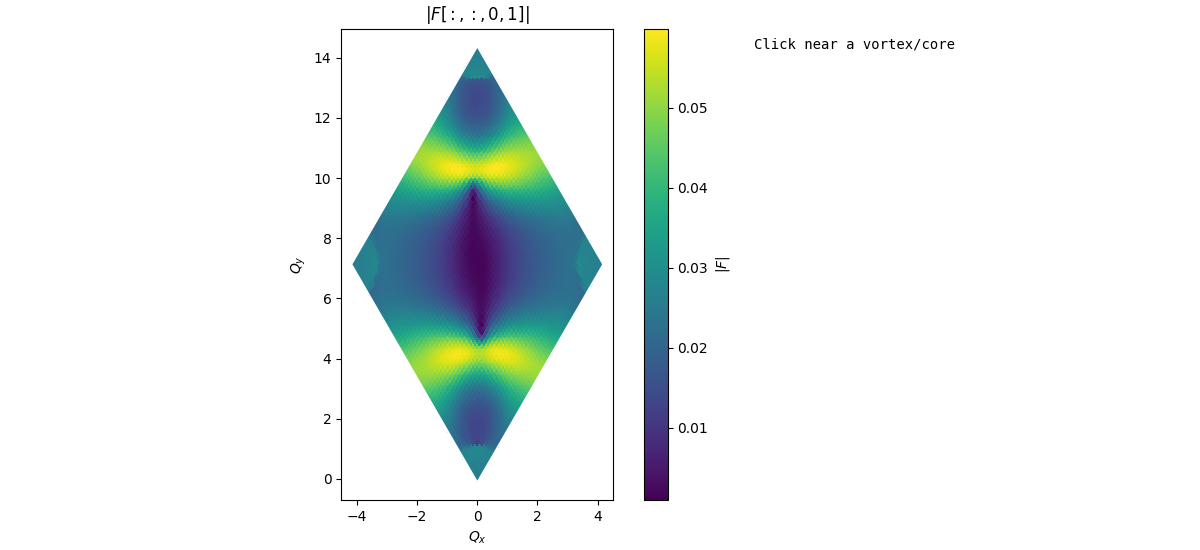

In [39]:
#Winding
import importlib
from project.hexagonal_winding_explorer import InteractiveWindingExplorer as IWE
parent_folder = "Data"
folder_name = r"NQ59"
#folder_name = "2026-06-16_15-16-13"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}"
Fn_file = os.path.join(load_folder, f"F.npy")
#Fn_file = os.path.join(load_folder, f"F[0].npy")
#Fn_file = os.path.join(load_folder, f"Z_px10_py9.npy")
F = np.load(Fn_file, mmap_mode='r')
p= (0,1)
cfg = GetConfig(f"{load_folder}/config.yml")
[b1,b2] = cfg["rec_vec"]
explorer = IWE(
    F[:,:,p[0],p[1]],
    radii=(1,2, 3, 4, 5),
    search_radius=5,
    p=p,
    config=cfg,
    lattice_type="hexagonal",
    b1=b1,
    b2=b2,
)
#explorer = InteractiveWindingExplorer(
#    F[:,:,p[0],p[1]],
#    radii=[1, 2, 3, 4, 5],
#    search_radius=6,
#    p=p
#    
#)
#
#plt.show()

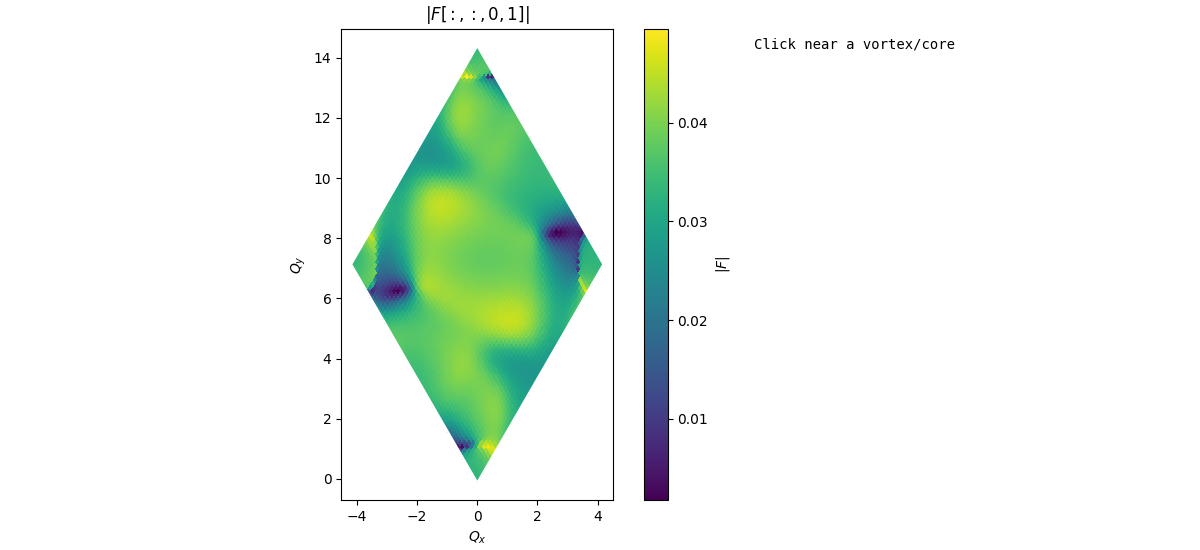

In [49]:
import QMeshWinding
#newF, info = QMeshWinding.GaugeFixF(F,cfg)
explorer = IWE(
    newF[:,:,4,18],
    radii=(1,2, 3, 4, 5),
    search_radius=5,
    p=p,
    config=cfg,
    lattice_type="hexagonal",
    b1=b1,
    b2=b2,
)

## Process Multi

In [18]:
def load_folder_paths(read_directories):
    all_dirs = []
    for read_directory in read_directories:
        txt_path = read_directory / "folders.txt"
        if not txt_path.exists():
            print(f"Missing folders.txt: {txt_path}")
            continue

        with open(txt_path, "r") as f:
            all_dirs.extend(
                read_directory / line.strip()
                for line in f
                if line.strip()
            )

    return all_dirs

### F all ps

In [422]:
folder_name = r"Haldane_phi_M_Subset\haldane_phi0.838_M0.303"
#QWZ_M_t\qwz_M0.0_t0.5
#qwz_M_t_U0.186\qwz_M0.0_t0.5
#QWZ_M_t\qwz_M0.522_t0.5
#marker_spec = MarkerSpec(mode = MarkerMode.ZEROS)
marker_spec = None
for px in range(27):
    plt.close('all')
    for py in range(27):
        LoadGraphSingle("Data", folder_name,GraphProtocol.AbsF2D,band = 0 , 
                        p_ind = (px,py),out_folder = f"Data/{folder_name}/F_all_ps", marker_spec = marker_spec)
plt.close('all')

C:\Users\theof\AppData\Local\Temp\ipykernel_14424\3203831243.py:7: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



### create graphs for folder list

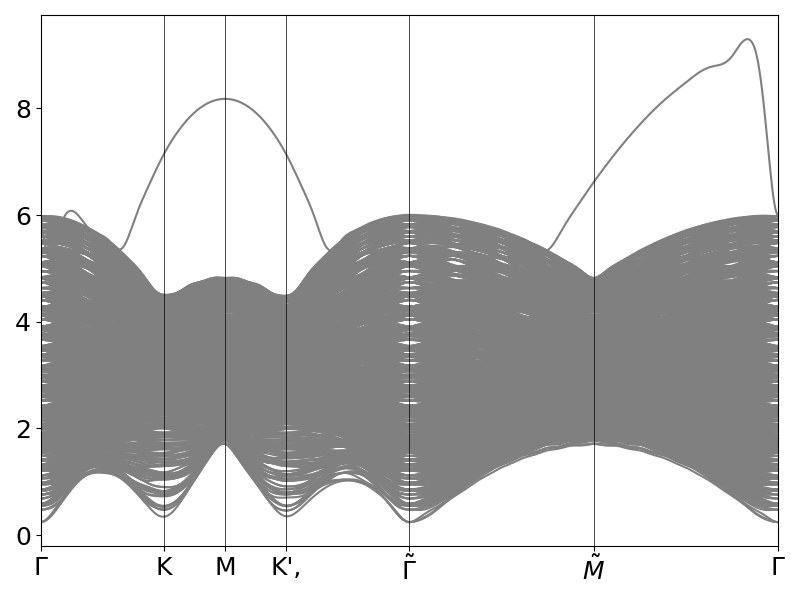

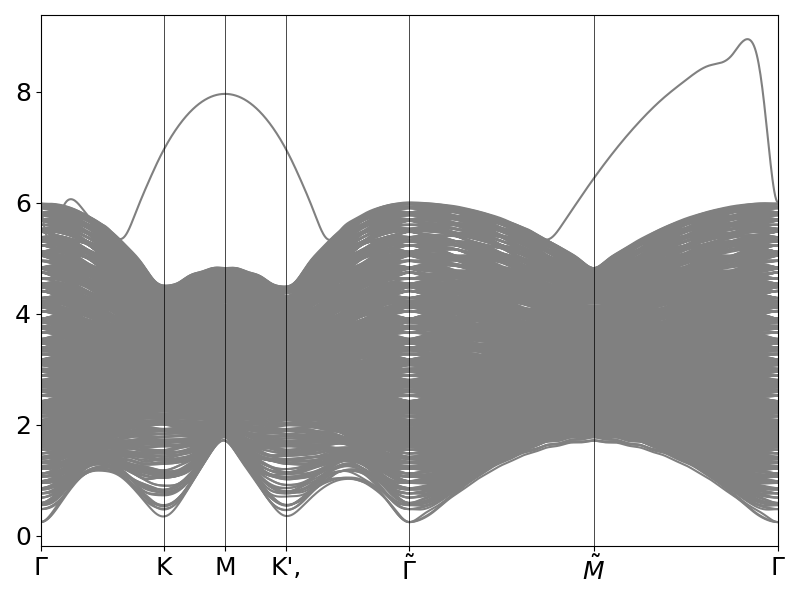

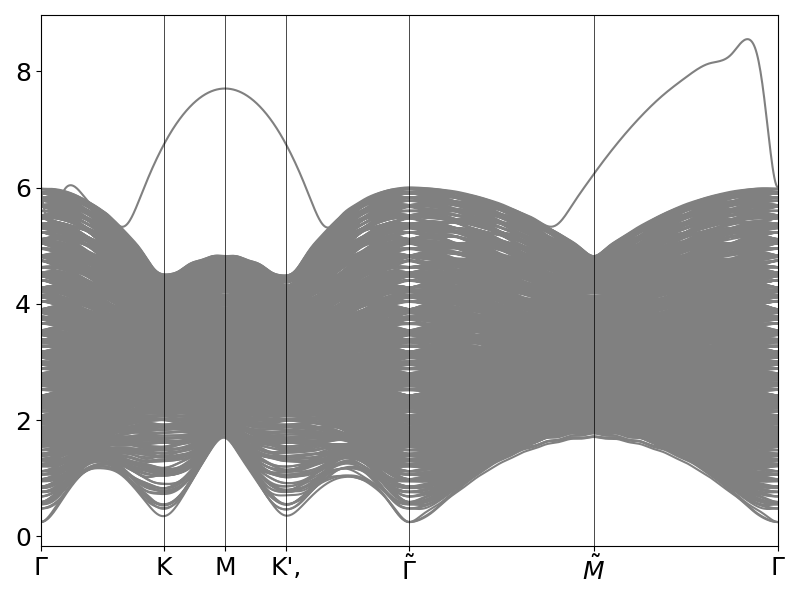

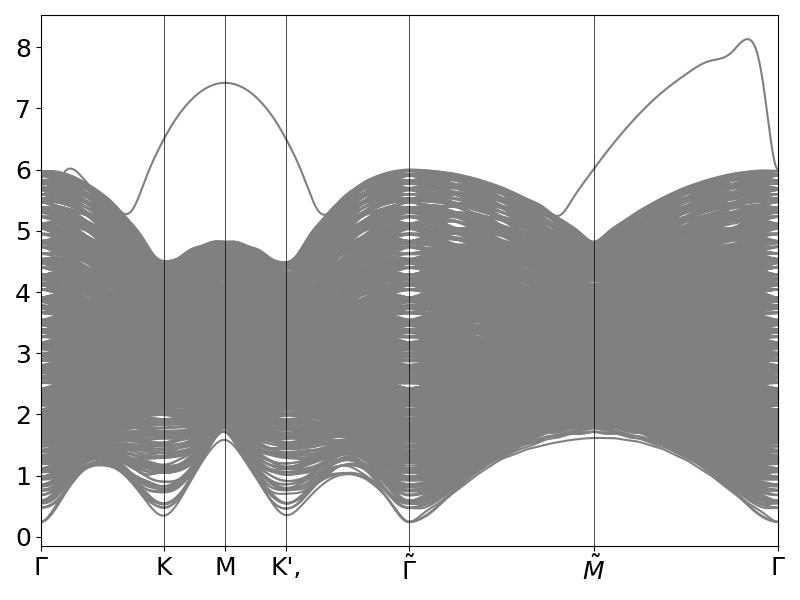

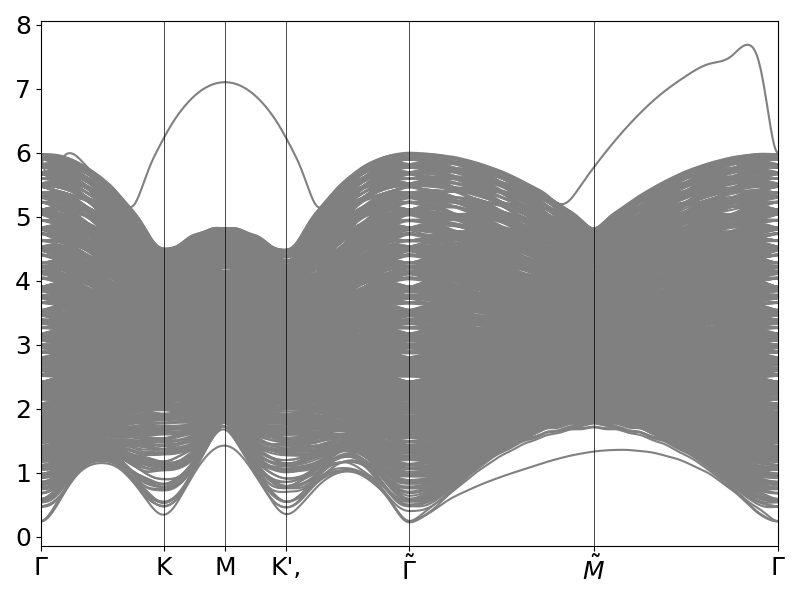

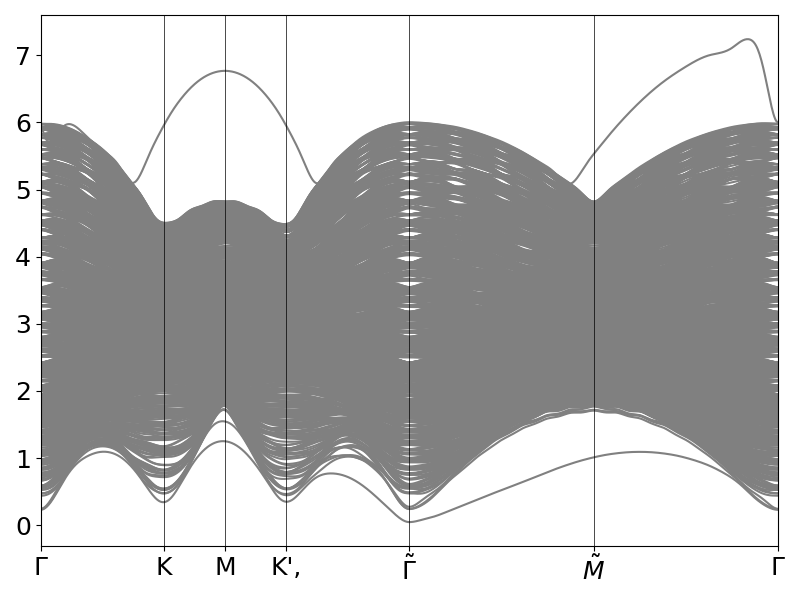

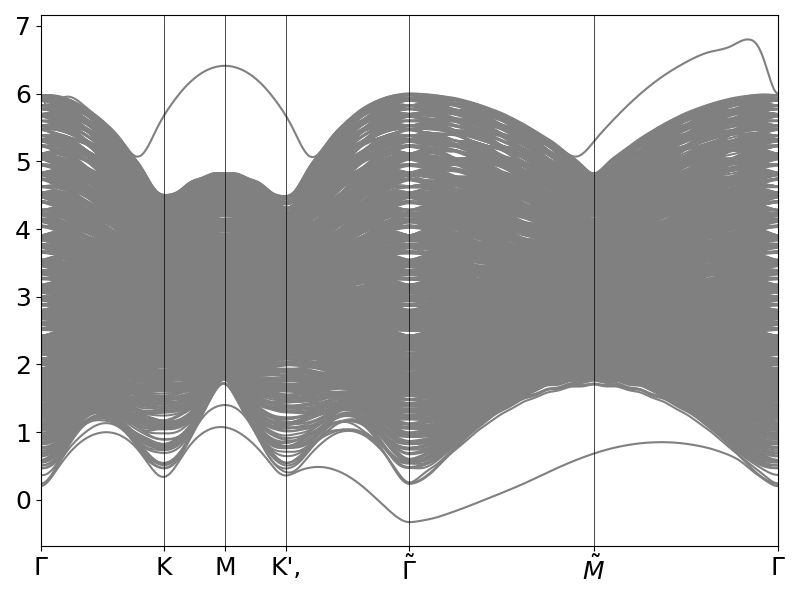

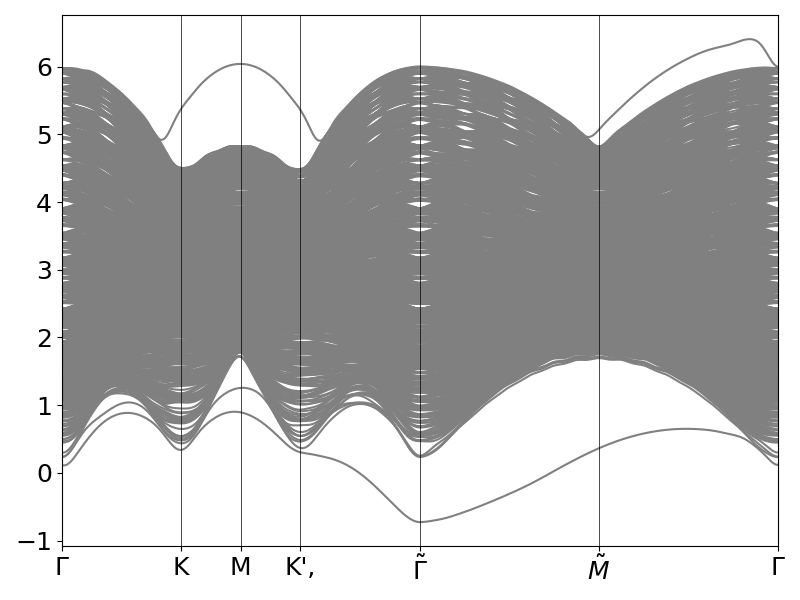

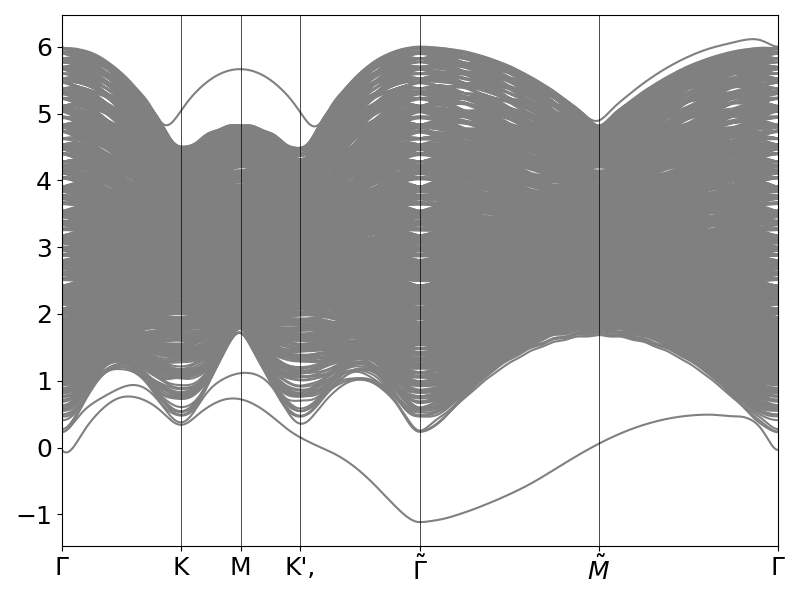

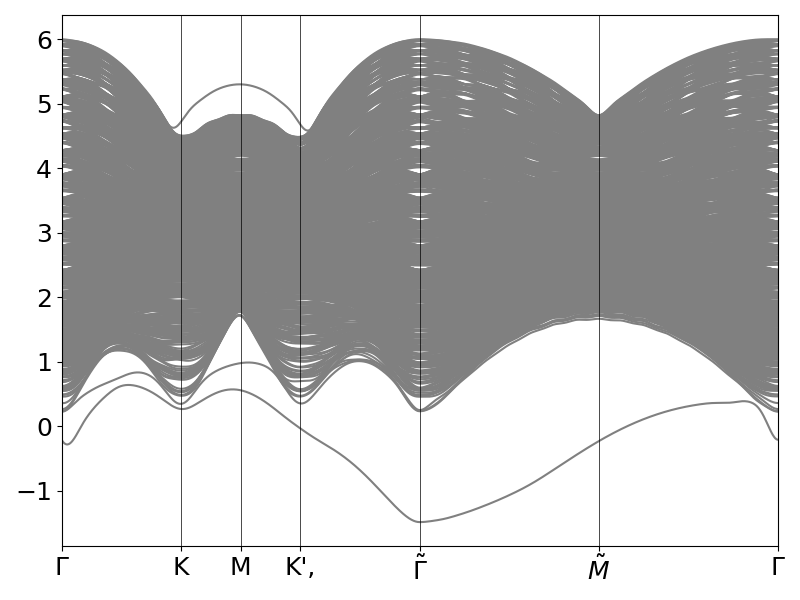

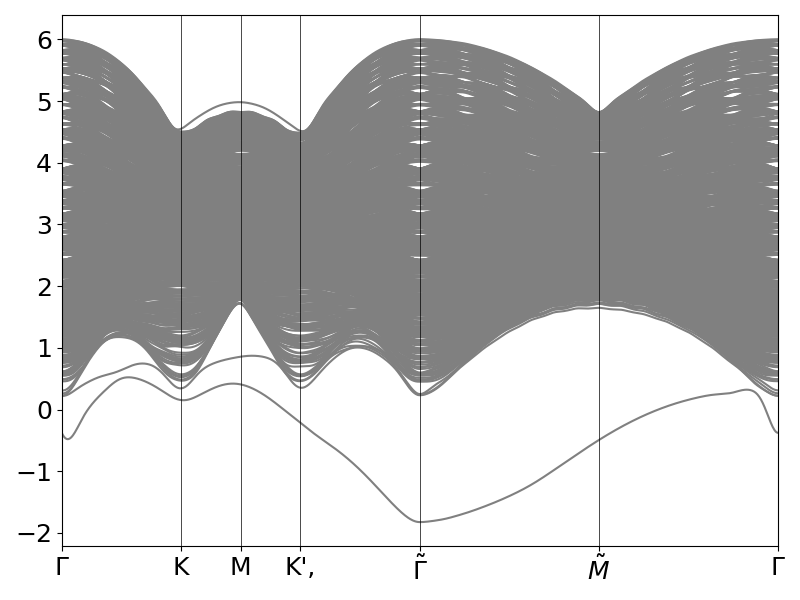

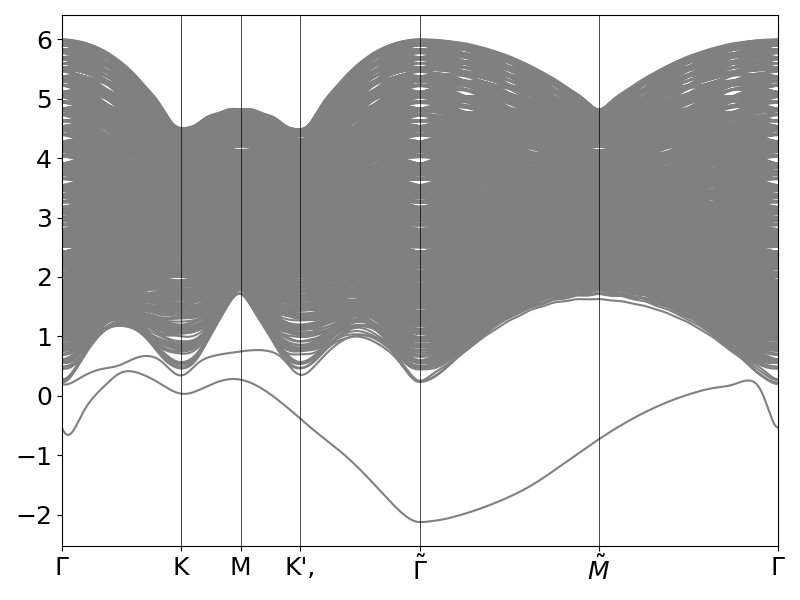

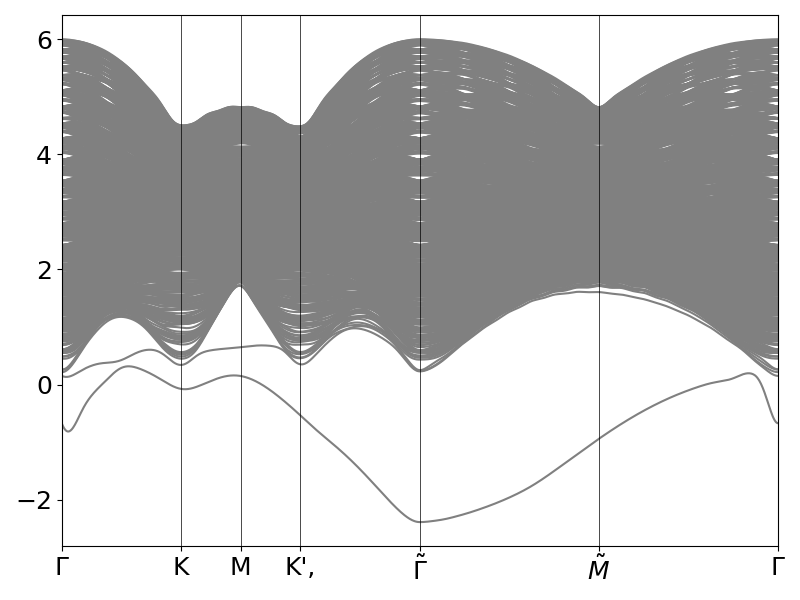

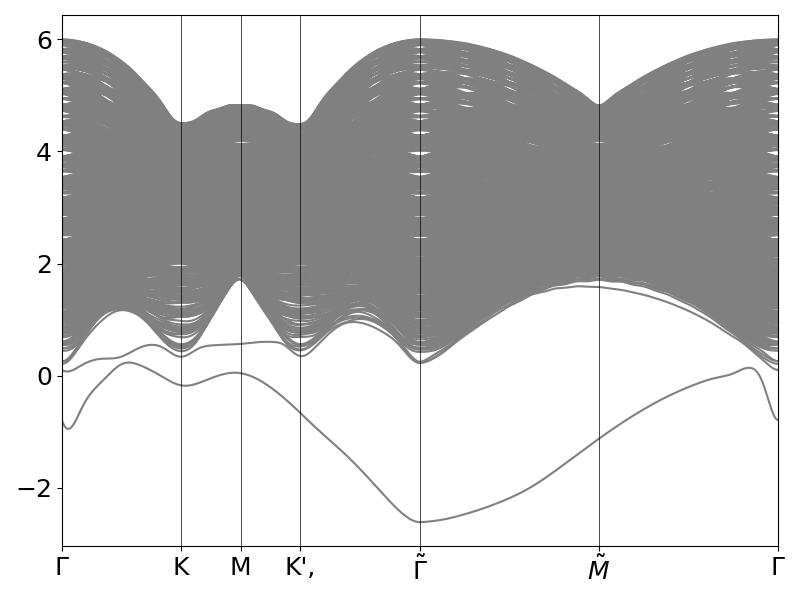

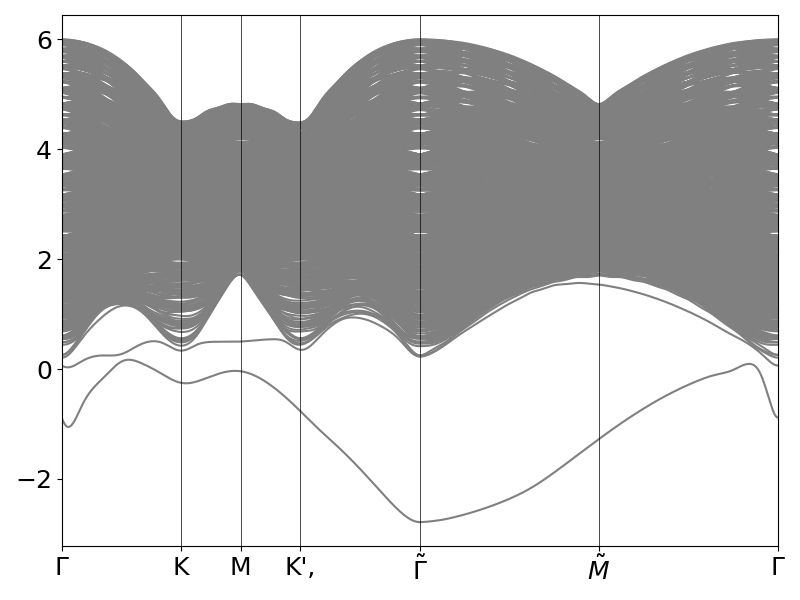

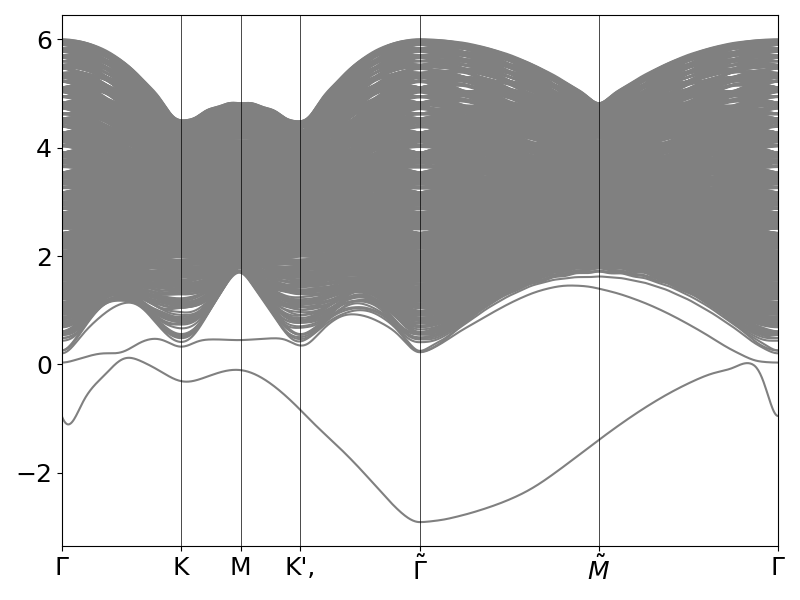

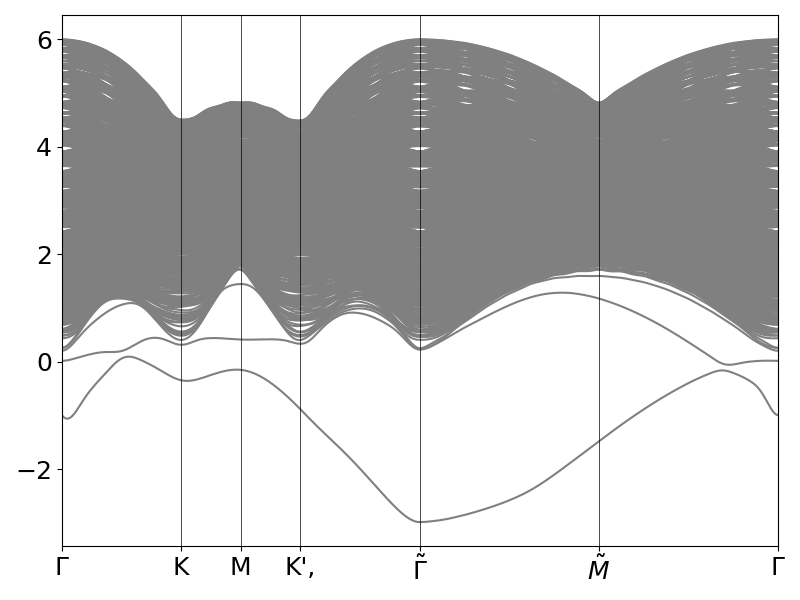

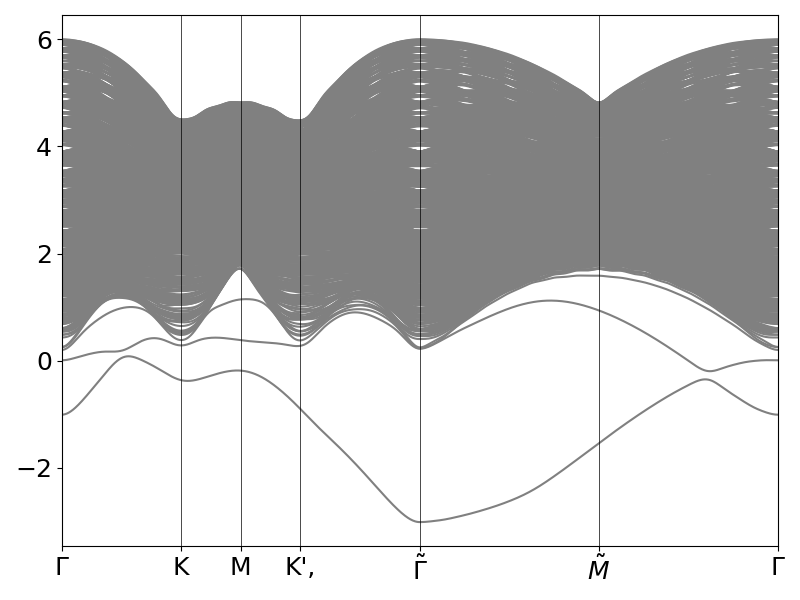

In [279]:
parent_folders = [Path("Data/haldane_r_U0.5"),]
folder_names = load_folder_paths(parent_folders)
out_folder = Path("Images/Explorations/haldane_r_U0.5")
for i,folder_name in enumerate(folder_names):
    new_fname = folder_name.relative_to("Data")
    LoadGraphSingle("Data",new_fname,GraphProtocol.EQHighSym,out_folder=out_folder,var=i)

### Parameter scan

In [344]:
def ExtractCValues(
    directories,
    output_csv,
    bands=(0,),
    param1_name="M",
    param2_name="t",
    htype="qwz",
    tol=1e-3,
):
    dir_pattern = re.compile(
        rf"{htype}_{param1_name}([+-]?\d+(?:\.\d+)?)_{param2_name}([+-]?\d+(?:\.\d+)?)",
        re.IGNORECASE,
    )

    rows = []

    for band in bands:
        bc_pattern = re.compile(rf"^(?:Vprod_)?U\[{band}\]BC_C_(.+)\.npy$")

        for directory in directories:
            directory = Path(directory)

            if not directory.exists():
                print(f"Skipping missing directory: {directory}")
                continue

            match_dir = dir_pattern.search(directory.name)
            if match_dir is None:
                print(f"Could not parse {param1_name},{param2_name} from {directory.name}")
                continue

            param1 = float(match_dir.group(1))
            param2 = float(match_dir.group(2))
            is_touching = None

            for file_path in directory.iterdir():
                if not file_path.is_file():
                    continue

                match_bc = bc_pattern.match(file_path.name)
                if match_bc:
                    # Calculate only once per directory and band.
                    if is_touching is None:
                        touches_next = CheckTouching(directory, band, band + 1, tol=tol)
                        touches_previous = (CheckTouching(directory, band, band - 1,
                                                          tol=tol)if band > 0 else False)
                        is_touching = bool(touches_next or touches_previous)

                    C = np.round(float(match_bc.group(1)), 3)
                    rows.append(
                        (str(directory), param1, param2, C, band, is_touching)
                    )

    output_csv = Path(output_csv)
    output_csv.parent.mkdir(parents=True, exist_ok=True)

    df = pd.DataFrame(
        rows,
        columns=[
            "directory", param1_name, param2_name, "C", "band", "IsTouching"
        ],
    )
    df.to_csv(output_csv, index=False)
    return df

In [82]:
import os

root_dir = r"Data\qwz_M_t_U0.186_Subset"

for root, dirs, files in os.walk(root_dir, topdown=False):
    for dirname in dirs:
        path = os.path.join(root, dirname)

        # Remove directory only if it's empty
        if not os.listdir(path):
            os.rmdir(path)
            print(f"Deleted: {path}")

In [376]:
data_folder = Path("Data")
read_folder = "Haldane_phi_M_Subset"
read_directories = [
    data_folder / "Haldane_phi_M_Subset", 
]
folder_names = load_folder_paths(read_directories)
df = ExtractCValues(
    folder_names,
    data_folder / read_folder / "scanC_tol0.017.csv",
    bands=[0],
    param1_name="phi",
    param2_name="M",
    htype="haldane",
    tol= 0.017
)

In [62]:
data_folder = Path("Data")

df = pd.read_csv(data_folder / "Haldane_phi_M_Subset" / "scanC.csv")
#df = df[df["M"].abs() <= 1.5].copy()

In [75]:
def PlotScan(
    df,
    x_param,
    y_param,
    color_param="C",
    band=None,
    sum_over_bands=False,
    log_ticks=False,
    show_values=False,
    figsize=(7, 6),
    dpi=200,
    cmap="coolwarm",
    marker="o",
    markersize=200,
    axis_labels=None,
    save_path=None,
):
    """
    Plot a parameter scan.

    Parameters
    ----------
    df : pandas.DataFrame
    x_param, y_param : str
        Column names for the x and y axes.
    color_param : str
        Column used for coloring.
    band : int or None
        If not None, select only this band.
    sum_over_bands : bool
        If True, sum color_param over all bands for each (x_param, y_param).
    log_ticks : bool
        If True, use evenly spaced x positions with scientific-notation labels.
    show_values : bool
        If True, write the color value on each dot.
    """

    df_plot = df.copy()

    # Remove rows whose band is touching another band
    if "IsTouching" in df_plot.columns:
        df_plot = df_plot[
            ~df_plot["IsTouching"].fillna(False).astype(bool)
        ].copy()
        
    if band is not None:
        df_plot = df_plot[df_plot["band"] == band].copy()

    if sum_over_bands:
        df_plot = (
            df_plot
            .groupby([x_param, y_param], as_index=False)[color_param]
            .sum()
        )

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

    if log_ticks:
        x_vals = np.sort(df_plot[x_param].unique())
        x_map = {v: i for i, v in enumerate(x_vals)}
        x = df_plot[x_param].map(x_map)
    else:
        x = df_plot[x_param]

    color_values = df_plot[color_param].to_numpy()
    color_limit = np.nanmax(np.abs(color_values))
    color_limit = 4
    
    sc = ax.scatter(
        x,
        df_plot[y_param],
        c=df_plot[color_param],
        cmap=cmap,
        vmin = -color_limit,
        vmax = color_limit,
        s=markersize,
        marker=marker,
    )

    if show_values:
        for xi, yi, ci in zip(x, df_plot[y_param], df_plot[color_param]):
            display_value = 0 if np.isclose(ci, 0) else ci
            ax.text(
                xi,
                yi,
                f"{display_value:g}",
                ha="center",
                va="center",
                fontsize=8,
                color="black",
                path_effects=[pe.withStroke(linewidth=2, foreground="white")],
            )

    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label(axis_labels.get(color_param, color_param) if axis_labels else color_param)

    if axis_labels is None:
        axis_labels = {}

    ax.set_xlabel(axis_labels.get(x_param, x_param))
    ax.set_ylabel(axis_labels.get(y_param, y_param))

    if log_ticks:
        ax.set_xticks(range(len(x_vals)))

        labels = []
        for val in x_vals:
            if np.isclose(val, 0):
                labels.append(r"$0$")
            else:
                exponent = int(np.floor(np.log10(abs(val))))
                mantissa = val / 10**exponent

                if np.isclose(mantissa, 1):
                    labels.append(rf"$10^{{{exponent}}}$")
                else:
                    if np.isclose(mantissa, round(mantissa)):
                        mantissa = int(round(mantissa))
                    labels.append(rf"${mantissa}\times10^{{{exponent}}}$")

        ax.set_xticklabels(labels)
    ###TMP###
    #t_vals = np.linspace(df["t"].min(), df["t"].max(), 200)
    #ax.plot(
    #    t_vals, #x
    #    0.5 *t_vals, #y
    #    color="black",
    #    linestyle="--",
    #    linewidth=2,
    #    label=r"$M=0.5t$",
    #)
#
    #ax.legend()
    # Haldane single-particle phase boundaries
    phi_vals = np.linspace(df_plot[x_param].min(), df_plot[x_param].max(), 500)
    
    Mcrit = 3 * np.sqrt(3) * 0.1 * np.sin(phi_vals)
    
    ax.plot(
        phi_vals,
        Mcrit,
        color="red",
        linestyle=":",
        linewidth=2,
        label=r"$M=+3\sqrt{3}\,t_2\sin\phi$"
    )
    
    ax.plot(
        phi_vals,
        -Mcrit,
        color="blue",
        linestyle=":",
        linewidth=2,
        label=r"$M=-3\sqrt{3}\,t_2\sin\phi$"
    )
    ax.legend()
    ###ENDTMP###
    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=dpi)

    return fig, ax

axis_labels = {
    "M": r"$M$",
    "vx": r"$V$",
    "vd": r"$W$",
    "U": r"$W$",
    "C": r"$C$",
}

(<Figure size 1400x1200 with 2 Axes>, <Axes: xlabel='phi', ylabel='$M$'>)

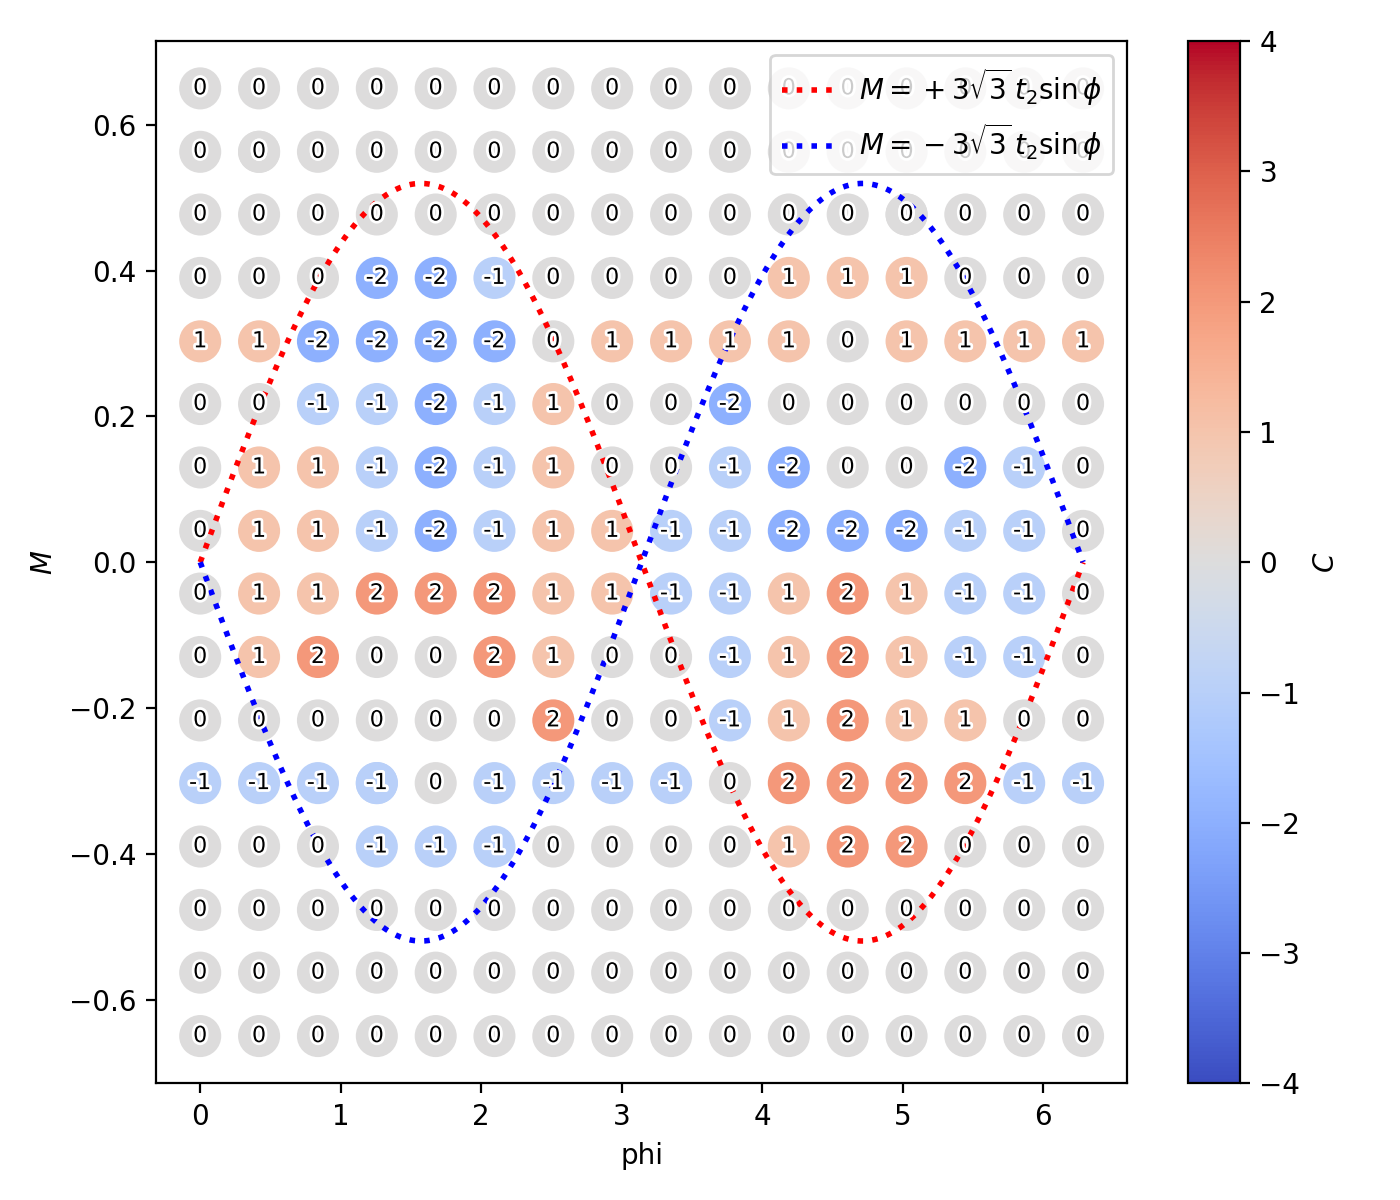

In [76]:
band_to_plot = 0

#df["band"] = 0##tmp
PlotScan(
    df,
    x_param="phi",
    y_param="M",
    band=band_to_plot,
    sum_over_bands= False,
    log_ticks=False,
    show_values=True,
    axis_labels=axis_labels,
    save_path=f"Images/Explorations/Haldane_phi_M/C_(phi,M)_line.png",
)


In [83]:
data_folder = Path("Data")
read_directories = [
    data_folder / "QWZ1_U10_1,vx",
]
folder_names = load_folder_paths(read_directories)
df = ExtractBCValues(
    folder_names,
    data_folder / "QWZ1_U10_1,vx" / "scan_multiband.csv",
    bands=[0, 1, 2],
    param1_name="M",
    param2_name="vx",
    htype="qwz",
)

df_sum = (
    df.groupby(["M", "vx"], as_index=False)["C"]
    .sum()
)

counts = (
    df_sum["C"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(6,4), dpi=200)

x = np.arange(len(counts))

ax.bar(x, counts.values)

ax.set_xticks(x)
ax.set_xticklabels(counts.index)

ax.set_xlabel(r"$\sum_n C_n$")
ax.set_ylabel("Count")

output_path = Path("Images/Explorations/QWZ_M_vx/sumC_histogram.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=200)

plt.show()

Missing folders.txt: Data\QWZ1_U10_1,vx\folders.txt
Missing folders.txt: Data\QWZ_U10_1,vx\folders.txt


### Move graphs from data folder to Images/Exploration

In [ ]:
import shutil
import re

def copy_bc_png(src_folder, dst_folder, new_filename):
    # Ensure the output filename ends with .png later
    new_filename = new_filename.rstrip(".png")

    # Regex to match BC C=(real+imagj).png
    pattern = re.compile(r"^BC C=\(([-+]?\d*\.?\d+)[-+]\d*\.?\d+j\)\.png$")

    # Absolute paths
    src_folder = os.path.abspath(src_folder)
    dst_folder = os.path.abspath(dst_folder)
    os.makedirs(dst_folder, exist_ok=True)

    # Search for matching file
    for filename in os.listdir(src_folder):
        match = pattern.match(filename)
        if match:
            real_part = match.group(1)  # Extract real number as string

            # Create output filename
            final_name = f"{new_filename}_C={real_part}.png"

            src_path = os.path.join(src_folder, filename)
            dst_path = os.path.join(dst_folder, final_name)

            shutil.copy2(src_path, dst_path)
            return final_name  # Success

    return None  # No matching file found

def copy_energy_png(src_folder, dst_folder, new_filename):
    # Ensure ".png" extension on new filename
    if not new_filename.lower().endswith(".png"):
        new_filename += ".png"

    # Absolute paths
    src_folder = os.path.abspath(src_folder)
    dst_folder = os.path.abspath(dst_folder)

    # Create destination folder if needed
    os.makedirs(dst_folder, exist_ok=True)

    # Look for the first Energy*.png file
    for filename in os.listdir(src_folder):
        if filename.startswith("Energy") and filename.endswith(".png"):
            src_path = os.path.join(src_folder, filename)
            dst_path = os.path.join(dst_folder, new_filename)

            shutil.copy2(src_path, dst_path)
            return new_filename  # success

    return None  # no file found

# misc

In [94]:
def MakeFoldersTxt(directory):
    directory = Path(directory)

    names = sorted(
        file.stem
        for file in directory.iterdir()
        if file.is_file() and file.suffix.lower() == ".yml"
    )

    output_path = directory / "folders.txt"
    output_path.write_text("\n".join(names), encoding="utf-8")

    print(f"Saved {len(names)} names to {output_path}")

MakeFoldersTxt(r"configs\qwz_M_t(2)")

Saved 276 names to configs\qwz_M_t(2)\folders.txt


In [ ]:
def add_title_to_image(image_path, title, font_size=40, padding=10):
    image = Image.open(image_path)
    width, height = image.size

    # Height for the title space, which includes padding
    title_height = font_size + 2 * padding

    # Create a new image with extra space for the title (white background)
    new_image = Image.new("RGB", (width, height + title_height), "white")

    # Paste the original image below the title space
    new_image.paste(image, (0, title_height))  # (0, title_height) places the image below the title area

    # Draw the title
    draw = ImageDraw.Draw(new_image)

    try:
        # Attempt to load a font, otherwise fallback to default
        font = ImageFont.truetype("arial.ttf", font_size)
    except IOError:
        font = ImageFont.load_default()  # Fallback to default if Arial is missing

    # Use textbbox() to get text size
    bbox = draw.textbbox((0, 0), title, font=font)
    text_width = bbox[2] - bbox[0]
    text_height = bbox[3] - bbox[1]

    # Center the text within the title space
    text_x = (width - text_width) // 2  # Horizontally center
    text_y = (title_height - text_height) // 2  # Vertically center with padding

    # Draw the title in black for visibility
    draw.text((text_x, text_y), title, fill="black", font=font)

    return new_image

In [ ]:
from pathlib import Path
import os
import re
from PIL import Image

def MakeGifs(source_path):
    # Define input and output folders
    image_folder = Path("Images") / source_path
    output_folder = Path("Gifs") / source_path
    os.makedirs(output_folder, exist_ok=True)

    if not image_folder.is_dir():
        print("Image folder does not exist:", image_folder)
        return

    # Get all PNG files
    png_files = [p for p in image_folder.glob("*.png") if p.is_file()]
    if not png_files:
        print("No PNG images found in", image_folder)
        return

    # Patterns:
    #  1) U=#.png
    simple_pattern = re.compile(r"^U=([+-]?\d*\.?\d+)\.png$")
    #  2) U=#_C=#.png
    bc_pattern = re.compile(r"^U=([+-]?\d*\.?\d+)_C=([+-]?\d*\.?\d+)\.png$")
    #  3) F_0_p{i}_{j}.png
    f_pattern = re.compile(r"^F_0_p(\d+)_(\d+)\.png$")

    simple_files = []  # {"u_val", "u_str", "path"}
    bc_files = []      # {"u_val", "u_str", "c_str", "path"}
    f_files = []       # {"i", "j", "path"}

    for path in png_files:
        fname = path.name

        m_f = f_pattern.match(fname)
        if m_f:
            i, j = int(m_f.group(1)), int(m_f.group(2))

            # Keep only i,j in range(64)
            if 0 <= i < 64 and 0 <= j < 64:
                f_files.append({"i": i, "j": j, "path": path})
            else:
                print(f"Skipping {fname}: i or j out of range(64)")
            continue

        m_bc = bc_pattern.match(fname)
        if m_bc:
            u_str, c_str = m_bc.group(1), m_bc.group(2)
            try:
                u_val = float(u_str)
            except ValueError:
                print(f"Could not parse U value in {fname}, skipping.")
                continue
            bc_files.append({
                "u_val": u_val,
                "u_str": u_str,
                "c_str": c_str,
                "path": path
            })
            continue

        m_simple = simple_pattern.match(fname)
        if m_simple:
            u_str = m_simple.group(1)
            try:
                u_val = float(u_str)
            except ValueError:
                print(f"Could not parse U value in {fname}, skipping.")
                continue
            simple_files.append({
                "u_val": u_val,
                "u_str": u_str,
                "path": path
            })
        else:
            print("Skipping file with unexpected name pattern:", fname)

    # Decide which mode we're in
    if f_files:
        mode = "F"
        files = sorted(f_files, key=lambda d: (d["i"], d["j"]))  # loop over i, then j
    elif bc_files:
        mode = "BC"
        files = sorted(bc_files, key=lambda d: d["u_val"])
    elif simple_files:
        mode = "simple"
        files = sorted(simple_files, key=lambda d: d["u_val"])
    else:
        print("No files matched the expected patterns.")
        return

    processed_images = []
    for item in files:
        img_path = item["path"]

        if mode == "F":
            img = Image.open(img_path)
        elif mode == "BC":
            title = f"C={item['c_str']}"
            img = add_title_to_image(img_path, title)
        else:
            title = f"U={item['u_str']}"
            img = add_title_to_image(img_path, title)

        processed_images.append(img)

    if not processed_images:
        print("No images processed, GIF not created.")
        return

    # Output GIF filename depending on mode
    if mode == "F":
        gif_name = "F_0_p.gif"
    elif mode == "BC":
        gif_name = "BC.gif"
    else:
        gif_name = "Energy_Bands.gif"

    output_gif_path = output_folder / gif_name

    processed_images[0].save(
        output_gif_path,
        save_all=True,
        append_images=processed_images[1:],
        duration=100,
        loop=0,
    )

    print("GIF saved as:", output_gif_path)

In [ ]:
from pathlib import Path
import os
import re
from PIL import Image
import imageio.v2 as imageio
import numpy as np


def MakeVideos(source_path, fps=20):
    # Define input and output folders
    image_folder = Path("Images") / source_path
    output_folder = Path("Videos") / source_path
    os.makedirs(output_folder, exist_ok=True)

    if not image_folder.is_dir():
        print("Image folder does not exist:", image_folder)
        return

    # Get all PNG files
    png_files = [p for p in image_folder.glob("*.png") if p.is_file()]
    if not png_files:
        print("No PNG images found in", image_folder)
        return

    # Patterns
    simple_pattern = re.compile(r"^U=([+-]?\d*\.?\d+)\.png$")
    bc_pattern = re.compile(r"^U=([+-]?\d*\.?\d+)_C=([+-]?\d*\.?\d+)\.png$")
    f_pattern = re.compile(r"^F_0_p(\d+)_(\d+)\.png$")
    vx_pattern = re.compile(r"^M([+-]?\d*\.?\d+)_vx([+-]?\d*\.?\d+)\.png$")

    simple_files = []
    bc_files = []
    f_files = []
    vx_files = []

    for path in png_files:
        fname = path.name

        m_f = f_pattern.match(fname)
        if m_f:
            i, j = int(m_f.group(1)), int(m_f.group(2))
            if 0 <= i < 64 and 0 <= j < 64:
                f_files.append({"i": i, "j": j, "path": path})
            else:
                print(f"Skipping {fname}: i or j out of range(64)")
            continue

        m_bc = bc_pattern.match(fname)
        if m_bc:
            u_str, c_str = m_bc.group(1), m_bc.group(2)
            try:
                u_val = float(u_str)
            except ValueError:
                print(f"Could not parse U value in {fname}, skipping.")
                continue
            bc_files.append({
                "u_val": u_val,
                "u_str": u_str,
                "c_str": c_str,
                "path": path
            })
            continue

        m_simple = simple_pattern.match(fname)
        if m_simple:
            u_str = m_simple.group(1)
            try:
                u_val = float(u_str)
            except ValueError:
                print(f"Could not parse U value in {fname}, skipping.")
                continue
            simple_files.append({
                "u_val": u_val,
                "u_str": u_str,
                "path": path
            })
        m_vx = vx_pattern.match(fname)
        if m_vx:
            m_str, vx_str = m_vx.group(1), m_vx.group(2)

            try:
                vx_val = float(vx_str)
            except ValueError:
                print(f"Could not parse vx value in {fname}, skipping.")
                continue
        
            vx_files.append({
                "vx_val": vx_val,
                "vx_str": vx_str,
                "path": path
            })
            continue
        else:
            print("Skipping file with unexpected name pattern:", fname)

    # Decide mode
    if f_files:
        mode = "F"
        files = sorted(f_files, key=lambda d: (d["i"], d["j"]))
    elif bc_files:
        mode = "BC"
        files = sorted(bc_files, key=lambda d: d["u_val"])
    elif simple_files:
        mode = "simple"
        files = sorted(simple_files, key=lambda d: d["u_val"])
    elif vx_files:
        mode = "VX"
        files = sorted(vx_files, key=lambda d: d["vx_val"])
    else:
        print("No files matched expected patterns.")
        return

    frames = []

    for item in files:
        img_path = item["path"]

        if mode == "F":
            img = Image.open(img_path)
        elif mode == "BC":
            title = f"C={item['c_str']}"
            img = add_title_to_image(img_path, title)
        elif mode == "VX":
            title = f"vx={item['vx_str']}"
            img = add_title_to_image(img_path, title)
        else:
            title = f"U={item['u_str']}"
            img = add_title_to_image(img_path, title)

        frames.append(np.array(img))

    if not frames:
        print("No frames collected, video not created.")
        return

    # Output filename
    if mode == "F":
        video_name = "F_0_p.mp4"
    elif mode == "BC":
        video_name = "BC.mp4"
    elif mode == "VX":
        video_name = "VX_scan.mp4"
    else:
        video_name = "Energy_Bands.mp4"

    output_video_path = output_folder / video_name

    imageio.mimsave(
        output_video_path,
        frames,
        fps=fps,
        codec="libx264",
        quality=8
    )

    print("Video saved as:", output_video_path)

In [ ]:
from pathlib import Path
from PIL import Image

def resize_pngs_in_folder(folder_path, size=(384, 464), overwrite=True):
    folder = Path(folder_path)

    for png_file in folder.glob("*.png"):
        try:
            with Image.open(png_file) as img:
                img = img.convert("RGB")  # ensure consistent format
                resized = img.resize(size, Image.LANCZOS)

                if overwrite:
                    resized.save(png_file)
                else:
                    new_path = png_file.with_name(png_file.stem + "_resized.png")
                    resized.save(new_path)

        except Exception as e:
            print(f"Skipping {png_file}: {e}")

In [ ]:
source_path= Path(r"Explorations\QWZ bands")
image_folder = Path("Images") / source_path
resize_pngs_in_folder(image_folder)

In [ ]:
source_path= Path(r"Explorations\QWZ bands")
#rs = ["0","1%32","1%16","1%8","1%4","1%2","1","2","4","8","16","32","inf"]
MakeVideos(source_path)

In [ ]:
def combine_gifs_side_by_side(gif1_path, gif2_path, output_path):
    gif1 = Image.open(gif1_path)
    gif2 = Image.open(gif2_path)

    # Convert all frames to RGB to avoid palette issues
    frames1 = [frame.convert("RGB") for frame in ImageSequence.Iterator(gif1)]
    frames2 = [frame.convert("RGB") for frame in ImageSequence.Iterator(gif2)]

    if len(frames1) != len(frames2):
        raise ValueError("GIFs must have the same number of frames")

    combined_frames = []

    for f1, f2 in zip(frames1, frames2):
        # Resize to match height
        if f1.height != f2.height:
            new_height = min(f1.height, f2.height)
            f1 = f1.resize(
                (int(f1.width * new_height / f1.height), new_height),
                Image.Resampling.LANCZOS
            )
            f2 = f2.resize(
                (int(f2.width * new_height / f2.height), new_height),
                Image.Resampling.LANCZOS
            )

        # Combine side by side
        combined_width = f1.width + f2.width
        combined = Image.new("RGB", (combined_width, f1.height))
        combined.paste(f1, (0, 0))
        combined.paste(f2, (f1.width, 0))
        combined_frames.append(combined)

    # Save as palette-based GIF ("P" mode)
    combined_frames = [frame.convert("P", palette=Image.ADAPTIVE) for frame in combined_frames]

    combined_frames[0].save(
        output_path,
        save_all=True,
        append_images=combined_frames[1:],
        duration=gif1.info.get("duration", 100),
        loop=0,
        disposal=2
    )

# Example usage
path1 = "Gifs/Explorations/Haldane Vd near 10/Energy/Energy_Bands.gif"
path2 = "Gifs/Explorations/Haldane Vd near 10/BC/BC.gif"
destination_path = "Showtime/Roni&Tobias meeting nov 2025/Haldane_Vd10_side_by_side.gif"
combine_gifs_side_by_side(
    Path(path1),
    Path(path2),
    Path(destination_path)
)


In [ ]:
from pathlib import Path
import os
import re
from PIL import Image, ImageOps, ImageDraw, ImageFont
import imageio.v2 as imageio
import numpy as np


def combine_images_side_by_side(left_img_path, right_img_path, left_label=None, right_label=None, pad=10):
    left_img = Image.open(left_img_path).convert("RGB")
    right_img = Image.open(right_img_path).convert("RGB")

    # Make both images the same height
    target_height = max(left_img.height, right_img.height)

    def resize_to_height(img, height):
        if img.height == height:
            return img
        new_width = int(img.width * (height / img.height))
        return img.resize((new_width, height), Image.Resampling.LANCZOS)

    left_img = resize_to_height(left_img, target_height)
    right_img = resize_to_height(right_img, target_height)

    # Optional labels area
    label_height = 30 if (left_label or right_label) else 0

    total_width = left_img.width + right_img.width + pad
    total_height = target_height + label_height

    canvas = Image.new("RGB", (total_width, total_height), "white")
    draw = ImageDraw.Draw(canvas)

    # Paste images
    y_offset = label_height
    canvas.paste(left_img, (0, y_offset))
    canvas.paste(right_img, (left_img.width + pad, y_offset))

    # Draw labels
    if left_label or right_label:
        font = ImageFont.load_default()
        if left_label:
            draw.text((10, 8), left_label, fill="black", font=font)
        if right_label:
            draw.text((left_img.width + pad + 10, 8), right_label, fill="black", font=font)

    return canvas


def MakeSideBySideVideoTwoFolders(source_folder, left, right, output_name="this&that.mp4", fps=20):
    # Define folders
    source = Path("Images") / source_folder
    left_folder = source / left
    right_folder = source / right
    output_folder = Path("Videos") / source_folder
    os.makedirs(output_folder, exist_ok=True)

    if not left_folder.is_dir():
        print("Left folder does not exist:", left_folder)
        return

    if not right_folder.is_dir():
        print("Right folder does not exist:", right_folder)
        return

    # Patterns
    left_pattern = re.compile(r"^F_0_p(\d+)_(\d+)\.png$")
    right_pattern = re.compile(r"^Overlap_p(\d+)_(\d+)\.png$")

    left_files = {}
    right_files = {}

    # Scan left folder
    for path in left_folder.glob("*.png"):
        m = left_pattern.match(path.name)
        if m:
            i, j = int(m.group(1)), int(m.group(2))
            if 0 <= i < 64 and 0 <= j < 64:
                left_files[(i, j)] = path

    # Scan right folder
    for path in right_folder.glob("*.png"):
        m = right_pattern.match(path.name)
        if m:
            i, j = int(m.group(1)), int(m.group(2))
            if 0 <= i < 64 and 0 <= j < 64:
                right_files[(i, j)] = path

    # Match pairs
    common_keys = sorted(set(left_files) & set(right_files))

    if not common_keys:
        print("No matching pairs found between folders.")
        return

    frames = []

    for i, j in common_keys:
        left_path = left_files[(i, j)]
        right_path = right_files[(i, j)]

        combined = combine_images_side_by_side(
            left_path,
            right_path,
            left_label=f"F_0_p{i}_{j}",
            right_label=f"Overlaps_p{i}_{j}"
        )

        frames.append(np.array(combined))

    if not frames:
        print("No frames collected, video not created.")
        return

    output_video_path = output_folder / output_name

    imageio.mimsave(
        output_video_path,
        frames,
        fps=fps,
        codec="libx264",
        quality=8
    )

    print("Video saved as:", output_video_path)

In [ ]:
MakeSideBySideVideoTwoFolders(
    source_folder = "QWZ/U5(-1,0)extended",
    left="F_all_ps",
    right="overlaps",
    fps=30
)

## Tests

### check missing folders in scan

In [209]:
from pathlib import Path

folder = Path("Data/qwz_M_t_U0.186_1")
txt_path = folder / "folders.txt"

# Read expected folder names
with open(txt_path, "r") as f:
    expected = {line.strip() for line in f if line.strip()}

# Get actual directories
actual_dirs = {
    p.name: p
    for p in folder.iterdir()
    if p.is_dir()
}

# Find missing and empty expected folders
missing = sorted(expected - actual_dirs.keys())
empty = sorted(
    name
    for name, path in actual_dirs.items()
    if name in expected and not any(path.iterdir())
)

if missing:
    print(f"Missing folders ({len(missing)}):")
    for name in missing:
        print(name)
else:
    print("No folders are missing.")

if empty:
    print(f"\nEmpty folders ({len(empty)}):")
    for name in empty:
        print(name)
else:
    print("\nNo expected folders are empty.")

No folders are missing.

No expected folders are empty.


In [199]:
# Delete the empty expected folders
for name in empty:
    empty_path = folder / name

    try:
        empty_path.rmdir()
        print(f"Deleted empty folder: {empty_path}")
    except OSError as error:
        print(f"Could not delete {empty_path}: {error}")

Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t0.5
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t0.682
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t0.864
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t1.045
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t1.227
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t1.591
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t1.773
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t1.955
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t2.136
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t2.318
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.1304_t2.5
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.2609_t0.5
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.2609_t1.045
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.2609_t1.227
Deleted empty folder: Data\qwz_M_t_U0.186_1\qwz_M-0.2609_t1.409
Deleted empty folder: Data\qwz_M_t_U0.186_1\qw

In [202]:
# Write missing folder names
missing_folders_path = folder / "missing_folders.txt"
#missing_cfg_path = folder / "missing_cfg.txt"
with open(missing_folders_path, "w") as f1:#, open(missing_cfg_path, "w") as f2:
    for name in missing:
        f1.write(f"{name}\n")
        #f2.write((f"configs/QWZ_scan7/{name}.yml") + "\n")
        #f2.write(f"{folder}/{name}.yml\n")

print(f"Wrote {len(missing)} missing folders to {missing_folders_path}")
#print(f"Wrote config paths to {missing_cfg_path}")

Wrote 37 missing folders to Data\qwz_M_t_U0.186_1\missing_folders.txt


### plot path

In [134]:
def debug_plot_path_cartesian(
    Q_frac,
    path_uv,
    ltype
):
    if ltype == "square":
        b1 = (2*np.pi,0)
        b2 = (0,2*np.pi)
    elif ltype == "hexagonal":        
        b1 = (2*np.pi/3,2*np.pi/np.sqrt(3))
        b2 = (-2*np.pi/3,2*np.pi/np.sqrt(3))
    # -------------------------------------------------
    # Full reciprocal grid in Cartesian coordinates
    # -------------------------------------------------
    
    U, V = np.meshgrid(Q_frac, Q_frac, indexing='ij')

    Qx = U * b1[0] + V * b2[0]
    Qy = U * b1[1] + V * b2[1]

    # -------------------------------------------------
    # Path in Cartesian coordinates
    # -------------------------------------------------

    path_Qx = path_uv[:,0] * b1[0] + path_uv[:,1] * b2[0]
    path_Qy = path_uv[:,0] * b1[1] + path_uv[:,1] * b2[1]

    # -------------------------------------------------
    # Plot
    # -------------------------------------------------

    plt.figure(figsize=(6,6))

    plt.scatter(
        Qx.flatten(),
        Qy.flatten(),
        s=10,
        alpha=0.3,
        label='grid'
    )

    plt.plot(
        path_Qx,
        path_Qy,
        color='red',
        linewidth=2,
        label='path'
    )

    plt.scatter(
        path_Qx,
        path_Qy,
        color='red',
        s=20
    )

    plt.xlabel(r'$Q_x$')
    plt.ylabel(r'$Q_y$')
    plt.title(f'{ltype} path in Qx,Qy')
    plt.axis('equal')
    plt.legend()
    plt.show()

### Wavefunction overlaps

In [ ]:
def GetcvOverlap(ni_wf, phase_data, c=1, v=0, p_ind=(0,0)):
    #for the exchange case F(p,Q) ~ <u^c(p+Q/2)|u^v(p-Q/2)>C(Q)
    nk = np.shape(ni_wf)[0]
    vals = np.zeros((nk,nk), dtype=complex)
    Kp = (p_ind[0],p_ind[1],0,0)
    #Nk = NQ for extended zone
    for Qx in range(nk):
        for Qy in range(nk):
            Kc = PBCAddInd(Kp,(Qx,Qy),nk)
            Kv = PBCAddInd(Kp,(-Qx,-Qy),nk)
            uc = u_ext(ni_wf,phase_data,Kc,c)
            uv = u_ext(ni_wf,phase_data,Kv,v)
            val = np.vdot(uc,uv)
            vals[Qx,Qy] = val
    return vals
parent_folder = "Data"
folder_name = "2026-04-01_15-34-20"
load_folder = f"{parent_folder}/{folder_name}"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(f"{configfile}")
ni_eval, ni_wf = SolveBzNoninteracting(cfg)
phase_data = SeamHandle(ni_wf,cfg)
#for px in range(32):
#    for py in range(32):
p = (0,0)
overlaps = GetcvOverlap(ni_wf,phase_data,c=0,v=0,p_ind=p)
GraphFromConfig(np.abs(overlaps)/np.linalg.norm(overlaps),cfg,GraphProtocol.Test,f"{load_folder}/overlaps",p_ind=p)

In [ ]:
explorer = InteractiveWindingExplorer(
    overlaps,
    radii=[1, 2, 3, 4, 5],
    search_radius=6,
    p=p
    
)

plt.show()

### Seprable F solution
In the separable BSE case, where the kernal is like $\lambda S_p(Q)S_{p'}^*(Q')$, for example the exchange case where $S_p(Q) = \langle u_c(p+Q/2)|u_v(p-Q/2)\rangle$ we can find explicit solution for the F's in the form of $|F_p(Q)|^2 = \frac{|S_p(Q)|^2}{|E_{exc}(Q)-\Delta_{p}(Q)|^2}\left(\sum_{p'}\frac{|S_{p'}(Q)|^2}{|E_{exc}(Q)-\Delta_{p'}(Q)|^2}\right)^{-1}=\frac{|S_p(Q)|^2}{|\mathcal{E}(Q)|^2} C(Q)$

Here $\Delta_p =  \epsilon_{(\vec{p} + \vec{Q/2}) c} - \epsilon_{(\vec{p}-\vec{Q/2}) v}$

In [73]:
def AnalyticseparableF(ni_wf, ni_eval, phase_data, exc_energy,Q_ind,p_ind,cfg):
    """
    input: ni_wf[kx,ky,n_orb,n_band], ni_eval[kx,ky,n_band], exc_energy [Qx,Qy] (band is pre-selected), 
    Q_ind touple (Qx,Qy), p_ind touple (px,py).
    assumptions: grid sew, range (-pi,pi), S exchange construction
    output: abs(F^2) for single Q and p
    """
    NQ = cfg["NQ"]
    Np = cfg["Nk"]
    c = cfg["c_band"]
    v = cfg["v_band"]
    range_handle = cfg["Grid"]["Range"]
    (Qx,Qy) = Q_ind
    (px,py) = p_ind
    if range_handle == "center":
        qxi = Qx - NQ//2
        qyi = Qy - NQ//2
    elif range_handle == "forward":
        qxi = Qx
        qyi = Qy
    Kp = (px,py,0,0)
    Kv = PBCAddInd(Kp,(-qxi,-qyi),Np)
    Kc = PBCAddInd(Kp,(qxi,qyi),Np)
    uc = u_ext(ni_wf,phase_data,Kc,c)
    uv = u_ext(ni_wf,phase_data,Kv,v)
    S = np.vdot(uc,uv)
    S2 = np.vdot(S,S)
    E = exc_energy[Qx,Qy] - (ni_eval[Kc[0],Kc[1],c]-ni_eval[Kv[0],Kv[1],v])
    E2 = np.vdot(E,E)
    val = 0
    for pxp in range(Np):
        for pyp in range(Np):
            Kpp = (pxp,pyp,0,0)
            Kvp = PBCAddInd(Kpp,(-qxi,-qyi),Np)
            Kcp = PBCAddInd(Kpp,(qxi,qyi),Np)
            ucp = u_ext(ni_wf,phase_data,Kcp,c)
            uvp = u_ext(ni_wf,phase_data,Kvp,v)
            Sp = np.vdot(ucp,uvp)
            S2p = np.vdot(Sp,Sp)
            Ep = exc_energy[Qx,Qy] - (ni_eval[Kcp[0],Kcp[1],c]-ni_eval[Kvp[0],Kvp[1],v])
            E2p = np.vdot(Ep,Ep)
            val+=S2p/E2p
    C= np.pow(val,-1)
    F2 = (S2/E2)*C
    return F2

C:\Users\theof\AppData\Local\Temp\ipykernel_14424\1592114854.py:42: RuntimeWarning: invalid value encountered in scalar divide
  val+=S2p/E2p
C:\Users\theof\AppData\Local\Temp\ipykernel_14424\1592114854.py:43: RuntimeWarning: invalid value encountered in power
  C= np.pow(val,-1)
C:\Users\theof\AppData\Local\Temp\ipykernel_14424\1946324488.py:21: ComplexWarning: Casting complex values to real discards the imaginary part
  Fn_grid[Qx,Qy] = np.sqrt(AnalyticseparableF(ni_wf, ni_evals, phase_data, exc_evals,(Qx,Qy),p,cfg))


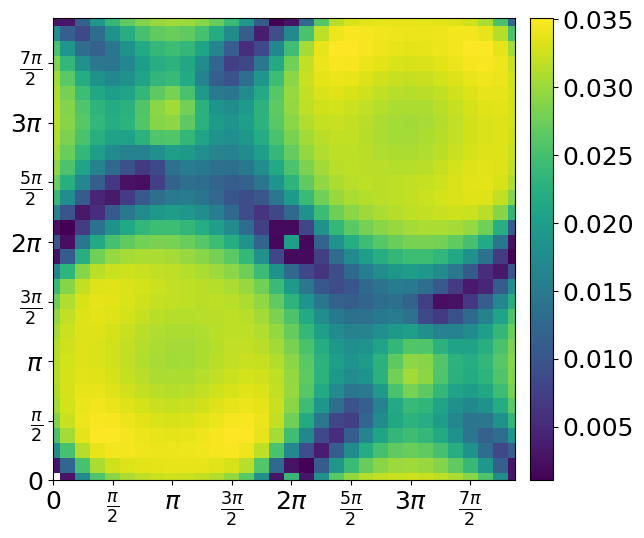

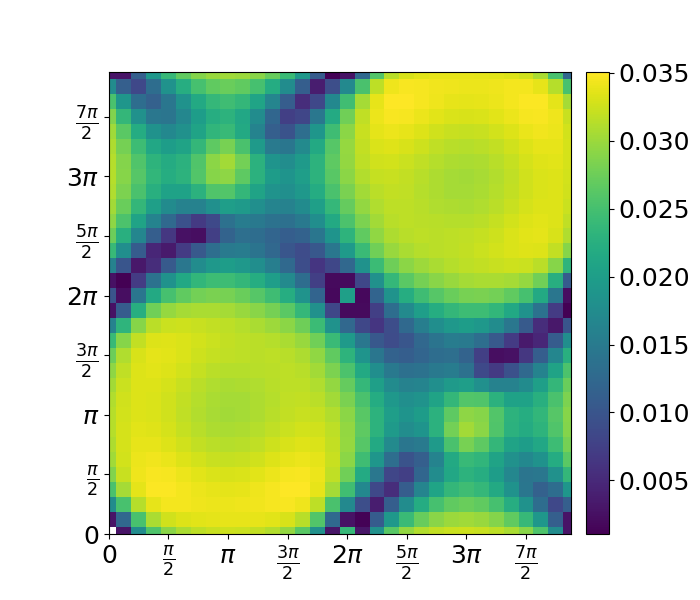

In [74]:
band = 0
parent_folder = "Data"
folder_name = "qwz_separable"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/separable_test"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(f"{configfile}")
eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
eQ = np.load(eQfile, mmap_mode='r')
NQ = cfg["NQ"]
Nk = cfg["Nk"]
ni_evals, ni_wf = SolveBzNoninteracting(cfg)
phase_data = SeamHandle(ni_wf,cfg)
exc_evals = eQ[:,:,band]
Fn_grid = np.zeros((NQ,NQ),dtype = float)
#for px in range(Nk):
    #for py in range(Nk):
p=(9,10)
for Qx in range(NQ):
    for Qy in range(NQ):
        Fn_grid[Qx,Qy] = np.sqrt(AnalyticseparableF(ni_wf, ni_evals, phase_data, exc_evals,(Qx,Qy),p,cfg))
GraphFromConfig(Fn_grid,cfg,GraphProtocol.Test,out_folder,band,p,C=None)

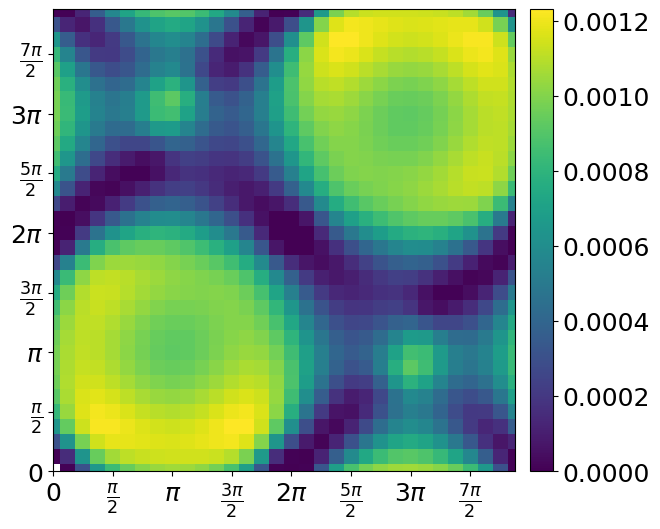

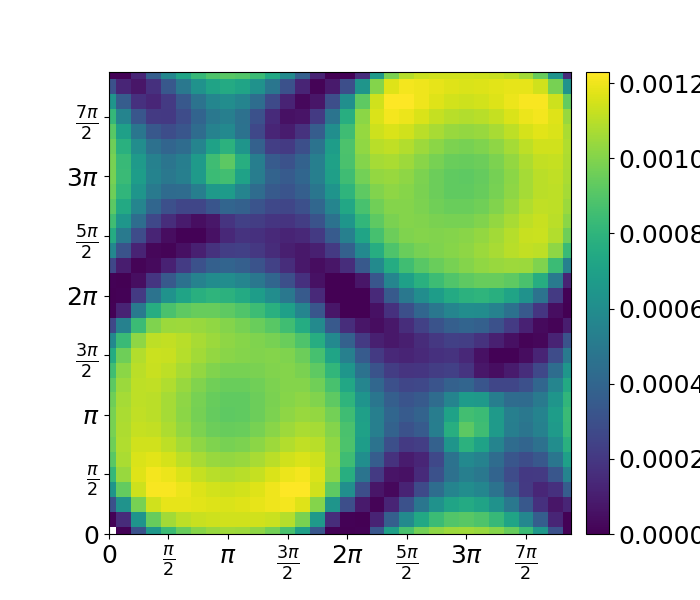

In [306]:
#diff
Fnfile = os.path.join(load_folder, f"F[{band}].npy")
Fn = np.load(Fnfile, mmap_mode='r')
abs_Fn_p = np.abs(Fn[:,:,p[0],p[1]])
F_overlaps = np.zeros_like(abs_Fn_p)
for Q1 in range(NQ):
    for Q2 in range(NQ):
        F_overlaps[Q1,Q2] = np.vdot(abs_Fn_p[Q1,Q2],Fn_grid[Q1,Q2])
#dF = abs_Fn_p - Fn_grid
GraphFromConfig(F_overlaps,cfg,GraphProtocol.Test,load_folder,band,p,C=None)

### Open boundary Berry curvature
for dirac model and other continuum tests

In [ ]:
def GetBCOpenPBC(u):
    N = u.shape[0] #assumes u.shape[N,N,:]
    link_x=np.zeros([N-1,N-1], dtype="complex")
    link_y=np.zeros([N-1,N-1], dtype="complex")
    BC=np.zeros([N-2,N-2], dtype="complex")
    for i in range(N-1):
        for j in range(N-1):
            iR,jR = (i+1,j)
            iU,jU = (i,j+1)
            #link_x[i,j]=(u[iL,jL,:].conj().T @ u[i,j,:])/(np.abs(u[iL,jL,:].conj().T @ u[i,j,:]))
            #link_y[i,j]=(u[iD,jD,:].conj().T @ u[i,j,:])/(np.abs(u[iD,jD,:].conj().T @ u[i,j,:]))
            num = np.vdot(u[i, j], u[iR, jR])
            link_x[i, j] = num / np.abs(num)
            num = np.vdot(u[i, j], u[iU, jU])
            link_y[i, j] = num / np.abs(num)
    for i in range(N-2):
        for j in range(N-2):
            iR,jR = (i+1,j)
            iU,jU = (i,j+1)
            val = np.imag(np.log(link_x[i,j]))
            val += np.imag(np.log(link_y[iR,jR]))
            val -= np.imag(np.log((link_x[iU,jU])))
            val -= np.imag(np.log(link_y[i,j]))
            #commented code to erase undefined points at band crossings
            #if not math.isnan(val):
            BC[i,j] = val
            #else:
                #BC[i,j]=BC[i,j-1]
    C=np.sum(BC)/(2*np.pi)
    return BC,C

In [ ]:
Qxlist = np.linspace(-np.pi,np.pi,32)
Qylist = np.linspace(-np.pi,np.pi,32)
dQx = Qxlist[1]
dQy = Qylist[1]
arr = (Qxlist[:, None]) + (1j * Qylist[None, :])

In [ ]:
cfg = GetConfig("configqwz.yml")
cfg["Qxlist"] = Qxlist
cfg["Qylist"] = Qylist
BCtest,Ctest = GetBCOpenPBC(arr)
GraphFromConfig(np.real(BCtest),cfg,GraphProtocol.Test,"Images")
print(Ctest)

### Single particle case
$F(p,Q) = \delta_{p,p'}(Q)$ meaning $\psi = \sum_pF(p,Q)u^c(p+Q/2)u^v(p-Q/2)^*=u^c(p'+Q/2)u^v(p'-Q/2)^*$

In [ ]:
import ExcitonWF
band = 0
p_prime = (0,0)
parent_folder = "Data"
folder_name = "2026-03-23_13-57-26"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/test"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(f"{configfile}")
Fn_file = os.path.join(load_folder, f"F[{band}].npy")
Fn = np.load(Fn_file, mmap_mode='r')
NQ = cfg["NQ"]
v = cfg["v_band"]
c = cfg["c_band"]
ni_evals, ni_wf = SolveBzNoninteracting(cfg)
phase_data = SeamHandle(ni_wf,cfg)
range_handle = cfg["Grid"]["Range"]
Fn_delta = np.zeros_like(Fn)
Fn_delta[:,:,p_prime[0],p_prime[1]] = 1.0
UnBC, Cn = ExcitonWF.GetExcitonBC(Fn_delta, ni_wf, v, c, cfg.get("hamiltonian").get("lattice"), phase_data,range_handle)
GraphFromConfig(UnBC,cfg,GraphProtocol.ExcBC,out_folder,band,p_prime,C=Cn)

### Vorticity of single zero

#### Carolina ver

In [ ]:
def find_min_points(F, rtol=0.0, atol=0.0, top_k=None):

    A = np.abs(F)
    m = A.min()
    
    thresh = m + atol + rtol*m
    pts = np.argwhere(A <= thresh)
    
    if top_k is not None:
        flat = A.ravel()
        k = min(int(top_k), flat.size)
        idx = np.argpartition(flat, k-1)[:k]
        pts_k = np.column_stack(np.unravel_index(idx, A.shape))
        # merge, unique
        pts = np.vstack([pts, pts_k])
        pts = np.unique(pts, axis=0)
    
    return m, pts, A
def summarize_points(A, pts):
    vals = A[pts[:,0], pts[:,1]]
    order = np.argsort(vals)
    pts = pts[order]
    vals = vals[order]
    return [(int(i), int(j), float(v)) for (i,j), v in zip(pts, vals)]

def plot_amp_with_all_plaquettes(F, logscale=False, cmap="viridis",
                                 grid_color="r", grid_lw=0.6,
                                 mark_min=True, min_rtol=0.0, min_atol=0.0):

    Nx, Ny = F.shape
    A = np.abs(F).astype(float)
    Z = np.log10(A + 1e-300) if logscale else A

    fig, ax = plt.subplots(figsize=(6,5))
    
    # cell edges at integer coordinates
    x = np.arange(Nx+1)
    y = np.arange(Ny+1)
    
    pm = ax.pcolormesh(x, y, Z.T, shading="auto", cmap=cmap)
    fig.colorbar(pm, ax=ax, label=("log10|F|" if logscale else "|F|"))
    
    # draw ALL plaquette boundaries
    ax.vlines(np.arange(Nx+1), 0, Ny, colors=grid_color, linewidth=grid_lw)
    ax.hlines(np.arange(Ny+1), 0, Nx, colors=grid_color, linewidth=grid_lw)
    
    # mark minima (all ties within tolerance)
    if mark_min:
        m = A.min()
        thresh = m + min_atol + min_rtol*m
        pts = np.argwhere(A <= thresh)
        # mark as points at lattice vertices (not cell centers)
        ax.scatter(pts[:,0], pts[:,1], s=40, facecolors="none",
                   edgecolors="w", linewidths=1.5)
        ax.set_title(f"|F| with all plaquettes; min={m:.3e}, count={len(pts)}")
    else:
        ax.set_title("|F| with all plaquettes")
    
    ax.set_xlim(0, Nx)
    ax.set_ylim(0, Ny)
    ax.set_aspect("equal")
    ax.set_xlabel("Qx index")
    ax.set_ylabel("Qy index")
    plt.tight_layout()
    return fig, ax

px0=5
py0=12

F00 = Exciton_F[:,:,px0,py0]

plot_amp_with_all_plaquettes(F00, logscale=False, grid_color="r", grid_lw=0.5,
                              mark_min=True, min_rtol=1e-3)
plt.show()

def wrap_angle(dphi):
    return (dphi + np.pi) % (2*np.pi) - np.pi

def square_loop_indices(N, i0, j0, r):
    pts = []

    # bottom edge: (i0-r .. i0+r-1, j0-r)
    for i in range(i0 - r, i0 + r):
        pts.append((i, j0 - r))
    # right edge: (i0+r, j0-r .. j0+r-1)
    for j in range(j0 - r, j0 + r):
        pts.append((i0 + r, j))
    # top edge: (i0+r .. i0-r+1, j0+r)
    for i in range(i0 + r, i0 - r, -1):
        pts.append((i, j0 + r))
    # left edge: (i0-r, j0+r .. j0-r+1)
    for j in range(j0 + r, j0 - r, -1):
        pts.append((i0 - r, j))
    # periodic wrap
    pts = [(i % N, j % N) for (i, j) in pts]
    return pts
def winding_around_vertex(
    f, i0, j0, amp_cut=1e-12, r_max=None, r_fixed=None,
    orientation="ccw", rel_cut=1e-6, require_safe=True
):

    N = f.shape[0]

def compute_on_radius(r):
    loop = square_loop_indices(N, i0, j0, r)

    if orientation.lower() == "cw":
        loop = loop[::-1]

    amps = np.array([abs(f[i, j]) for (i, j) in loop])
    scale = np.max(amps)

    # reject loops that pass too close to a zero
    if require_safe:
        if scale == 0:
            return None, None
        if np.any(amps < max(amp_cut, rel_cut * scale)):
            return None, None

    phases = np.array([np.angle(f[i, j]) for (i, j) in loop])
    dphis = wrap_angle(np.diff(np.r_[phases, phases[0]]))
    W = dphis.sum() / (2 * np.pi)
    return W, r

if r_fixed is not None:
    return compute_on_radius(r_fixed)

if r_max is None:
    r_max = N // 2 - 1

for r in range(1, r_max + 1):
    W, r_used = compute_on_radius(r)
    if W is not None:
        return W, r_used

return None, None


f_phys = Exciton_F[:, :, px0, py0] 

m, pts, A = find_min_points(f_phys, rtol=1e-3, atol=0.0)
print(summarize_points(A, pts)[:20])

winding_each_zero = []
total_winding_zeros = 0.0
for (i,j) in enumerate(pts):
    Wccw, r_used = winding_around_vertex(f_phys, j[0], j[1], amp_cut=1e-12, orientation="ccw")
    print(r_used)
    winding_each_zero.append((j,Wccw))
    total_winding_zeros += Wccw

print("Winding from each zero:" , winding_each_zero)
print("Total winding from zeros of the F:" , total_winding_zeros)



In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def find_min_points(F, rtol=0.0, atol=0.0, top_k=None):
    A = np.abs(F)
    m = A.min()

    thresh = m + atol + rtol * m
    pts = np.argwhere(A <= thresh)

    if top_k is not None:
        flat = A.ravel()
        k = min(int(top_k), flat.size)
        if k > 0:
            idx = np.argpartition(flat, k - 1)[:k]
            pts_k = np.column_stack(np.unravel_index(idx, A.shape))
            pts = np.vstack([pts, pts_k])
            pts = np.unique(pts, axis=0)

    return m, pts, A


def summarize_points(A, pts):
    vals = A[pts[:, 0], pts[:, 1]]
    order = np.argsort(vals)
    pts = pts[order]
    vals = vals[order]
    return [(int(i), int(j), float(v)) for (i, j), v in zip(pts, vals)]


def plot_amp_with_all_plaquettes(
    F,
    logscale=False,
    cmap="viridis",
    grid_color="r",
    grid_lw=0.6,
    mark_min=True,
    min_rtol=0.0,
    min_atol=0.0,
):
    Nx, Ny = F.shape
    A = np.abs(F).astype(float)
    Z = np.log10(A + 1e-300) if logscale else A

    fig, ax = plt.subplots(figsize=(6, 5))

    x = np.arange(Nx + 1)
    y = np.arange(Ny + 1)

    pm = ax.pcolormesh(x, y, Z.T, shading="auto", cmap=cmap)
    fig.colorbar(pm, ax=ax, label=("log10|F|" if logscale else "|F|"))

    ax.vlines(np.arange(Nx + 1), 0, Ny, colors=grid_color, linewidth=grid_lw)
    ax.hlines(np.arange(Ny + 1), 0, Nx, colors=grid_color, linewidth=grid_lw)

    if mark_min:
        m = A.min()
        thresh = m + min_atol + min_rtol * m
        pts = np.argwhere(A <= thresh)
        ax.scatter(
            pts[:, 0],
            pts[:, 1],
            s=40,
            facecolors="none",
            edgecolors="w",
            linewidths=1.5,
        )
        ax.set_title(f"|F| with all plaquettes; min={m:.3e}, count={len(pts)}")
    else:
        ax.set_title("|F| with all plaquettes")

    ax.set_xlim(0, Nx)
    ax.set_ylim(0, Ny)
    ax.set_aspect("equal")
    ax.set_xlabel("Qx index")
    ax.set_ylabel("Qy index")
    plt.tight_layout()
    return fig, ax


def wrap_angle(dphi):
    return (dphi + np.pi) % (2 * np.pi) - np.pi


def square_loop_indices(N, i0, j0, r):
    pts = []

    # bottom edge
    for i in range(i0 - r, i0 + r):
        pts.append((i, j0 - r))

    # right edge
    for j in range(j0 - r, j0 + r):
        pts.append((i0 + r, j))

    # top edge
    for i in range(i0 + r, i0 - r, -1):
        pts.append((i, j0 + r))

    # left edge
    for j in range(j0 + r, j0 - r, -1):
        pts.append((i0 - r, j))

    pts = [(i % N, j % N) for (i, j) in pts]
    return pts


def winding_around_vertex(
    f,
    i0,
    j0,
    amp_cut=1e-12,
    r_max=None,
    r_fixed=None,
    orientation="ccw",
    rel_cut=1e-6,
    require_safe=True,
):
    N = f.shape[0]

    def compute_on_radius(r):
        loop = square_loop_indices(N, i0, j0, r)

        if orientation.lower() == "cw":
            loop = loop[::-1]

        amps = np.array([abs(f[i, j]) for (i, j) in loop])
        scale = np.max(amps)

        # reject loops that pass too close to a zero
        if require_safe:
            if scale == 0:
                return None, None
            if np.any(amps < max(amp_cut, rel_cut * scale)):
                return None, None

        phases = np.array([np.angle(f[i, j]) for (i, j) in loop])
        dphis = wrap_angle(np.diff(np.r_[phases, phases[0]]))
        W = dphis.sum() / (2 * np.pi)
        return W, r

    if r_fixed is not None:
        return compute_on_radius(r_fixed)

    if r_max is None:
        r_max = N // 2 - 1

    for r in range(1, r_max + 1):
        W, r_used = compute_on_radius(r)
        if W is not None:
            return W, r_used

    return None, None

In [ ]:
px0 = 2
py0 = 8
parent_folder = "Data"
folder_name = "2026-04-27_15-39-07"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/test"
Fn_file = os.path.join(load_folder, f"F[0].npy")
Fn = np.load(Fn_file, mmap_mode='r')
f_phys = Fn[:, :, px0, py0]

plot_amp_with_all_plaquettes(
    f_phys,
    logscale=False,
    grid_color="r",
    grid_lw=0.5,
    mark_min=True,
    min_rtol=1e-3,
)
plt.show()

m, pts, A = find_min_points(f_phys, rtol=1e-3, atol=0.0)
print(summarize_points(A, pts)[:20])

winding_each_zero = []
total_winding_zeros = 0.0

for i, j in pts:
    Wccw, r_used = winding_around_vertex(
        f_phys,
        i,
        j,
        amp_cut=1e-12,
        orientation="ccw",
    )
    print("point =", (i, j), "r_used =", r_used, "W =", Wccw)

    winding_each_zero.append(((int(i), int(j)), Wccw))

    if Wccw is not None:
        total_winding_zeros += Wccw

print("Winding from each zero:", winding_each_zero)
print("Total winding from zeros of F:", total_winding_zeros)

#### Ofir ver

In [177]:
import numpy as np
import matplotlib.pyplot as plt


#def plot_abs_slice(F,p=None, ax=None):
#    """
#    Plot abs(F[:, :, p[0], p[1]]).
#    """
#    A = np.abs(F)
#
#    if ax is None:
#        fig, ax = plt.subplots()
#    else:
#        fig = ax.figure
#
#    im = ax.imshow(A, origin="lower", cmap="viridis")
#    ax.set_title(f"|F[:, :,{p[0]} , {p[1]}|")
#    ax.set_xlabel("x")
#    ax.set_ylabel("y")
#    fig.colorbar(im, ax=ax, label="|F|")
#    return fig, ax, im


def find_local_min_near_click(A, x_click, y_click, search_radius=5):
    """
    Find the smallest point in A near the clicked location.

    Parameters
    ----------
    A : 2D real array
        Typically abs(F[:, :, p0, p1]).
    x_click, y_click : float
        Click coordinates in image/grid coordinates.
    search_radius : int
        Search in a square neighborhood of this radius.

    Returns
    -------
    (iy, ix) : tuple of ints
        Grid indices of the local minimum.
    """
    ny, nx = A.shape

    ix0 = int(round(x_click))
    iy0 = int(round(y_click))

    x1 = max(0, ix0 - search_radius)
    x2 = min(nx, ix0 + search_radius + 1)
    y1 = max(0, iy0 - search_radius)
    y2 = min(ny, iy0 + search_radius + 1)

    window = A[y1:y2, x1:x2]
    j, i = np.unravel_index(np.argmin(window), window.shape)

    iy = y1 + j
    ix = x1 + i
    return iy, ix


def square_perimeter_indices(center, radius, shape):
    """
    Return the ordered perimeter points of a square centered at `center`
    with Chebyshev radius `radius`.

    center = (iy, ix)
    shape = (ny, nx)

    The loop is ordered so it can be used for a phase winding computation.
    """
    iy, ix = center
    ny, nx = shape

    if radius < 1:
        raise ValueError("radius must be >= 1")

    top = iy + radius
    bottom = iy - radius
    left = ix - radius
    right = ix + radius

    if bottom < 0 or left < 0 or top >= ny or right >= nx:
        return None  # square does not fit in array

    pts = []

    # bottom edge: left -> right
    for x in range(left, right):
        pts.append((bottom, x))

    # right edge: bottom -> top
    for y in range(bottom, top):
        pts.append((y, right))

    # top edge: right -> left
    for x in range(right, left, -1):
        pts.append((top, x))

    # left edge: top -> bottom
    for y in range(top, bottom, -1):
        pts.append((y, left))

    return pts


def phase_winding_on_loop(values):
    """
    Compute total phase winding from ordered complex samples on a closed loop.

    Uses phase differences between consecutive points:
        dphi_k = angle(z_{k+1} * conj(z_k))

    This is much more robust than summing raw angles.
    """
    values = np.asarray(values)

    if np.any(np.abs(values) == 0):
        return np.nan, np.nan

    # close the loop
    z1 = values
    z2 = np.roll(values, -1)

    dphi = np.angle(z2 * np.conj(z1))
    total = np.sum(dphi)
    winding = total / (2 * np.pi)
    return total, winding


def phase_winding_square(F, center, radius):
    """
    Compute the phase winding of complex field F around a square loop.
    """
    pts = square_perimeter_indices(center, radius, F.shape)
    if pts is None:
        return np.nan, np.nan, None

    vals = np.array([F[iy, ix] for iy, ix in pts[::-1]], dtype=complex)
    #vals = np.array([F[iy, ix] for iy, ix in pts], dtype=complex)
    total, winding = phase_winding_on_loop(vals)
    return total, winding, pts


def phase_windings_for_radii(F, p, center, radii):
    """
    Compute windings for multiple square radii around `center`.
    """
    results = []

    for r in radii:
        total, winding, pts = phase_winding_square(F, center, r)
        results.append({
            "radius": r,
            "total_phase": total,
            "winding": winding,
            "rounded_winding": np.nan if np.isnan(winding) else int(np.round(winding)),
            "points": pts,
        })

    return results


class InteractiveWindingExplorer:
    """
    Interactive click-to-select-minimum and inspect phase winding.

    Usage
    -----
    explorer = InteractiveWindingExplorer(F, p=(0, 1), radii=[2, 3, 4, 5], search_radius=5)
    """
    def __init__(self, F, radii=(2, 3, 4, 5), search_radius=5,p=['','']):
        self.F = F
        self.radii = list(radii)
        self.search_radius = search_radius
        
        self.A = np.abs(self.F)

        self.fig, (self.ax_img, self.ax_txt) = plt.subplots(
            1, 2, figsize=(10, 5), constrained_layout=True
        )

        self.im = self.ax_img.imshow(self.A, origin="lower", cmap="viridis")
        self.ax_img.set_title(f"|F[:, :, {p[0]}, {p[1]}]|")
        self.ax_img.set_xlabel("x")
        self.ax_img.set_ylabel("y")
        self.fig.colorbar(self.im, ax=self.ax_img, label="|F|")

        self.marker, = self.ax_img.plot([], [], "ro", ms=8)
        self.loop_artists = []

        self.ax_txt.set_axis_off()
        self.text = self.ax_txt.text(
            0.02, 0.98, "Click near a vortex/core",
            va="top", ha="left", family="monospace"
        )

        self.cid = self.fig.canvas.mpl_connect("button_press_event", self.onclick)

    def clear_loops(self):
        for artist in self.loop_artists:
            artist.remove()
        self.loop_artists = []

    def draw_square(self, center, radius, **kwargs):
        iy, ix = center
        x0 = ix - radius
        y0 = iy - radius
        w = 2 * radius
        rect = plt.Rectangle((x0, y0), w, w, fill=False, **kwargs)
        self.ax_img.add_patch(rect)
        self.loop_artists.append(rect)

    def onclick(self, event):
        if event.inaxes != self.ax_img:
            return
        if event.xdata is None or event.ydata is None:
            return

        iy, ix = find_local_min_near_click(
            self.A, event.xdata, event.ydata, search_radius=self.search_radius
        )

        self.marker.set_data([ix], [iy])
        self.clear_loops()

        lines = [
            f"selected minimum: (iy, ix) = ({iy}, {ix})",
            f"|F| there = {self.A[iy, ix]:.6g}",
            "",
            "radius   total_phase      winding     rounded"
        ]

        for r in self.radii:
            total, winding, pts = phase_winding_square(self.F, (iy, ix), r)
            if pts is not None:
                self.draw_square((iy, ix), r, lw=1.5)

            lines.append(
                f"{r:>5d}   "
                f"{total:>12.6f}   "
                f"{winding:>10.6f}   "
                f"{('nan' if np.isnan(winding) else int(np.round(winding))):>7}"
            )

        self.text.set_text("\n".join(lines))
        self.fig.canvas.draw_idle()

In [ ]:
parent_folder = "Data"
folder_name = r"QWZ_CarolinaRequest\qwz_M0.7"
#folder_name = "2026-06-16_15-16-13"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}"
Fn_file = os.path.join(load_folder, f"F0_Gauged.npy")
#Fn_file = os.path.join(load_folder, f"F[0].npy")
#Fn_file = os.path.join(load_folder, f"Z_px10_py9.npy")
F = np.load(Fn_file, mmap_mode='r')
p= (9,10)
explorer = InteractiveWindingExplorer(
    F[:,:,p[0],p[1]],
    radii=[1, 2, 3, 4, 5],
    search_radius=6,
    p=p
    
)

plt.show()

In [ ]:
parent_folder = "Data"
folder_name = "test_data"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/test"
pfile = f"{load_folder}/Q_031_015.npz"
arr = np.load(pfile)
f_keep = arr["f_keep"]
n_Fs=1

#### Phase differences between Carolina and Ofir

In [ ]:
cfg = GetConfig("configqwz.yml")
ni_eval, ni_wf = SolveBzNoninteracting(cfg)
ref = np.array([1, 0], dtype=complex)
phase_0 = np.angle(np.einsum('xyi,i->xy', ni_wf[:, :, :, 0], np.conj(ref)))
GraphFromConfig(phase,cfg,GraphProtocol.Test,"Images/Tests",0)
def gauge_fix_cylindrical_gauge(vec, enforce_ky_periodic=True):

    Nkx, Nky, spinor_dim = vec.shape
    vec_gauge = np.zeros((Nkx, Nky, spinor_dim), dtype=np.complex128)

    # seed
    vec_gauge[0, 0, :] = vec[0, 0, :]

    # ky parallel transport on the kx=0 column
    for ky in range(Nky - 1):
        vec_gauge[0, ky + 1, :] = np.exp(-1j * np.angle(np.vdot(vec_gauge[0, ky, :], vec[0, ky + 1, :]))) * vec[0, ky + 1, :]

    # enforce trivial ky sewing (optional)
    if enforce_ky_periodic:
        for ky in range(Nky):
            vec_gauge[0, ky, :] *= np.exp(-1j * ky * np.angle(np.vdot(vec_gauge[0, Nky - 1, :], vec_gauge[0, 0, :])) / Nky)

    # kx parallel transport on each row, seeded by the ky-fixed first column
    for ky in range(Nky):
        for kx in range(Nkx - 1):
            vec_gauge[kx + 1, ky, :] = np.exp(-1j * np.angle(np.vdot(vec_gauge[kx, ky, :], vec[kx + 1, ky, :]))) * vec[kx + 1, ky, :]

    return vec_gauge


uv_cylindrical_gauge = gauge_fix_cylindrical_gauge(ni_wf[:,:,:,0], enforce_ky_periodic=True)
uc_cylindrical_gauge = gauge_fix_cylindrical_gauge(ni_wf[:,:,:,1], enforce_ky_periodic=True)
ref = np.array([1, 0], dtype=complex)
phase = np.angle(np.einsum('xyi,i->xy', uv_cylindrical_gauge, np.conj(ref)))
GraphFromConfig(phase,cfg,GraphProtocol.Test,"Images/Tests",0)

def holonomy_cylindrical_gauge(vec):
    Nkx, Nky, _ = vec.shape

    holonomy = np.zeros(Nky, dtype=np.complex128)

    for ky in range(Nky):
        holonomy[ky] = np.vdot(vec[Nkx - 1, ky, :], vec[0, ky, :]) / abs(np.vdot(vec[Nkx - 1, ky, :], vec[0, ky, :]))

    return holonomy

#deprecated#
def extended_state_cylindrical_gauge(vec, gx, kx_idx, ky_idx):
    Nkx, Nky, dim = vec.shape
    nwrap_x = kx_idx // Nkx
    kx_mod = kx_idx % Nkx
    ky_mod = ky_idx % Nky
    return (gx[ky_mod] ** nwrap_x) * vec[kx_mod, ky_mod, :]

gx_v = holonomy_cylindrical_gauge(uv_cylindrical_gauge)
gx_c = holonomy_cylindrical_gauge(uc_cylindrical_gauge)

#### Check phases & phase differences

In [ ]:
parent_folder = "Data"
#folder_name1 = "test_data"
folder_name1 = "2026-05-05_11-15-50/gauged"
foldername_2 = "2026-05-14_14-43-57"
load_folder = f"{parent_folder}/{foldername_2}"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(configfile)
p = (0,0)
Fnfile = os.path.join(load_folder, f"F[0].npy")
Fn2 = np.load(Fnfile, mmap_mode='r')
Fn2_p = Fn2[:,:,p[0],p[1]]
#Fn1file = os.path.join(parent_folder,folder_name1,"Z_px10_py9.npy")
Fn1file = os.path.join(parent_folder,folder_name1, f"F0_Gauged.npy")
Fn1 = np.load(Fn1file, mmap_mode='r')
Fn1_p = Fn1[:,:,p[0],p[1]]
out_folder = f"{load_folder}/gauged"
GraphFromConfig(np.angle(Fn2_p),cfg, GraphProtocol.FQuiver, out_folder,0,p)
GraphFromConfig(np.angle(Fn1_p),cfg, GraphProtocol.FQuiver, out_folder,0,p)

In [ ]:
GraphFromConfig(np.angle(Fn1_p)-np.angle(Fn2_p),cfg, GraphProtocol.FQuiver, out_folder,0,(10,9))

### Haldane Seam Explortion
here we explore the discontinuity that appears in |F(p,Q)|
1. I will choose $Q$ and $Q'$ that sit at different sides of the seam at $p_0$ and see if there is a large difference in the kernal at the $p_0$ element, then I will check if its is the same without the sewing matrix.

In [ ]:
parent_folder="Data"
folder_name = "2026-04-27_16-35-24"
load_folder = f"{parent_folder}/{folder_name}"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(configfile)

is there a jump in the kernal at the relevent p's or something of the sort? No

In [ ]:
Q_frac = cfg["Q_frac"]
b = cfg["rec_vec"]
#chosen from graphs in folder
p_ind=(0,1)
Q_ind = (16,1)
Qp_ind = (16,2)
Q_val = b[0]*Q_frac[Q_ind[0]] + b[1]*Q_frac[Q_ind[1]]
Qp_val = b[0]*Q_frac[Qp_ind[0]] + b[1]*Q_frac[Qp_ind[1]]
ni_evals, ni_wf = SolveBzNoninteracting(cfg)
phase_data = SeamHandle(ni_wf, cfg)
seamTest = cfg["Grid"]["SeamTest"]
if seamTest:
    phase_data[0].fill(1)
K1 = GetH2Band(Q_ind[0],Q_ind[1], ni_wf, ni_evals, cfg, phase_data)
K1p = GetH2Band(Qp_ind[0],Qp_ind[1], ni_wf, ni_evals, cfg, phase_data)
dK = np.abs(K1-K1p)

In [ ]:
print("p=p'=0,1", dK[0,1,0,1])
print("mean", dK.mean())
print("median", np.median(dK))
print("std", dK.std())
print("max", dK.max())
print("p90", np.percentile(dK, 90))
print("p95", np.percentile(dK, 95))
print("p99", np.percentile(dK, 99))
print("p99.9", np.percentile(dK, 99.9))
print("p,p' of max dk", np.unravel_index(np.argmax(dK),(32,32,32,32)))

What about off seam, is there any difference between neighbouring points?

In [ ]:
Q_inds = np.array([(16,1),(16,2),(16,0),(15,2)])
Q_vals = (
    Q_frac[Q_inds[:, 0], None] * b[0]
    + Q_frac[Q_inds[:, 1], None] * b[1]
)

In [ ]:
Ks =[]
for Q in Q_inds:
    Ks.append(GetH2Band(Q[0],Q[1], ni_wf, ni_evals, cfg, phase_data))

In [ ]:
dK_seam = np.abs(Ks[0]-Ks[1])
dK_smooth1 = np.abs(Ks[0]-Ks[2])
dK_smooth2 = np.abs(Ks[1]-Ks[3])
print("seam mean / smooth1 mean", dK_seam.mean() / dK_smooth1.mean())
print("seam max / smooth1 max", dK_seam.max() / dK_smooth1.max())
print("seam p99 / smooth1 p99", np.percentile(dK_seam,99) / np.percentile(dK_smooth1,99))
print("")
print("seam mean / smooth2 mean", dK_seam.mean() / dK_smooth2.mean())
print("seam max / smooth2 max", dK_seam.max() / dK_smooth2.max())
print("seam p99 / smooth2 p99", np.percentile(dK_seam,99) / np.percentile(dK_smooth2,99))
print("")
print("smooth1 mean / smooth2 mean", dK_smooth1.mean() / dK_smooth2.mean())
print("smooth1 max / smooth2 max", dK_smooth1.max() / dK_smooth2.max())
print("smooth1 p99 / smooth2 p99", np.percentile(dK_smooth1,99) / np.percentile(dK_smooth2,99))

Now without sewing matrix

In [ ]:
#Wont work
g0 = np.ones_like(g1)
Ks0 = []
for Q in Q_inds:
    Ks0.append(GetH2Band(Q[0],Q[1], ni_wf, ni_evals, cfg, g0))

In [ ]:
dK0_seam = np.abs(Ks0[0]-Ks0[1])
dK0_smooth1 = np.abs(Ks0[0]-Ks0[2])
dK0_smooth2 = np.abs(Ks0[1]-Ks0[3])
print("seam mean / smooth1 mean", dK0_seam.mean() / dK0_smooth1.mean())
print("seam max / smooth1 max", dK0_seam.max() / dK0_smooth1.max())
print("seam p99 / smooth1 p99", np.percentile(dK0_seam,99) / np.percentile(dK0_smooth1,99))
print("")
print("seam mean / smooth2 mean", dK0_seam.mean() / dK0_smooth2.mean())
print("seam max / smooth2 max", dK0_seam.max() / dK0_smooth2.max())
print("seam p99 / smooth2 p99", np.percentile(dK0_seam,99) / np.percentile(dK0_smooth2,99))
print("")
print("smooth1 mean / smooth2 mean", dK0_smooth1.mean() / dK0_smooth2.mean())
print("smooth1 max / smooth2 max", dK0_smooth1.max() / dK0_smooth2.max())
print("smooth1 p99 / smooth2 p99", np.percentile(dK0_smooth1,99) / np.percentile(dK0_smooth2,99))

looking at how the relative dK max doesnt change with the sewing seams to me to show that there isnt a discontinuity in the Kernal.

In [ ]:
LoadGraphSingle(parent_folder,folder_name, GraphProtocol.AbsF2D,band = 0, p_ind = (0,1), out_folder = "Images/Tests",
                marker_spec = [MarkerSpec(MarkerMode.MANUAL,points = Q_vals,size = 15)])

In [ ]:
#What is the seam in terms of momentum
p_val = (1/32)*b[1]
Q_val_ = b[0]*Q_frac[16] + b[1]*Q_frac[0]
print("p_val = ", p_val/np.pi)
print("Q_val = ", Q_val/np.pi)
print("p+Q/2 = ", (p_val + Q_val_)/np.pi)
print("b1 = ", b[0]/np.pi)
print("b2 = ", b[1]/np.pi)

In [ ]:
import scipy
#seam 0,1
#smooth (0,2)(1,3)
evecs = []
evals=[]
evecs0=[]
evals0=[]
for K in Ks:
    s = K.shape
    Nk2 = s[0] * s[1]
    K2D = K.reshape(Nk2, Nk2)
    e_Q, f_Q = scipy.linalg.eigh(K2D)
    evals.append(e_Q)
    evecs.append(f_Q[:,0])
for K0 in Ks0:
    s = K0.shape
    Nk2 = s[0] * s[1]
    K02D = K0.reshape(Nk2, Nk2)
    e_Q, f_Q = scipy.linalg.eigh(K02D)
    evals0.append(e_Q)
    evecs0.append(f_Q[:,0])

In [ ]:
NQ = 32
Nk = 32
Fn = np.zeros((NQ,NQ,Nk,Nk), dtype = complex)
Fn0 = np.zeros((NQ,NQ,Nk,Nk), dtype = complex)
for i,Q in enumerate(Q_inds):
    Fi = evecs[i]
    Fi0 = evecs0[i]
    Fn[Q[0],Q[1],:,:] = Fi.reshape(Nk,Nk)
    Fn0[Q[0],Q[1],:,:]= Fi0.reshape(Nk,Nk)

what about the exciton wf overlap between neighbouring points, cross seam and cross smooth

In [ ]:
ni_evals, ni_wf = SolveBzNoninteracting(cfg)
#Wont work
seamOverlap = ExcitonVProd_PBasis((16,1),(16,2),Fn,ni_wf,0,1,g1,cfg["Grid"]["Range"])
smooth1Overlap = ExcitonVProd_PBasis((16,1),(16,0),Fn,ni_wf,0,1,g1,cfg["Grid"]["Range"])
smooth2Overlap = ExcitonVProd_PBasis((16,2),(15,2),Fn,ni_wf,0,1,g1,cfg["Grid"]["Range"])

seamOverlap0 = ExcitonVProd_PBasis((16,1),(16,2),Fn0,ni_wf,0,1,g0,cfg["Grid"]["Range"])
smooth1Overlap0 = ExcitonVProd_PBasis((16,1),(16,0),Fn0,ni_wf,0,1,g0,cfg["Grid"]["Range"])
smooth2Overlap0 = ExcitonVProd_PBasis((16,2),(15,2),Fn0,ni_wf,0,1,g0,cfg["Grid"]["Range"])

print(f"seam overlap {seamOverlap}")
print(f"smooth1 {smooth1Overlap}")
print(f"smooth2 {smooth2Overlap}")

print(f"seam 0 {seamOverlap0}")
print(f"smooth1_0 {smooth1Overlap0}")
print(f"smooth2_0 {smooth2Overlap0}")

cant really say I see anything that pops out at me

2. Check if $\epsilon_Q - E^c_{p+Q/2} + E^v_{p-Q/2} = 0$ across the seam

In [ ]:
parent_folder="Data"
folder_name = "2026-04-27_16-35-24"
load_folder = f"{parent_folder}/{folder_name}"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(configfile)
eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
eQ = np.load(eQfile, mmap_mode='r')
eQ0 = eQ[:,:,0]
ni_evals, ni_wf = SolveBzNoninteracting(cfg)
Q1_range,Q2_range = np.shape(eQ0)
Kp = (0,8,0,0)
vals = np.zeros_like(eQ0)
Es = np.zeros_like(eQ0)
for Q1 in range(Q1_range):
    for Q2 in range(Q2_range):
        Kv = PBCAddInd(Kp,(-Q1,-Q2),32)
        Kc = PBCAddInd(Kp,(Q1,Q2),32)
        e = ni_evals[Kc[0]][Kc[1]][1]- ni_evals[Kv[0]][Kv[1]][0]
        Es[Q1,Q2] = e
        vals[Q1,Q2] = eQ0[Q1,Q2] - e

In [ ]:
GraphFromConfig(vals,cfg,GraphProtocol.Test,"Images/Tests",band=0,p_ind=(0,1))

In [ ]:
GraphFromConfig(eQ0,cfg,GraphProtocol.Test,"Images/Tests",band=0,p_ind=(0,1))

In [ ]:
GraphFromConfig(Es,cfg,GraphProtocol.Test,"Images/Tests",band=0,p_ind=(0,1))

3. plot $p_0\pm Q/2 = b_1$ and $p_0\pm Q/2 = b_2$ over $|F(p_0,Q)|$

$Q = \pm 2(b - p_0)$ meaning $Q_1 = \pm 2(b-p_0)_1$ and $Q_2 = \pm 2(b-p_0)_2$ 

So two lines for each $Q_2$ a constant $Q_1 = \pm 2(b_1-p_{0,1})$ and vice versa in indices

In [ ]:
from functools import partial

def SeamExplorationAxesHandler(ax, p = (8,6), Np =32):
    b1 = np.array([2*np.pi/3,2*np.pi/np.sqrt(3)])
    b2 = np.array([-2*np.pi/3,2*np.pi/np.sqrt(3)])
    #p_val = (p[0]/Np)*b1 + (p[1]/Np)*b2
    Q1_0_val = (2*(b1 - (p[0]/Np)*b1))%(2*b1)
    Q1_1_val = (-2*(b1 - (p[0]/Np)*b1))%(2*b1)
    Q2_0_val = (2*(b2 - (p[1]/Np)*b2))%(2*b2)
    Q2_1_val = (-2*(b2 - (p[1]/Np)*b2))%(2*b2)
    q_line = np.linspace(0,2,100)
    line1 = np.array([Q1_0_val+x*b2 for x in q_line])
    line2 = np.array([Q1_1_val+x*b2 for x in q_line])
    line3 = np.array([Q2_0_val+x*b1 for x in q_line])
    line4 = np.array([Q2_1_val+x*b1 for x in q_line])
    ax.plot(line1[:,0], line1[:,1], 'y--', lw=1, label = "Q1 wrap +")
    ax.plot(line2[:,0], line2[:,1], 'r--', lw=1, label = "Q1 wrap -")
    ax.plot(line3[:,0], line3[:,1], 'b--', lw=1, label = "Q2 wrap +")
    ax.plot(line4[:,0], line4[:,1], 'g--', lw=1, label = "Q2 wrap -")
    ax.legend()

In [ ]:
F0file = os.path.join(load_folder, f"F[0].npy")
F0 = np.load(F0file, mmap_mode='r')
p0 = (8,6)
F0_p0 = F0[:,:,p0[0],p0[1]]
absF0_p0 = np.abs(F0_p0)
frac, b1, b2 = GetFracGridAndRecVec(cfg, "Q")
frac_u, frac_v, X, Y = BuildReciprocalMesh(frac, b1, b2)
Graph2D(absF0_p0, X,Y,"Images/Tests", "seamlines",axes_handler = SeamExplorationAxesHandler)

#### Basis dependence of the seam
Since the discontinuity appears in all the hexagonal models tested (Haldane, Semenoff, graphene) and I have shown that the seam coincides exactly with the wrapping in the single partice BZ, I have come to the thought that the seam is in fact caused by our choice of basis. 

Reminder: $u_{exc}(Q) = \sum_{p_x,p_y}F(p,Q)e^{-i\vec{p}\cdot\vec{r}}|p;Q>$

$|p;Q> = |u^c(p+\frac{Q}{2})>\otimes(|u^v(p-\frac{Q}{2})>)^*$

We cannot forget the $e^{-i\vec{p}\cdot\vec{r}}$ which enforces orthogonality in p.

We want to look at the projection on a different $e^{-i\vec{p'}\cdot\vec{r}}|p';Q'>$ basis, this asks is the discontinuity a function of the chosen basis. 
$<p';Q'|e^{-i\vec{p'}\cdot\vec{r}}|u_{exc}(Q)> = \sum_p F_p(Q)\delta_{pp'}<p';Q'|p;Q>$

$<p;Q'|p;Q> = S_p(Q,Q')$ is the overlap matrix, looking at the changes in this matrix allows us to see how the basis changes depending on our choice of p. Now I choose Q'=Q+dQ where dQ is one grid point. Mapping $|S_p(Q,Q+dQ)|$ will show the magnitude of the difference in the basis. This object is a p space vector like F(Q) and should show the same seam. Additionally for very nearby Q and Q' we may assume $\psi_Q\approx\psi_Q'$ and therefore predict $F^{pred}(Q')=S(Q',Q)F(Q)$ we can compare this with the actually calculated F(Q'), the difference between them tells us how they are changed when using different basis. If the prediction also shows a discontinuity it is because of the basis and not the BSE. (maybe this is a strong statement but it is evidence of this thought at least)

In [ ]:
def GetElectronHoleOverlaps(ni_wf, phase_data, dQ=(0,0), NQ=32, Np=32, c_band = 1, v_band = 0):
    """
    construct S_p(Q,Q') = <p;Q|p;Q'> = <u_c(p+Q/2)|u_c(p+Q'/2)><u_v(p-Q'/2)|u_v(p+Q/2)>
    here Q' = Q+dQ , dQ is expressed in indices in the Q1,Q2 reciprocal lattice directions.
    returns an array [Q1,Q2,p] where for each (Q1,Q2) coordinate a p matrix is expressed.
    """
    S_p = np.zeros((NQ,NQ,Np,Np), dtype = complex) #flat p coordinates
    c_overlaps = np.zeros_like(S_p)
    v_overlaps = np.zeros_like(S_p)
    for Q1 in range(NQ):
        Q1p = Q1+dQ[0]
        for Q2 in range(NQ):
            Q2p = Q2+dQ[1]
            for p1 in range(Np):
                for p2 in range(Np):
                    if phase_data[0] is not None:
                        Kp = (p1,p2,0,0)
                        Kv = PBCAddInd(Kp,(-Q1,-Q2),Np)
                        Kc = PBCAddInd(Kp,(Q1,Q2),Np)
                        Kvp = PBCAddInd(Kp,(-Q1p,-Q2p),Np)
                        Kcp = PBCAddInd(Kp,(Q1p,Q2p),Np)
                        uc = u_ext(ni_wf,phase_data,Kc,c_band,U_arr)
                        uv = u_ext(ni_wf,phase_data,Kv,v_band,U_arr)
                        ucp = u_ext(ni_wf,phase_data,Kcp,c_band,U_arr)
                        uvp = u_ext(ni_wf,phase_data,Kvp,v_band,U_arr)
                    else:
                        kv = ((p1-Q1)%NQ,(p2-Q2)%NQ)
                        kc = ((p1+Q1)%NQ,(p2+Q2)%NQ)
                        kvp = ((p1-Q1p)%NQ,(p2-Q2p)%NQ)
                        kcp = ((p1+Q1p)%NQ,(p2+Q2p)%NQ)
                        uv = ni_wf[kv[0],kv[1],:,v_band]
                        uc = ni_wf[kc[0],kc[1],:,c_band]
                        uvp = ni_wf[kvp[0],kvp[1],:,v_band]
                        ucp = ni_wf[kcp[0],kcp[1],:,c_band]
                    c_overlaps[Q1,Q2,p1,p2] = np.vdot(uc,ucp)
                    v_overlaps[Q1,Q2,p1,p2] = np.vdot(uvp,uv)
                    S_p[Q1,Q2,p1,p2] = np.vdot(uc,ucp)*np.vdot(uvp,uv)
    return S_p , c_overlaps, v_overlaps

def SaveData(data,filename,folder):
    if not filename.endswith('.npy'):
        filename += '.npy'
    full_path = folder / filename
    np.save(full_path, data)

In [ ]:
cfg_dir = r"Data\SeamTest\Graphene_TestFalse"
config_folder = Path(f"{cfg_dir}")
config_name = Path("config.yml")
f_file = config_folder/Path(f"F[{band}].npy")
config_file = config_folder/config_name
cfg = GetConfig(config_file)
NQ = cfg["NQ"]
Np = cfg["Nk"]
F0file = config_folder / Path(f"F[0].npy")
F0 = np.load(F0file, mmap_mode='r')
_, ni_wf = SolveBzNoninteracting(cfg)
phase_data = SeamHandle(ni_wf,cfg)
dQ = (1,0)
S_p = GetElectronHoleOverlaps(ni_wf,phase_data,dQ=dQ)
F_pred = np.zeros_like(F0, dtype=complex)
SaveData(S_p, f"S_p_dQ{dQ}",config_folder)
#for Q1 in range(NQ):
#    for Q2 in range(NQ):
#        Q1p = (Q1 + dQ[0])%NQ
#        Q2p = (Q2 + dQ[1])%NQ
#        F_pred[Q1,Q2,:,:] = S_p[Q1, Q2,:,:] * F0[Q1p, Q2p,:,:]
#SaveData(F_pred, f"F_pred_dQ{dQ}",config_folder)

In [ ]:
dQ = (0,0)
F_pred_file = config_folder/ Path(f"F_pred_dQ{dQ}.npy")
F_pred = np.load(F_pred_file, mmap_mode='r')
out_folder = config_folder / Path(f"F_pred_dQ{dQ}")
p=(0,0)
#GraphFromConfig(np.abs(F_pred[:,:,p[0],p[1]]),cfg,GraphProtocol.Test,out_folder,band =0,p_ind = p)

In [ ]:
cfg = GetConfig(config_file)
out_folder = config_folder / Path(f"F_pred_seamlines_dQ{dQ}")
out_folder.mkdir(parents=True, exist_ok=True)
p0 = (0,0)
absF_pred_p0 = np.abs(F_pred[:,:,p0[0],p0[1]])
frac, b1, b2 = GetFracGridAndRecVec(cfg, "Q")
frac_u, frac_v, X, Y = BuildReciprocalMesh(frac, b1, b2)
Graph2D(absF_pred_p0, X,Y,out_folder, f"seamlines_p{p0}",axes_handler = partial(SeamExplorationAxesHandler, p=p0))

In [ ]:
for p1 in range(Np):
    p0 = (p1,0)
    absF_pred_p0 = np.abs(F_pred[:,:,p0[0],p0[1]])
    Graph2D(absF_pred_p0, X,Y,out_folder, f"seamlines_p{p0}",axes_handler = partial(SeamExplorationAxesHandler, p=p0))

In [ ]:
out_folder = config_folder / Path("F-F_pred_dQ(1, 0)")
max_diff = []
for p1 in range(Np):
    for p2 in range(Np):
        p = (p1,p2)
        Diff = np.abs(F_pred[:,:,p[0],p[1]]) - np.abs(F0[:,:,p[0],p[1]])
        GraphFromConfig(Diff,cfg,GraphProtocol.Test,out_folder,band =0,p_ind = p)

testing the overlaps $S_p(Q,Q')$

In [ ]:
dQ = (1,0)
phase_data = SeamHandle(ni_wf,cfg)
S_p = GetElectronHoleOverlaps(ni_wf,phase_data,dQ=dQ)
#S_p_file = config_folder/ Path(f"S_p_dQ{dQ}.npy")
#S_p = np.load(S_p_file, mmap_mode='r')
out_folder = config_folder / Path(f"S_p_dQ{dQ}")
cfg = GetConfig(config_file)
#out_folder = config_folder / Path(f"F_pred_seamlines_dQ{dQ}")
out_folder.mkdir(parents=True, exist_ok=True)
p0 = (6,0)
absS_p0 = np.abs(S_p[:,:,p0[0],p0[1]])
#frac, b1, b2 = GetFracGridAndRecVec(cfg, "Q")
#frac_u, frac_v, X, Y = BuildReciprocalMesh(frac, b1, b2)
Graph2D(absS_p0, X,Y,out_folder, f"gTest_S_p{p0}")#,axes_handler = partial(SeamExplorationAxesHandler, p=p0))

In [ ]:
for p1 in range(Np):
    p0 = (p1,0)
    absS_p0 = np.abs(S_p[:,:,p0[0],p0[1]])
    Graph2D(absS_p0, X,Y,out_folder, f"Seamline_S_p{p0}",axes_handler = partial(SeamExplorationAxesHandler, p=p0))

In [ ]:
print(np.var(absS_p0))
print(np.mean(absS_p0))

S(Q,Q) has such small values but still a clear seam perhaps we can see something in the phase map?

In [ ]:
dQ = (0,0)
p0 = (6,0)
spec = PLOT_SPECS[GraphProtocol.FQuiver]
S_p_file = config_folder/ Path(f"S_p_dQ{dQ}.npy")
S_p = np.load(S_p_file, mmap_mode='r')
out_folder = config_folder / Path(f"S_p_dQ{dQ}")
S_p_angle = np.angle(S_p[:,:,p0[0],p0[1]])
Graph2D(val_mat=S_p_angle,
            X=X,
            Y=Y,
            output_folder=out_folder,
            filename=f"phase_S_p({p0})",
            #title=title,
            #x_label=domain_key + "_x",
            #y_label=domain_key + "_y",
            #z_label=spec.quantity,
            title = None,
            x_label=None,
            y_label=None,
            z_label=None,
            cmap=spec.cmap,
            is_quiver=(spec.plot_type == "quiver"),
            marker_spec = None,
            axes_handler = None #partial(SeamExplorationAxesHandler, p=p0)
        )


Ok so if it is the wrapping and it exists in S_p maybe it's u_ext, lets try a trivial wrapping

In [ ]:
cfg_dir = r"Data\SeamTest\Graphene_TestFalse"
config_folder = Path(f"{cfg_dir}")
config_name = Path("config.yml")
config_file = config_folder/config_name
cfg = GetConfig(config_file)
Np = cfg["Nk"]
dQ = (1,0)
_, ni_wf = SolveBzNoninteracting(cfg)
phase_data = SeamHandle(ni_wf,cfg)
frac, b1, b2 = GetFracGridAndRecVec(cfg, "Q")
frac_u, frac_v, X, Y = BuildReciprocalMesh(frac, b1, b2)
#S_p_new = GetElectronHoleOverlaps(ni_wf,phase_data,dQ=dQ)
#SaveData(S_p_new, f"UgS_p_dQ{dQ}",config_folder)
S_p_new = np.load(config_folder / f"UgS_p_dQ{dQ}.npy", mmap_mode='r')
for p1 in range(Np):
    p0=(p1,0)
    out_folder = config_folder / Path(f"S_p_dQ{dQ}")
    S0_new_abs = np.abs(S_p_new[:,:,p0[0],p0[1]])
    Graph2D(S0_new_abs, X,Y,out_folder, f"Ug_S_p{p0}")#,axes_handler = partial(SeamExplorationAxesHandler, p=p0))

In [ ]:
print(np.imag(g1))

So if it cant be g1 that is the issue maybe there is something wrong with the periodicity of the Hamiltonian/eigenfunctions themselves?

In [ ]:
cfg = GetConfig(r"Data\SeamTest\Graphene_TestFalse\config.yml")
hcfg_params = cfg["hamiltonian"]["params"]
M_ = hcfg_params["M"]
phi_ = hcfg_params["phi"]
t1_= hcfg_params["t1"]
t2_ = hcfg_params["t2"]
b = cfg["rec_vec"]
k_frac = cfg["k_frac"]
Nk = cfg["Nk"]
i = 0
j = 0
(kx,ky) = k_frac[i]*b[0] + k_frac[j]*b[1]
H=HaldaneH(kx,ky,t1 = t1_, t2 = t2_ ,phi=phi_,M=M_)
(kxp,kyp) = (1*b[0] + k_frac[j]*b[1])
Hp = HaldaneH(kxp,kyp,t1 = t1_, t2 = t2_ ,phi=phi_,M=M_)
print(H-Hp)

In [ ]:
evals  = np.linalg.eigvalsh(H)
evalsp = np.linalg.eigvalsh(Hp)

print(evals)
print(evalsp)
print(np.max(np.abs(evals - evalsp)))

In [ ]:
print(t2_)

In [ ]:
import numpy as np


def HaldanePeriodicH(kx, ky, t1=1.0, t2=0.1, phi=0, M=0, a=1.0):
    """
    Haldane Hamiltonian in a Bloch basis that is explicitly
    periodic under reciprocal lattice translations.
    """

    d = np.array([
        [-a, 0.0],
        [ a/2.0, -np.sqrt(3)*a/2.0],
        [ a/2.0,  np.sqrt(3)*a/2.0],
    ])

    # Reference NN vector used in the original HaldaneH
    d0 = d[0]

    k = np.array([kx, ky])

    # Original Haldane Hamiltonian
    f = np.exp(1j * (k @ d.T)).sum()

    bnn = np.vstack([
        d[1] - d[2],
        d[2] - d[0],
        d[0] - d[1],
    ])

    cb = np.cos(k @ bnn.T).sum()
    sb = np.sin(k @ bnn.T).sum()

    d0_scalar = 2.0 * t2 * np.cos(phi) * cb
    dz = M - 2.0 * t2 * np.sin(phi) * sb

    H = np.array([
        [d0_scalar + dz, -t1 * f],
        [-t1 * np.conj(f), d0_scalar - dz]
    ], dtype=complex)

    # Basis transformation
    W = np.diag([
        np.exp(-1j * np.dot(k, d0)),
        1.0
    ])

    H_periodic = W @ H @ W.conj().T

    return H_periodic

In [ ]:
(kx,ky) = k_frac[i]*b[0] + k_frac[j]*b[1]
H=HaldanePeriodicH(kx,ky,t1 = t1_, t2 = t2_ ,phi=phi_,M=M_)
(kxp,kyp) = (1*b[0] + k_frac[j]*b[1])
Hp = HaldanePeriodicH(kxp,kyp,t1 = t1_, t2 = t2_ ,phi=phi_,M=M_)
print(H-Hp)

In [ ]:
evals  = np.linalg.eigvalsh(H)
evalsp = np.linalg.eigvalsh(Hp)

print(evals)
print(evalsp)
print(np.max(np.abs(evals - evalsp)))

In [ ]:
UG = GetU_G(cfg["rec_vec"][0],np.array(cfg["tau"]))
print(UG.shape)

#### $E_Q$ periodicity loss
start by checking direct term K_D(Q+G)=?K_D(Q)

In [42]:
cfg = GetConfig(Path("Data/haldane_U1.3636/config.yml"))
Q_frac = cfg["Q_frac"]
b = cfg["rec_vec"]
#Q+G_1 = (i+16,j)
Q_ind = (0,0)
Qp_ind = (16,0)
#Q_val = b[0]*Q_frac[Q_ind[0]] + b[1]*Q_frac[Q_ind[1]]
#Qp_val = b[0]*Q_frac[Qp_ind[0]] + b[1]*Q_frac[Qp_ind[1]]
ni_evals, ni_wf = SolveBzNoninteracting(cfg)
phase_data = SeamHandle(ni_wf, cfg)
K1 = GetH2Band(Qp_ind[0],Qp_ind[1], ni_wf, ni_evals, cfg, phase_data)
#K1p = GetH2Band(Qp_ind[0],Qp_ind[1], ni_wf, ni_evals, cfg, phase_data)
#K1_abs = np.abs(K1)
#K1p_abs = np.abs(K1p)

In [51]:
Ug = phase_data["Ug"]
max_n1 = (Ug.shape[0] - 1) // 2
all_pairs = []
for n1 in range(-max_n1, max_n1 + 1):
    for n2 in range(-max_n1, max_n1 + 1):
        all_pairs.append((n1,n2))
for (nx,ny) in all_pairs:
    orbital_phase = Ug[nx + max_n1, ny + max_n1, :]
    print((nx,ny))
    print(np.angle(orbital_phase[1])/np.pi)
    print(-2*(ny-nx)/3)

(-4, -4)
0.0
0.0
(-4, -3)
-0.6666666666666665
-0.6666666666666666
(-4, -2)
0.6666666666666669
-1.3333333333333333
(-4, -1)
7.796343665038751e-17
-2.0
(-4, 0)
-0.6666666666666663
-2.6666666666666665
(-4, 1)
0.6666666666666672
-3.3333333333333335
(-4, 2)
1.5592687330077502e-16
-4.0
(-4, 3)
-0.6666666666666663
-4.666666666666667
(-4, 4)
0.6666666666666673
-5.333333333333333
(-3, -4)
0.6666666666666665
0.6666666666666666
(-3, -3)
0.0
0.0
(-3, -2)
-0.6666666666666667
-0.6666666666666666
(-3, -1)
0.6666666666666666
-1.3333333333333333
(-3, 0)
7.796343665038751e-17
-2.0
(-3, 1)
-0.6666666666666663
-2.6666666666666665
(-3, 2)
0.6666666666666672
-3.3333333333333335
(-3, 3)
1.5592687330077502e-16
-4.0
(-3, 4)
-0.6666666666666663
-4.666666666666667
(-2, -4)
-0.6666666666666669
1.3333333333333333
(-2, -3)
0.6666666666666667
0.6666666666666666
(-2, -2)
0.0
0.0
(-2, -1)
-0.6666666666666666
-0.6666666666666666
(-2, 0)
0.6666666666666669
-1.3333333333333333
(-2, 1)
7.796343665038751e-17
-2.0
(-2, 2)
-

In [41]:
dK = K1_abs-K1p_abs
print("mean", dK.mean())
print("median", np.median(dK))
print("std", dK.std())
print("max", dK.max())

NameError: name 'K1_abs' is not defined

under Q→Q+G, the p-basis is shifted by G/2

In [ ]:
K_Q_shifted = np.roll(K1, shift=(16,0), axis=(0,2))
print(np.max(np.abs(np.abs(K1p) - np.abs(K_Q_shifted))))

In [82]:
print(phase_data["Ug"].shape)
for i in range(9):
    print(phase_data["Ug"][i,0,:])

(9, 9, 2)
[1.+0.j 1.+0.j]
[ 1. +0.j        -0.5+0.8660254j]
[ 1. +0.j        -0.5-0.8660254j]
[1.+0.0000000e+00j 1.-2.4492936e-16j]
[ 1. +0.j        -0.5+0.8660254j]
[ 1. +0.j        -0.5-0.8660254j]
[1.+0.0000000e+00j 1.-4.8985872e-16j]
[ 1. +0.j        -0.5+0.8660254j]
[ 1. +0.j        -0.5-0.8660254j]


In [83]:
print(phase_data["Ug"][3,0,:])

[1.+0.0000000e+00j 1.-2.4492936e-16j]


I am not getting the identity, let's go piece by piece in the kernal, since vd is constant I strat with the electronic overlaps

In [97]:
def GetDirectOverlapMatrices(
    ni_wf, phase_data, Q, Np=32, c_band=1, v_band=0, test = False
):
    """
    For fixed Q, return

        C[p,p'] = <u_c(p+Q/2) | u_c(p'+Q/2)>
        V[p,p'] = <u_v(p'-Q/2) | u_v(p-Q/2)>

    with p and p' each running over the Np x Np momentum grid.

    Returns
    -------
    c_overlap : shape (Np*Np, Np*Np)
    v_overlap : shape (Np*Np, Np*Np)
    """
    Np2 = Np * Np

    c_overlap = np.zeros((Np2, Np2), dtype=complex)
    v_overlap = np.zeros((Np2, Np2), dtype=complex)
    if test:
        phase_data = phase_data.copy()
        phase_data["Ug"] = np.ones_like(phase_data["Ug"], dtype=complex)
    for p1 in range(Np):
        for p2 in range(Np):

            p_ind = p1 * Np + p2
            Kp = (p1, p2, 0, 0)

            Kc = PBCAddInd(Kp, (Q[0], Q[1]), Np)
            Kv = PBCAddInd(Kp, (-Q[0], -Q[1]), Np)

            uc = u_ext(ni_wf, phase_data, Kc, c_band)
            uv = u_ext(ni_wf, phase_data, Kv, v_band)

            for pp1 in range(Np):
                for pp2 in range(Np):

                    pp_ind = pp1 * Np + pp2
                    Kpp = (pp1, pp2, 0, 0)

                    Kcp = PBCAddInd(Kpp, (Q[0], Q[1]), Np)
                    Kvp = PBCAddInd(Kpp, (-Q[0], -Q[1]), Np)

                    ucp = u_ext(
                        ni_wf, phase_data,
                        Kcp, c_band
                    )

                    uvp = u_ext(
                        ni_wf, phase_data,
                        Kvp, v_band
                    )

                    c_overlap[p_ind, pp_ind] = np.vdot(uc, ucp)

                    # BSE convention:
                    v_overlap[p_ind, pp_ind] = np.vdot(uvp, uv)

    return c_overlap, v_overlap

In [107]:
Np = cfg["Nk"]
C_Q, V_Q = GetDirectOverlapMatrices(
    ni_wf, phase_data,
    Q=(0, 0),
    Np=Np
)

C_QG, V_QG = GetDirectOverlapMatrices(
    ni_wf, phase_data,
    Q=(16, 0),
    Np=Np
)

(1024, 1024)


In [108]:
def shifted_p_flat(p_flat, dp1, Np):
    p1 = p_flat // Np
    p2 = p_flat % Np

    p1_shift = (p1 + dp1) % Np

    return p1_shift * Np + p2
C_Q_shifted = np.empty_like(C_Q)

for p_flat in range(Np * Np):
    p_shift = shifted_p_flat(p_flat, 16, Np)

    for pp_flat in range(Np * Np):
        pp_shift = shifted_p_flat(pp_flat, 16, Np)

        C_Q_shifted[p_flat, pp_flat] = (
            C_Q[p_shift, pp_shift]
        )
np.max(np.abs(np.abs(C_QG) - np.abs(C_Q_shifted)))

np.float64(0.8652652739920489)

In [114]:
max_err = 0.0
worst = None

for p1 in range(16):
    for p2 in range(Np):

        for pp1 in range(16):
            for pp2 in range(Np):

                p_flat = p1 * Np + p2
                pp_flat = pp1 * Np + pp2

                p_shift_flat = (p1 + 16) * Np + p2
                pp_shift_flat = (pp1 + 16) * Np + pp2

                C1 = C_QG[p_flat, pp_flat]
                C2 = C_Q[p_shift_flat, pp_shift_flat]

                err = abs(abs(C1) - abs(C2))

                if err > max_err:
                    max_err = err
                    worst = (
                        (p1, p2),
                        (pp1, pp2),
                        C1,
                        C2
                    )

print("max error:", max_err)
print("worst:", worst)

IndexError: index 1024 is out of bounds for axis 1 with size 1024

In [121]:
max_err = 0.0
worst = None

for p1 in range(16):
    for p2 in range(Np):

        for pp1 in range(16):
            for pp2 in range(Np):

                p_flat = p1 * Np + p2
                pp_flat = pp1 * Np + pp2

                p_shift_flat = (p1 + 16) * Np + p2
                pp_shift_flat = (pp1 + 16) * Np + pp2

                V1 = V_QG[p_flat, pp_flat]
                V2 = V_Q[p_shift_flat, pp_shift_flat]

                err = abs(abs(V1) - abs(V2))

                if err > max_err:
                    max_err = err
                    worst = (
                        (p1, p2),
                        (pp1, pp2),
                        V1,
                        V2
                    )

print("max error:", max_err)
print("worst:", worst)

max error: 4.474198789239381e-14
worst: ((2, 16), (2, 16), np.complex128(1.0000000000000246+0j), np.complex128(0.9999999999999799+0j))


The error comes from shifted_p_flat thinking that it was periodic in the p index but it isnt, if p goes from 0 to 1 then p+G/2 goes from 1/2 to 3/2 so only 1/2->1 test is valid.

In [57]:
C_Qt, V_Qt = GetDirectOverlapMatrices(
    ni_wf, phase_data, Q, Np=Np, test=True
)

C_QGt, V_QGt = GetDirectOverlapMatrices(
    ni_wf, phase_data, QG, Np=Np, test=True
)
C_Qt_shifted = C_Qt[np.ix_(perm, perm)]
V_Qt_shifted = V_Qt[np.ix_(perm, perm)]
print(np.max(np.abs(np.abs(C_QGt) - np.abs(C_Qt_shifted))))
print(np.max(np.abs(np.abs(V_QGt) - np.abs(V_Qt_shifted))))

4.440892098500626e-14
4.463096558993129e-14


Overlaps show that removing U_G gives the correct relation between p,Q and G
moving on then to understand why the seam was gone but now this, we will try to identify if U_g is the correct treatment numerically, even though I already solved it analytically...

In [79]:
_,u_kn = SolveH(0,0,cfg["hamiltonian"])
_,u_kplusbn = SolveH(b[0][0],b[0][1],cfg["hamiltonian"])
u_k = u_kn[:,1]
u_kplusb = u_kplusbn[:,1]
W_g = np.array([[1,0],[0,np.exp(2j*np.pi/3)]])
u_k_wrap = W_g@u_k
z = np.vdot(u_k_wrap, u_kplusb)
z /= abs(z)
err = np.linalg.norm(u_kplusb - z * u_k_wrap)
print(err)

1.5924163847034526e-16


In [80]:
_,u_kn = SolveH(0,0,cfg["hamiltonian"])
_,u_kplusbn = SolveH(b[1][0],b[1][1],cfg["hamiltonian"])
u_k = u_kn[:,1]
u_kplusb = u_kplusbn[:,1]
W_g = np.array([[1,0],[0,1]])
u_k_wrap = W_g@u_k
z = np.vdot(u_k_wrap, u_kplusb)
z /= abs(z)
err = np.linalg.norm(u_kplusb - z * u_k_wrap)
print(err)

0.9991679371532772


ok so removing U_G makes u(k+G) wrong, however keeping it makes the overlaps property wrong, the overlap property stems from $k(p,Q+G)\overset{!}{=}k(p+G/2,Q)$ let's test that seperatly.

In [91]:
# same physical conduction momentum, two descriptions
Q2=0
p2=0
for Q1 in range(32):
    for p1 in range(32):
        K1 = PBCAddInd((p1, p2, 0, 0), (Q1 + 16, Q2), Np)
        K2 = PBCAddInd((p1 + 16, p2, 0, 0), (Q1, Q2), Np)
        u1 = u_ext(ni_wf, phase_data, K1, 1)
        u2 = u_ext(ni_wf, phase_data, K2, 1)
        if not np.isclose(abs(np.vdot(u1, u2)),1):
            print(f"overlap {abs(np.vdot(u1, u2))} in K1 {K1}, K2 {K2}, Q1 {Q1}, p1 {p1}")
        if not np.isclose(np.linalg.norm(u1 - u2),0):
            print(f"difference {np.linalg.norm(u1 - u2)} in K1 {K1}, K2 {K2}, Q1 {Q1}, p1 {p1}")

In [93]:
# same physical conduction momentum, two descriptions
Q1=0
p1=0
for Q2 in range(32):
    for p2 in range(32):
        K1 = PBCAddInd((p1, p2, 0, 0), (Q1, Q2+ 16), Np)
        K2 = PBCAddInd((p1, p2+ 16, 0, 0), (Q1, Q2), Np)
        u1 = u_ext(ni_wf, phase_data, K1, 1)
        u2 = u_ext(ni_wf, phase_data, K2, 1)
        if not np.isclose(abs(np.vdot(u1, u2)),1):
            print(f"overlap {abs(np.vdot(u1, u2))} in K1 {K1}, K2 {K2}, Q2 {Q2}, p2 {p2}")
        if not np.isclose(np.linalg.norm(u1 - u2),0):
            print(f"difference {np.linalg.norm(u1 - u2)} in K1 {K1}, K2 {K2}, Q2 {Q2}, p2 {p2}")

done


In [95]:
max_err = 0

Q1, Q2 = (16, 0)

for p1 in range(Np):
    for p2 in range(Np):

        K1 = PBCAddInd(
            (p1, p2, 0, 0),
            (Q1 + 16, Q2),
            Np
        )

        K2 = PBCAddInd(
            ((p1 + 16), p2, 0, 0),
            (Q1, Q2),
            Np
        )

        u1 = u_ext(ni_wf, phase_data, K1, 1)
        u2 = u_ext(ni_wf, phase_data, K2, 1)

        err = 1 - abs(np.vdot(u1, u2))
        max_err = max(max_err, abs(err))

print(max_err)

7.30526750203353e-14


We want to compare
\begin{equation}
C_{\mathbf{Q}+\mathbf{G}_1}(p,p')
=
\left\langle
u_c\left(p+\frac{\mathbf{Q}+\mathbf{G}_1}{2}\right)
\middle|
u_c\left(p'+\frac{\mathbf{Q}+\mathbf{G}_1}{2}\right)
\right\rangle
\end{equation}
with
\begin{equation}
C_{\mathbf{Q}}\left(
p+\frac{\mathbf{G}_1}{2},
p'+\frac{\mathbf{G}_1}{2}
\right)
=
\left\langle
u_c\left(p+\frac{\mathbf{G}_1}{2}+\frac{\mathbf{Q}}{2}\right)
\middle|
u_c\left(p'+\frac{\mathbf{G}_1}{2}+\frac{\mathbf{Q}}{2}\right)
\right\rangle .
\end{equation}

In [96]:
# Choose one test point
Q1, Q2 = (16, 0)       # Q
shift = (16, 0)        # G1/2 in p-index units and G1 in the Q grid
p1, p2 = (3, 7)
pp1, pp2 = (12, 19)

# ------------------------------------------------------------
# 1. C_{Q+G}(p,p')
# ------------------------------------------------------------

QG = (Q1 + shift[0], Q2 + shift[1])

Kc_QG = PBCAddInd(
    (p1, p2, 0, 0),
    QG,
    Np
)

Kcp_QG = PBCAddInd(
    (pp1, pp2, 0, 0),
    QG,
    Np
)

uc_QG = u_ext(
    ni_wf, phase_data,
    Kc_QG, band=1
)

ucp_QG = u_ext(
    ni_wf, phase_data,
    Kcp_QG, band=1
)

C1 = np.vdot(uc_QG, ucp_QG)


# ------------------------------------------------------------
# 2. C_Q(p+G/2, p'+G/2)
# ------------------------------------------------------------

p_shift = ((p1 + shift[0]),
            (p2 + shift[1]))

pp_shift = ((pp1 + shift[0]),
             (pp2 + shift[1]))

Kc_shift = PBCAddInd(
    (p_shift[0], p_shift[1], 0, 0),
    (Q1, Q2),
    Np
)

Kcp_shift = PBCAddInd(
    (pp_shift[0], pp_shift[1], 0, 0),
    (Q1, Q2),
    Np
)

uc_shift = u_ext(
    ni_wf, phase_data,
    Kc_shift, band=1
)

ucp_shift = u_ext(
    ni_wf, phase_data,
    Kcp_shift, band=1
)

C2 = np.vdot(uc_shift, ucp_shift)


# ------------------------------------------------------------
# 3. Compare
# ------------------------------------------------------------

print("Kc_QG      =", Kc_QG)
print("Kc_shift   =", Kc_shift)
print("Kcp_QG     =", Kcp_QG)
print("Kcp_shift  =", Kcp_shift)

print()
print("C1 =", C1)
print("C2 =", C2)

print()
print("|C1| =", abs(C1))
print("|C2| =", abs(C2))
print("|C1-C2| =", abs(C1 - C2))
print("relative =", abs(C1 - C2) /
      (abs(C1) + abs(C2) + 1e-15))

Kc_QG      = (3, 7, 1, 0)
Kc_shift   = (3, 7, 1, 0)
Kcp_QG     = (12, 19, 1, 0)
Kcp_shift  = (12, 19, 1, 0)

C1 = (-0.2952000181612274-0.23160842991725983j)
C2 = (-0.2952000181612274-0.23160842991725983j)

|C1| = 0.3752139596698492
|C2| = 0.3752139596698492
|C1-C2| = 0.0
relative = 0.0


In [101]:
def test_conduction_periodicity(
    ni_wf, phase_data, Q, G_half,
    Np, c_band=1
):
    Q1, Q2 = Q
    dQ1, dQ2 = G_half

    max_err = 0.0
    worst = None

    for p1 in range(Np):
        for p2 in range(Np):

            p_shift = (
                (p1 + dQ1),
                (p2 + dQ2)
            )

            for pp1 in range(Np):
                for pp2 in range(Np):

                    pp_shift = (
                        (pp1 + dQ1),
                        (pp2 + dQ2)
                    )

                    # C_{Q+G}(p,p')
                    Kc_QG = PBCAddInd(
                        (p1, p2, 0, 0),
                        (Q1 + dQ1, Q2 + dQ2),
                        Np
                    )

                    Kcp_QG = PBCAddInd(
                        (pp1, pp2, 0, 0),
                        (Q1 + dQ1, Q2 + dQ2),
                        Np
                    )

                    uc_QG = u_ext(
                        ni_wf, phase_data,
                        Kc_QG, c_band
                    )

                    ucp_QG = u_ext(
                        ni_wf, phase_data,
                        Kcp_QG, c_band
                    )

                    C1 = np.vdot(uc_QG, ucp_QG)

                    # C_Q(p+G/2,p'+G/2)
                    Kc_shift = PBCAddInd(
                        (p_shift[0], p_shift[1], 0, 0),
                        (Q1, Q2),
                        Np
                    )

                    Kcp_shift = PBCAddInd(
                        (pp_shift[0], pp_shift[1], 0, 0),
                        (Q1, Q2),
                        Np
                    )

                    uc_shift = u_ext(
                        ni_wf, phase_data,
                        Kc_shift, c_band
                    )

                    ucp_shift = u_ext(
                        ni_wf, phase_data,
                        Kcp_shift, c_band
                    )

                    C2 = np.vdot(uc_shift, ucp_shift)

                    err = abs(abs(C1) - abs(C2))

                    if err > max_err:
                        max_err = err
                        worst = {
                            "p": (p1, p2),
                            "p_prime": (pp1, pp2),
                            "Kc_QG": Kc_QG,
                            "Kc_shift": Kc_shift,
                            "Kcp_QG": Kcp_QG,
                            "Kcp_shift": Kcp_shift,
                            "C1": C1,
                            "C2": C2,
                            "error": err
                        }

    return max_err, worst

In [105]:
max_err, worst = test_conduction_periodicity(
    ni_wf,
    phase_data,
    Q=(0,0),
    G_half=(16,0),
    Np=Np
)

print("max error =", max_err)
print("worst case =", worst)

max error = 0.0
worst case = None


In [103]:
bad_K = []

for p1 in range(Np):
    for p2 in range(Np):

        K1 = PBCAddInd(
            (p1, p2, 0, 0),
            (Q1 + 16, Q2),
            Np
        )

        K2 = PBCAddInd(
            ((p1 + 16), p2, 0, 0),
            (Q1, Q2),
            Np
        )

        if K1 != K2:
            bad_K.append((p1, p2, K1, K2))

print("number of mismatches:", len(bad_K))
print(bad_K[:10])

number of mismatches: 0
[]


Chat has poisened the well and the p wrapping wasnt correct.
Now let's check K_d(Q) vs K_d(Q+G)

In [129]:
cfg = GetConfig(Path("Data/haldane_U1.3636/config.yml"))
Q_ind = (0,0)
Qp_ind = (16,0)
ni_evals, ni_wf = SolveBzNoninteracting(cfg)
phase_data = SeamHandle(ni_wf, cfg)
K1 = GetH2Band(Q_ind[0],Q_ind[1], ni_wf, ni_evals, cfg, phase_data)
K1p = GetH2Band(Qp_ind[0],Qp_ind[1], ni_wf, ni_evals, cfg, phase_data)

(4.004010376723606+0j)


In [133]:
for p1 in [0, 1, 5, 10, 17]:
    for p2 in [0, 7, 20]:
        for pp1 in [0, 3, 12, 17]:
            for pp2 in [0, 9, 25]:

                K_qg = K1p[p1, p2, pp1, pp2]
                K_shift = K1[p1 + 16, p2, pp1 + 16, pp2]

                err = abs(abs(K_qg) - abs(K_shift))
                if not np.isclose(err,0):
                    print(
                        (p1, p2),
                        (pp1, pp2),
                        "K(Q+G) =", abs(K_qg),
                        "K(Q) shifted =", abs(K_shift),
                        "err =", err
                    )

(0, 0) (17, 0) K(Q+G) = 0.015181306104095038 K(Q) shifted = 0.015182940040225287 err = 1.6339361302488559e-06
(0, 0) (17, 9) K(Q+G) = 0.01610883809217944 K(Q) shifted = 0.014212069103576403 err = 0.001896768988603038
(0, 0) (17, 25) K(Q+G) = 0.015428331757286003 K(Q) shifted = 9.8482528034306e-05 err = 0.015329849229251697
(0, 7) (17, 0) K(Q+G) = 0.020136187748102812 K(Q) shifted = 0.00624388797407419 err = 0.013892299774028623
(0, 7) (17, 9) K(Q+G) = 0.020214826640833322 K(Q) shifted = 0.005249227177886027 err = 0.014965599462947295
(0, 7) (17, 25) K(Q+G) = 0.006507282477670486 K(Q) shifted = 0.0037341685788456736 err = 0.0027731138988248125
(0, 20) (17, 0) K(Q+G) = 0.01017963288730085 K(Q) shifted = 0.0015650081323237215 err = 0.008614624754977129
(0, 20) (17, 9) K(Q+G) = 0.009114725709722668 K(Q) shifted = 0.0021797575730807183 err = 0.00693496813664195
(0, 20) (17, 25) K(Q+G) = 0.0014367352302212125 K(Q) shifted = 0.01865414728884799 err = 0.01721741205862678
(1, 0) (17, 0) K(Q+G) 

### metric integral

In [89]:
var = ProtocolVariant.G11
with np.load(Path(f"Data/qwz_representative/ExcitonGeometry_U[0].npz")) as geometry_data:
        data = geometry_data[f"{var.value}"]
print(np.sqrt(np.sum(data)/(32**2)))
print(data.mean())

0.3945957492949351
0.15570580536163128
